## 1. Setup inicial, importações e parâmetros gerais

In [27]:
import warnings
warnings.filterwarnings("ignore")

import math
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

from scipy.stats import beta


from pathlib import Path

BASE_DIR = Path('dados_output') if Path('dados_output').exists() or not Path('/content').exists() else Path('/content/dados_output')
BASE_DIR.mkdir(parents=True, exist_ok=True)
DIR_SAIDAS = BASE_DIR


# Critério mínimo de ativos para análise municipal
MIN_ATIVOS_MUNICIPIO = 10

# Critério mínimo para destaque em rankings e hotspots
MIN_ATIVOS_HOTSPOT = 10

# Perfil de excelência da Rota B
PERFIL_EXCELENCIA = "Perfil 0: Engajamento Pleno e Alta Eficiência"

# Colunas esperadas na base
COL_PERSONA = "Persona_Educacional"
COL_CARGO = "Macro_Cargo"
COL_MUNICIPIO = "Municipio"
COL_SRE = "SRE"

# Grupos ocupacionais de interesse
GRUPOS_PROFESSORES = ["Docência"]
GRUPOS_GESTAO = ["Gestão Pedagógica"]
GRUPOS_COMBINADOS = ["Docência", "Gestão Pedagógica"]

# Estabilização do indicador territorial
USAR_IEEP_ESTABILIZADO = True
ALPHA_PRIOR_BASE = 1.0
BETA_PRIOR_BASE = 1.0

# Intervalo de confiança
NIVEL_CONFIANCA = 0.95

def wilson_interval(successes: int, n: int, confidence: float = 0.95):
    """
    Calcula intervalo de confiança de Wilson para proporção binomial.
    Retorna (limite_inferior, limite_superior).
    """
    if n == 0:
        return (np.nan, np.nan)

    from statistics import NormalDist
    z = NormalDist().inv_cdf(1 - (1 - confidence) / 2)

    p = successes / n
    denom = 1 + (z**2 / n)
    center = (p + z**2 / (2 * n)) / denom
    margin = (z * math.sqrt((p * (1 - p) / n) + (z**2 / (4 * n**2)))) / denom

    return (center - margin, center + margin)


def empirical_bayes_rate(successes: int, n: int, global_rate: float,
                         alpha_base: float = 1.0, beta_base: float = 1.0):
    """
    Calcula uma taxa suavizada por abordagem bayesiana empírica simples.
    Útil para reduzir volatilidade em pequenas amostras territoriais.
    """
    if n == 0 or pd.isna(global_rate):
        return np.nan

    alpha = alpha_base + global_rate
    beta_ = beta_base + (1 - global_rate)

    return (successes + alpha) / (n + alpha + beta_)


def resumo_proporcao(df, col_evento: str):
    """
    Retorna volumetria total, total de sucessos e proporção observada.
    """
    n = len(df)
    s = int(df[col_evento].sum())
    p = s / n if n > 0 else np.nan
    return {"n": n, "sucessos": s, "proporcao": p}


print(f"Diretório base: {BASE_DIR}")
print(f"Diretório de saídas: {DIR_SAIDAS}")
print(f"Amostra mínima municipal: {MIN_ATIVOS_MUNICIPIO}")
print(f"Amostra mínima para hotspots/rankings: {MIN_ATIVOS_HOTSPOT}")
print(f"Perfil de excelência: {PERFIL_EXCELENCIA}")
print(f"Estabilização habilitada: {USAR_IEEP_ESTABILIZADO}")
print("=" * 78)

Diretório base: /content/dados_output
Diretório de saídas: /content/dados_output
Amostra mínima municipal: 10
Amostra mínima para hotspots/rankings: 10
Perfil de excelência: Perfil 0: Engajamento Pleno e Alta Eficiência
Estabilização habilitada: True


## 2. Localização automática dos arquivos de entrada

In [28]:
from pathlib import Path

def localizar_arquivo(candidatos, diretorios_base=None):
    """
    Procura o primeiro arquivo existente a partir de uma lista de nomes candidatos
    e diretórios-base.
    """
    if diretorios_base is None:
        diretorios_base = [
            DIR_SAIDAS,
            Path("."),
            Path("/content/dados_output"),
            Path("/content/dados_recebidos")
        ]



    encontrados = []

    for base in diretorios_base:
        if not base.exists():
            continue

        for nome in candidatos:
            # busca direta
            caminho_direto = base / nome
            if caminho_direto.exists():
                encontrados.append(caminho_direto)

            # busca recursiva controlada
            try:
                for arq in base.rglob(nome):
                    if arq.exists():
                        encontrados.append(arq)
            except Exception:
                pass

    # remover duplicados preservando ordem
    unicos = []
    vistos = set()
    for arq in encontrados:
        arq_resolvido = arq.resolve()
        if arq_resolvido not in vistos:
            unicos.append(arq_resolvido)
            vistos.add(arq_resolvido)

    return unicos[0] if unicos else None


CANDIDATOS_ROTA_B = [
    "matriz_rota_b_clusterizada.parquet",
    "06_matriz_rota_b_clusterizada.parquet",
    "matriz_analitica_rota_b_clusterizada.parquet",
]

CANDIDATOS_MALHA_MUNICIPIOS = [
    "ES_Municipios_IBGE_2022.geojson",
    "es_municipios_ibge_2022.geojson",
    "municipios_es.geojson",
]

CANDIDATOS_MALHA_SRE = [
    "ES_SRE.geojson",
    "es_sre.geojson",
    "sre_es.geojson",
]


ARQ_ROTA_B = localizar_arquivo(CANDIDATOS_ROTA_B)
ARQ_MALHA_MUNICIPIOS = localizar_arquivo(CANDIDATOS_MALHA_MUNICIPIOS)
ARQ_MALHA_SRE = localizar_arquivo(CANDIDATOS_MALHA_SRE)

print(f"Base da Rota B:        {ARQ_ROTA_B}")
print(f"Malha de municípios:   {ARQ_MALHA_MUNICIPIOS}")
print(f"Malha de SREs:         {ARQ_MALHA_SRE}")
print("=" * 78)

faltantes = []

if ARQ_ROTA_B is None:
    faltantes.append("Base da Rota B")
if ARQ_MALHA_MUNICIPIOS is None:
    faltantes.append("Malha de municípios")
if ARQ_MALHA_SRE is None:
    faltantes.append("Malha de SREs")

if faltantes:
    print("ARQUIVOS NÃO LOCALIZADOS:")
    for item in faltantes:
        print(f" - {item}")
    print("\nRevise os nomes dos arquivos ou o diretório informados.")
else:
    print("Todos os arquivos principais foram localizados com sucesso.")

Base da Rota B:        /content/dados_output/matriz_rota_b_clusterizada.parquet
Malha de municípios:   None
Malha de SREs:         None
ARQUIVOS NÃO LOCALIZADOS:
 - Malha de municípios
 - Malha de SREs

Revise os nomes dos arquivos ou o diretório informados.


## 3. Carga da base analítica da Rota B e auditoria estrutural inicial

In [29]:
import pandas as pd

if ARQ_ROTA_B is None:
    raise FileNotFoundError("A base da Rota B não foi localizada.")

df_rota_b = pd.read_parquet(ARQ_ROTA_B)

print(f"Arquivo carregado: {ARQ_ROTA_B}")
print(f"Número de linhas: {df_rota_b.shape[0]:,}".replace(",", "."))
print(f"Número de colunas: {df_rota_b.shape[1]}")
print("=" * 78)

print("\nCOLUNAS DISPONÍVEIS:")
for i, col in enumerate(df_rota_b.columns, start=1):
    print(f"{i:02d}. {col}")

print("\n" + "=" * 78)
print("TIPOS DE DADOS")
print("=" * 78)
print(df_rota_b.dtypes.sort_index())

colunas_esperadas = [
    "Persona_Educacional",
    "Macro_Cargo",
    "Municipio",
    "SRE"
]

for col in colunas_esperadas:
    existe = col in df_rota_b.columns
    print(f"{col}: {'OK' if existe else 'NÃO ENCONTRADA'}")

print("\n" + "=" * 78)
print("AMOSTRA DAS PRIMEIRAS LINHAS")
print("=" * 78)
display(df_rota_b.head())

if "Persona_Educacional" in df_rota_b.columns:
    freq_persona = (
        df_rota_b["Persona_Educacional"]
        .fillna("NAO_INFORMADO")
        .value_counts(dropna=False)
        .rename_axis("Persona_Educacional")
        .reset_index(name="frequencia")
    )
    freq_persona["percentual"] = 100 * freq_persona["frequencia"] / freq_persona["frequencia"].sum()

    print("\n" + "=" * 78)
    print("DISTRIBUIÇÃO PRELIMINAR DAS PERSONAS")
    print("=" * 78)
    display(freq_persona)
else:
    print("\nA coluna 'Persona_Educacional' não foi encontrada. A próxima etapa precisará adaptar o nome da variável de cluster/persona.")

Arquivo carregado: /content/dados_output/matriz_rota_b_clusterizada.parquet
Número de linhas: 34.985
Número de colunas: 44

COLUNAS DISPONÍVEIS:
01. Persona_Educacional
02. Cluster_K2
03. PC1
04. PC2
05. PC3
06. id_inscricoes
07. Nome_Breve
08. Nome_Formacao
09. carga_horaria
10. datahora_inscricao
11. Sexo
12. data_nascimento
13. Municipio
14. Tipo_Instituicao
15. SRE
16. id_discente_anonimo
17. Cargo_imputado
18. Funcao_imputado
19. Tipo_Instituicao_imputado
20. Sexo_imputado
21. Escolaridade_imputado
22. teto_curso
23. carga_horaria_winsor
24. Idade
25. Idade_imputado
26. Macro_Cargo
27. Escolaridade_Ordinal
28. Codigo_IBGE
29. nome_curto_do_curso
30. Ano_Oferta
31. status_geral
32. situacao_cursista
33. qtd_tentativas
34. progresso_kdd
35. flg_nota_imputada
36. nota_final_kdd
37. flg_tempo_imputado
38. minutos_totais_log1p
39. dias_permanencia_log1p
40. dias_duracao_curso
41. primeiro_acesso
42. ultimo_acesso
43. Horas_Reais_Engajamento
44. Perfil_Label

TIPOS DE DADOS
Ano_Oferta  

,Persona_Educacional,Cluster_K2,PC1,PC2,PC3,id_inscricoes,Nome_Breve,Nome_Formacao,carga_horaria,datahora_inscricao,...,flg_nota_imputada,nota_final_kdd,flg_tempo_imputado,minutos_totais_log1p,dias_permanencia_log1p,dias_duracao_curso,primeiro_acesso,ultimo_acesso,Horas_Reais_Engajamento,Perfil_Label
0,Perfil 0: Engajamento Pleno e Alta Eficiência,0,0.753533,-1.034807,-0.142976,AAIEA2512025T1_MASCARADO_000015,AAIEA251_2025_T1,PROF_PED - Avaliação da Aprendizagem: Instrume...,10,2025-06,...,0,90.0,0,5.690359,3.871201,46.0,2025-06,2025-08,4.916667,Perfil 0 (87.7%)
1,Perfil 0: Engajamento Pleno e Alta Eficiência,0,0.904691,-0.460998,-0.218190,AAIEA2512025T1_MASCARADO_000017,AAIEA251_2025_T1,PROF_PED - Avaliação da Aprendizagem: Instrume...,10,2025-06,...,0,100.0,0,5.602119,3.663562,46.0,2025-06,2025-08,4.500000,Perfil 0 (87.7%)
2,Perfil 0: Engajamento Pleno e Alta Eficiência,0,0.622060,0.346246,-0.275044,AAIEA2512025T1_MASCARADO_000020,AAIEA251_2025_T1,PROF_PED - Avaliação da Aprendizagem: Instrume...,10,2025-06,...,0,100.0,0,5.484797,2.079442,46.0,2025-06,2025-07,4.000000,Perfil 0 (87.7%)
3,Perfil 0: Engajamento Pleno e Alta Eficiência,0,0.261509,0.931079,-0.799898,AAIEA2512025T1_MASCARADO_000021,AAIEA251_2025_T1,PROF_PED - Avaliação da Aprendizagem: Instrume...,10,2025-06,...,0,100.0,0,5.398163,0.000000,46.0,2025-08,2025-08,3.666667,Perfil 0 (87.7%)
4,Perfil 0: Engajamento Pleno e Alta Eficiência,0,0.328018,0.451399,-1.061028,AAIEA2512025T1_MASCARADO_000022,AAIEA251_2025_T1,PROF_PED - Avaliação da Aprendizagem: Instrume...,10,2025-06,...,0,100.0,0,5.831882,0.000000,46.0,2025-07,2025-07,5.666667,Perfil 0 (87.7%)



DISTRIBUIÇÃO PRELIMINAR DAS PERSONAS


,Persona_Educacional,frequencia,percentual
0,Perfil 0: Engajamento Pleno e Alta Eficiência,30698,87.746177
1,Perfil 1: Atrito Intermediário e Evasão Parcial,4287,12.253823


## 4. Construção da base elegível para a análise geoespacial

In [30]:
import unicodedata

def normalizar_texto(x):
    """
    Normaliza texto para comparação territorial:
    - transforma em string
    - remove acentos
    - converte para maiúsculas
    - remove espaços excedentes
    """
    if pd.isna(x):
        return np.nan

    x = str(x).strip().upper()
    x = unicodedata.normalize("NFKD", x).encode("ASCII", "ignore").decode("utf-8")
    x = " ".join(x.split())
    return x


df_geo = df_rota_b.copy()

df_geo["flg_excelencia"] = (df_geo[COL_PERSONA] == PERFIL_EXCELENCIA).astype(int)

df_geo["Municipio_padronizado"] = df_geo[COL_MUNICIPIO].apply(normalizar_texto)
df_geo["SRE_padronizada"] = df_geo[COL_SRE].apply(normalizar_texto)

n_total = len(df_geo)

df_geo_validos = df_geo[
    df_geo["Municipio_padronizado"].notna() &
    df_geo["SRE_padronizada"].notna()
].copy()

n_validos = len(df_geo_validos)
n_perdidos = n_total - n_validos

agg_municipio = (
    df_geo_validos
    .groupby(["Municipio_padronizado", "SRE_padronizada"], dropna=False)
    .agg(
        n_ativos=("flg_excelencia", "size"),
        n_excelencia=("flg_excelencia", "sum")
    )
    .reset_index()
)

agg_municipio["ieep_bruto"] = agg_municipio["n_excelencia"] / agg_municipio["n_ativos"]

agg_sre = (
    df_geo_validos
    .groupby(["SRE_padronizada"], dropna=False)
    .agg(
        n_ativos=("flg_excelencia", "size"),
        n_excelencia=("flg_excelencia", "sum")
    )
    .reset_index()
)

agg_sre["ieep_bruto"] = agg_sre["n_excelencia"] / agg_sre["n_ativos"]

print("=" * 78)
print("BASE ELEGÍVEL PARA ANÁLISE GEOESPACIAL")
print("=" * 78)
print(f"Registros totais da Rota B: {n_total:,}".replace(",", "."))
print(f"Registros com município e SRE válidos: {n_validos:,}".replace(",", "."))
print(f"Registros perdidos por ausência territorial: {n_perdidos:,}".replace(",", "."))
print(f"Municípios únicos identificados: {agg_municipio['Municipio_padronizado'].nunique()}")
print(f"SREs únicas identificadas: {agg_sre['SRE_padronizada'].nunique()}")
print("=" * 78)

excel_total = int(df_geo_validos["flg_excelencia"].sum())
prop_excel_total = df_geo_validos["flg_excelencia"].mean()

print("\nDISTRIBUIÇÃO GLOBAL DO PERFIL DE EXCELÊNCIA")
print("-" * 78)
print(f"Ativos elegíveis: {len(df_geo_validos):,}".replace(",", "."))
print(f"Casos de excelência: {excel_total:,}".replace(",", "."))
print(f"Proporção global de excelência: {prop_excel_total:.4%}")

print("\n" + "=" * 78)
print("AMOSTRA DA AGREGAÇÃO MUNICIPAL")
print("=" * 78)
display(
    agg_municipio
    .sort_values(["ieep_bruto", "n_ativos"], ascending=[False, False])
    .head(10)
)

print("\n" + "=" * 78)
print("AMOSTRA DA AGREGAÇÃO POR SRE")
print("=" * 78)
display(
    agg_sre
    .sort_values(["ieep_bruto", "n_ativos"], ascending=[False, False])
)

df_geo_validos.to_parquet(DIR_SAIDAS / "01_base_rota_b_elegivel_geoespacial.parquet", index=False)
agg_municipio.to_parquet(DIR_SAIDAS / "02_agregado_municipal_bruto.parquet", index=False)
agg_sre.to_parquet(DIR_SAIDAS / "03_agregado_sre_bruto.parquet", index=False)

print("\nArquivos intermediários salvos com sucesso em:")
print(f"- {DIR_SAIDAS / '01_base_rota_b_elegivel_geoespacial.parquet'}")
print(f"- {DIR_SAIDAS / '02_agregado_municipal_bruto.parquet'}")
print(f"- {DIR_SAIDAS / '03_agregado_sre_bruto.parquet'}")

BASE ELEGÍVEL PARA ANÁLISE GEOESPACIAL
Registros totais da Rota B: 34.985
Registros com município e SRE válidos: 34.985
Registros perdidos por ausência territorial: 0
Municípios únicos identificados: 79
SREs únicas identificadas: 12

DISTRIBUIÇÃO GLOBAL DO PERFIL DE EXCELÊNCIA
------------------------------------------------------------------------------
Ativos elegíveis: 34.985
Casos de excelência: 30.698
Proporção global de excelência: 87.7462%

AMOSTRA DA AGREGAÇÃO MUNICIPAL


,Municipio_padronizado,SRE_padronizada,n_ativos,n_excelencia,ieep_bruto
53,NAO_INFORMADO_EXTERNO,SRE AFONSO CLAUDIO,81,77,0.950617
39,JERONIMO MONTEIRO,SRE CACHOEIRO DE ITAPEMIRIM,296,277,0.935811
7,APIACA,SRE COMENDADORA JUREMA MORETZ SOHN,92,86,0.934783
87,VILA VALERIO,SRE NOVA VENECIA,343,320,0.932945
80,SAO ROQUE DO CANAA,SRE COLATINA,313,292,0.932907
20,CONCEICAO DO CASTELO,SRE AFONSO CLAUDIO,327,305,0.932722
36,ITARANA,SRE COLATINA,961,893,0.929240
34,ITAGUACU,SRE COLATINA,579,538,0.929188
33,IRUPI,SRE COMENDADORA JUREMA MORETZ SOHN,307,285,0.928339
23,DORES DO RIO PRETO,SRE COMENDADORA JUREMA MORETZ SOHN,426,394,0.924883



AMOSTRA DA AGREGAÇÃO POR SRE


,SRE_padronizada,n_ativos,n_excelencia,ieep_bruto
0,NAO_INFORMADO_EXTERNO,177,159,0.898305
6,SRE COLATINA,4539,4064,0.895351
9,SRE NOVA VENECIA,3793,3383,0.891906
1,SRE AFONSO CLAUDIO,2759,2448,0.887278
2,SRE BARRA DE SAO FRANCISCO,2190,1941,0.886301
7,SRE COMENDADORA JUREMA MORETZ SOHN,3332,2944,0.883553
3,SRE CACHOEIRO DE ITAPEMIRIM,4974,4368,0.878166
10,SRE SAO MATEUS,2516,2203,0.875596
4,SRE CARAPINA,3166,2754,0.869867
8,SRE LINHARES,3224,2794,0.866625



Arquivos intermediários salvos com sucesso em:
- /content/dados_output/01_base_rota_b_elegivel_geoespacial.parquet
- /content/dados_output/02_agregado_municipal_bruto.parquet
- /content/dados_output/03_agregado_sre_bruto.parquet


## 5. Auditoria de chaves territoriais e saneamento dos identificadores espaciais

In [31]:
# LISTAS DE MARCADORES NÃO TERRITORIAIS / RESIDUAIS

MUNICIPIOS_INVALIDOS_CONHECIDOS = {
    "NAO_INFORMADO",
    "NAO INFORMADO",
    "NAO_INFORMADO_EXTERNO",
    "NAO INFORMADO EXTERNO",
    "EXTERNO",
    "IGNORADO",
    "NULO",
    "NULL",
    "SEM MUNICIPIO",
    "SEM_MUNICIPIO"
}

SRES_INVALIDAS_CONHECIDAS = {
    "NAO_INFORMADO",
    "NAO INFORMADO",
    "NAO_INFORMADO_EXTERNO",
    "NAO INFORMADO EXTERNO",
    "EXTERNO",
    "IGNORADO",
    "NULO",
    "NULL",
    "SEM SRE",
    "SEM_SRE"
}

# IDENTIFICAÇÃO DE REGISTROS TERRITORIAIS INVÁLIDOS

df_geo_auditoria = df_geo_validos.copy()

df_geo_auditoria["flg_municipio_invalido"] = (
    df_geo_auditoria["Municipio_padronizado"].isin(MUNICIPIOS_INVALIDOS_CONHECIDOS)
)

df_geo_auditoria["flg_sre_invalida"] = (
    df_geo_auditoria["SRE_padronizada"].isin(SRES_INVALIDAS_CONHECIDAS)
)

df_geo_auditoria["flg_territorio_invalido"] = (
    df_geo_auditoria["flg_municipio_invalido"] |
    df_geo_auditoria["flg_sre_invalida"]
)

# TABELAS DE AUDITORIA

tab_municipios = (
    df_geo_auditoria
    .groupby("Municipio_padronizado", dropna=False)
    .agg(
        n_ativos=("flg_excelencia", "size"),
        n_excelencia=("flg_excelencia", "sum"),
        municipio_invalido=("flg_municipio_invalido", "max")
    )
    .reset_index()
    .sort_values(["municipio_invalido", "n_ativos"], ascending=[False, False])
)

tab_sres = (
    df_geo_auditoria
    .groupby("SRE_padronizada", dropna=False)
    .agg(
        n_ativos=("flg_excelencia", "size"),
        n_excelencia=("flg_excelencia", "sum"),
        sre_invalida=("flg_sre_invalida", "max")
    )
    .reset_index()
    .sort_values(["sre_invalida", "n_ativos"], ascending=[False, False])
)

# SEPARAÇÃO ENTRE BASE TERRITORIAL VÁLIDA E BASE RESIDUAL

df_geo_residual = df_geo_auditoria[df_geo_auditoria["flg_territorio_invalido"]].copy()
df_geo_territorial = df_geo_auditoria[~df_geo_auditoria["flg_territorio_invalido"]].copy()

# REAGREGAÇÃO APÓS SANEAMENTO

agg_municipio_limpo = (
    df_geo_territorial
    .groupby(["Municipio_padronizado", "SRE_padronizada"], dropna=False)
    .agg(
        n_ativos=("flg_excelencia", "size"),
        n_excelencia=("flg_excelencia", "sum")
    )
    .reset_index()
)

agg_municipio_limpo["ieep_bruto"] = (
    agg_municipio_limpo["n_excelencia"] / agg_municipio_limpo["n_ativos"]
)

agg_sre_limpo = (
    df_geo_territorial
    .groupby(["SRE_padronizada"], dropna=False)
    .agg(
        n_ativos=("flg_excelencia", "size"),
        n_excelencia=("flg_excelencia", "sum")
    )
    .reset_index()
)

agg_sre_limpo["ieep_bruto"] = (
    agg_sre_limpo["n_excelencia"] / agg_sre_limpo["n_ativos"]
)

# RELATÓRIO DA AUDITORIA

n_residual = len(df_geo_residual)
n_territorial = len(df_geo_territorial)

print("=" * 78)
print("AUDITORIA DE CHAVES TERRITORIAIS")
print("=" * 78)
print(f"Registros territoriais válidos para geoespacialização: {n_territorial:,}".replace(",", "."))
print(f"Registros residuais/não cartografáveis: {n_residual:,}".replace(",", "."))
print(f"Municípios únicos antes do saneamento: {df_geo_auditoria['Municipio_padronizado'].nunique()}")
print(f"Municípios únicos após o saneamento: {agg_municipio_limpo['Municipio_padronizado'].nunique()}")
print(f"SREs únicas antes do saneamento: {df_geo_auditoria['SRE_padronizada'].nunique()}")
print(f"SREs únicas após o saneamento: {agg_sre_limpo['SRE_padronizada'].nunique()}")
print("=" * 78)

# EXIBIÇÃO DOS VALORES SUSPEITOS

print("\nMUNICÍPIOS MARCADOS COMO INVÁLIDOS / RESIDUAIS")
print("-" * 78)
display(tab_municipios[tab_municipios["municipio_invalido"] == True])

print("\nSREs MARCADAS COMO INVÁLIDAS / RESIDUAIS")
print("-" * 78)
display(tab_sres[tab_sres["sre_invalida"] == True])

print("\nAMOSTRA DA BASE RESIDUAL ADMINISTRATIVA")
print("-" * 78)
display(
    df_geo_residual[
        [COL_PERSONA, COL_MUNICIPIO, COL_SRE, "Municipio_padronizado", "SRE_padronizada"]
    ].head(10)
)

print("\nAMOSTRA DA AGREGAÇÃO MUNICIPAL JÁ SANEADA")
print("-" * 78)
display(
    agg_municipio_limpo
    .sort_values(["ieep_bruto", "n_ativos"], ascending=[False, False])
    .head(10)
)

# SALVAMENTO DOS ARQUIVOS LIMPOS

df_geo_residual.to_parquet(DIR_SAIDAS / "04_base_residual_nao_cartografavel.parquet", index=False)
df_geo_territorial.to_parquet(DIR_SAIDAS / "05_base_territorial_valida.parquet", index=False)
agg_municipio_limpo.to_parquet(DIR_SAIDAS / "06_agregado_municipal_limpo.parquet", index=False)
agg_sre_limpo.to_parquet(DIR_SAIDAS / "07_agregado_sre_limpo.parquet", index=False)

print("\nArquivos salvos:")
print(f"- {DIR_SAIDAS / '04_base_residual_nao_cartografavel.parquet'}")
print(f"- {DIR_SAIDAS / '05_base_territorial_valida.parquet'}")
print(f"- {DIR_SAIDAS / '06_agregado_municipal_limpo.parquet'}")
print(f"- {DIR_SAIDAS / '07_agregado_sre_limpo.parquet'}")

AUDITORIA DE CHAVES TERRITORIAIS
Registros territoriais válidos para geoespacialização: 33.870
Registros residuais/não cartografáveis: 1.115
Municípios únicos antes do saneamento: 79
Municípios únicos após o saneamento: 78
SREs únicas antes do saneamento: 12
SREs únicas após o saneamento: 11

MUNICÍPIOS MARCADOS COMO INVÁLIDOS / RESIDUAIS
------------------------------------------------------------------------------


,Municipio_padronizado,n_ativos,n_excelencia,municipio_invalido
52,NAO_INFORMADO_EXTERNO,1115,972,True



SREs MARCADAS COMO INVÁLIDAS / RESIDUAIS
------------------------------------------------------------------------------


,SRE_padronizada,n_ativos,n_excelencia,sre_invalida
0,NAO_INFORMADO_EXTERNO,177,159,True



AMOSTRA DA BASE RESIDUAL ADMINISTRATIVA
------------------------------------------------------------------------------


,Persona_Educacional,Municipio,SRE,Municipio_padronizado,SRE_padronizada
45,Perfil 0: Engajamento Pleno e Alta Eficiência,NAO_INFORMADO_EXTERNO,SRE CARAPINA,NAO_INFORMADO_EXTERNO,SRE CARAPINA
54,Perfil 0: Engajamento Pleno e Alta Eficiência,NAO_INFORMADO_EXTERNO,SRE COMENDADORA JUREMA MORETZ SOHN,NAO_INFORMADO_EXTERNO,SRE COMENDADORA JUREMA MORETZ SOHN
55,Perfil 0: Engajamento Pleno e Alta Eficiência,NAO_INFORMADO_EXTERNO,SRE CARIACICA,NAO_INFORMADO_EXTERNO,SRE CARIACICA
60,Perfil 0: Engajamento Pleno e Alta Eficiência,NAO_INFORMADO_EXTERNO,SRE NOVA VENÉCIA,NAO_INFORMADO_EXTERNO,SRE NOVA VENECIA
114,Perfil 0: Engajamento Pleno e Alta Eficiência,NAO_INFORMADO_EXTERNO,SRE AFONSO CLÁUDIO,NAO_INFORMADO_EXTERNO,SRE AFONSO CLAUDIO
120,Perfil 0: Engajamento Pleno e Alta Eficiência,NAO_INFORMADO_EXTERNO,SRE COLATINA,NAO_INFORMADO_EXTERNO,SRE COLATINA
172,Perfil 0: Engajamento Pleno e Alta Eficiência,NAO_INFORMADO_EXTERNO,SRE CARIACICA,NAO_INFORMADO_EXTERNO,SRE CARIACICA
289,Perfil 0: Engajamento Pleno e Alta Eficiência,NAO_INFORMADO_EXTERNO,SRE COMENDADORA JUREMA MORETZ SOHN,NAO_INFORMADO_EXTERNO,SRE COMENDADORA JUREMA MORETZ SOHN
306,Perfil 0: Engajamento Pleno e Alta Eficiência,NAO_INFORMADO_EXTERNO,SRE AFONSO CLÁUDIO,NAO_INFORMADO_EXTERNO,SRE AFONSO CLAUDIO
325,Perfil 0: Engajamento Pleno e Alta Eficiência,NAO_INFORMADO_EXTERNO,SRE COLATINA,NAO_INFORMADO_EXTERNO,SRE COLATINA



AMOSTRA DA AGREGAÇÃO MUNICIPAL JÁ SANEADA
------------------------------------------------------------------------------


,Municipio_padronizado,SRE_padronizada,n_ativos,n_excelencia,ieep_bruto
39,JERONIMO MONTEIRO,SRE CACHOEIRO DE ITAPEMIRIM,296,277,0.935811
7,APIACA,SRE COMENDADORA JUREMA MORETZ SOHN,92,86,0.934783
75,VILA VALERIO,SRE NOVA VENECIA,343,320,0.932945
68,SAO ROQUE DO CANAA,SRE COLATINA,313,292,0.932907
20,CONCEICAO DO CASTELO,SRE AFONSO CLAUDIO,327,305,0.932722
36,ITARANA,SRE COLATINA,961,893,0.929240
34,ITAGUACU,SRE COLATINA,579,538,0.929188
33,IRUPI,SRE COMENDADORA JUREMA MORETZ SOHN,307,285,0.928339
23,DORES DO RIO PRETO,SRE COMENDADORA JUREMA MORETZ SOHN,426,394,0.924883
43,MANTENOPOLIS,SRE BARRA DE SAO FRANCISCO,171,158,0.923977



Arquivos salvos:
- /content/dados_output/04_base_residual_nao_cartografavel.parquet
- /content/dados_output/05_base_territorial_valida.parquet
- /content/dados_output/06_agregado_municipal_limpo.parquet
- /content/dados_output/07_agregado_sre_limpo.parquet


## 6. Cálculo do IEEP bruto, estabilizado e intervalos de confiança

In [32]:
# CARREGAMENTO DAS BASES LIMPAS GERADAS NA ETAPA ANTERIOR

df_geo_territorial = pd.read_parquet(DIR_SAIDAS / "05_base_territorial_valida.parquet")
agg_municipio_limpo = pd.read_parquet(DIR_SAIDAS / "06_agregado_municipal_limpo.parquet")
agg_sre_limpo = pd.read_parquet(DIR_SAIDAS / "07_agregado_sre_limpo.parquet")

# TAXA GLOBAL DE EXCELÊNCIA NA BASE TERRITORIAL VÁLIDA

taxa_global_excelencia = (
    df_geo_territorial["flg_excelencia"].sum() / len(df_geo_territorial)
)

print("=" * 78)
print("CÁLCULO DO IEEP BRUTO E ESTABILIZADO")
print("=" * 78)
print(f"Registros territoriais válidos: {len(df_geo_territorial):,}".replace(",", "."))
print(f"Taxa global de excelência: {taxa_global_excelencia:.6f} ({taxa_global_excelencia*100:.4f}%)")
print("=" * 78)

# FUNÇÃO PARA ACRESCENTAR MÉTRICAS DE PROPORÇÃO EM TABELAS AGREGADAS

def acrescentar_metricas_proporcao(df_agregado: pd.DataFrame,
                                   col_n: str = "n_ativos",
                                   col_sucessos: str = "n_excelencia",
                                   confidence: float = NIVEL_CONFIANCA,
                                   usar_estabilizacao: bool = USAR_IEEP_ESTABILIZADO,
                                   global_rate: float = taxa_global_excelencia,
                                   alpha_base: float = ALPHA_PRIOR_BASE,
                                   beta_base: float = BETA_PRIOR_BASE) -> pd.DataFrame:
    """
    Acrescenta ao dataframe agregado:
    - IEEP bruto
    - limite inferior e superior de Wilson
    - amplitude do IC
    - IEEP estabilizado por abordagem empírico-bayesiana
    """
    df = df_agregado.copy()

    # IEEP bruto
    df["ieep_bruto"] = df[col_sucessos] / df[col_n]

    # Intervalos de confiança de Wilson
    limites = df.apply(
        lambda row: wilson_interval(
            int(row[col_sucessos]),
            int(row[col_n]),
            confidence=confidence
        ),
        axis=1
    )

    df["ieep_ic_inf"] = [x[0] for x in limites]
    df["ieep_ic_sup"] = [x[1] for x in limites]
    df["ieep_ic_amplitude"] = df["ieep_ic_sup"] - df["ieep_ic_inf"]

    # IEEP estabilizado
    if usar_estabilizacao:
        df["ieep_estabilizado"] = df.apply(
            lambda row: empirical_bayes_rate(
                successes=int(row[col_sucessos]),
                n=int(row[col_n]),
                global_rate=global_rate,
                alpha_base=alpha_base,
                beta_base=beta_base
            ),
            axis=1
        )
    else:
        df["ieep_estabilizado"] = df["ieep_bruto"]

    return df

# APLICAÇÃO DAS MÉTRICAS A MUNICÍPIOS E SREs

agg_municipio_metricas = acrescentar_metricas_proporcao(agg_municipio_limpo)
agg_sre_metricas = acrescentar_metricas_proporcao(agg_sre_limpo)

# FILTROS DE ELEGIBILIDADE ANALÍTICA

agg_municipio_metricas["flg_elegivel_mapa"] = (
    agg_municipio_metricas["n_ativos"] >= MIN_ATIVOS_MUNICIPIO
)

agg_municipio_metricas["flg_elegivel_hotspot"] = (
    agg_municipio_metricas["n_ativos"] >= MIN_ATIVOS_HOTSPOT
)

# VISÕES ORDENADAS PARA INSPEÇÃO

cols_resumo = [
    "Municipio_padronizado",
    "SRE_padronizada",
    "n_ativos",
    "n_excelencia",
    "ieep_bruto",
    "ieep_estabilizado",
    "ieep_ic_inf",
    "ieep_ic_sup",
    "ieep_ic_amplitude",
    "flg_elegivel_mapa",
    "flg_elegivel_hotspot"
]

top_bruto = (
    agg_municipio_metricas
    .sort_values(["ieep_bruto", "n_ativos"], ascending=[False, False])[cols_resumo]
    .head(15)
)

top_estabilizado = (
    agg_municipio_metricas
    .sort_values(["ieep_estabilizado", "n_ativos"], ascending=[False, False])[cols_resumo]
    .head(15)
)

mais_instaveis = (
    agg_municipio_metricas
    .sort_values(["ieep_ic_amplitude", "n_ativos"], ascending=[False, True])[cols_resumo]
    .head(15)
)

# RELATÓRIO

print("\nMUNICÍPIOS ELEGÍVEIS PARA MAPA (n >= mínimo)")
print("-" * 78)
print(
    f"{agg_municipio_metricas['flg_elegivel_mapa'].sum()} de "
    f"{len(agg_municipio_metricas)} municípios"
)

print("\nTOP 15 MUNICÍPIOS POR IEEP BRUTO")
print("-" * 78)
display(top_bruto)

print("\nTOP 15 MUNICÍPIOS POR IEEP ESTABILIZADO")
print("-" * 78)
display(top_estabilizado)

print("\nTOP 15 MUNICÍPIOS MAIS INSTÁVEIS (maior amplitude do IC)")
print("-" * 78)
display(mais_instaveis)

print("\nRESUMO DAS SREs COM MÉTRICAS COMPLETAS")
print("-" * 78)
display(
    agg_sre_metricas.sort_values(["ieep_estabilizado", "n_ativos"], ascending=[False, False])
)

# SALVAMENTO

agg_municipio_metricas.to_parquet(
    DIR_SAIDAS / "08_agregado_municipal_com_metricas.parquet",
    index=False
)

agg_sre_metricas.to_parquet(
    DIR_SAIDAS / "09_agregado_sre_com_metricas.parquet",
    index=False
)

print("\nArquivos salvos:")
print(f"- {DIR_SAIDAS / '08_agregado_municipal_com_metricas.parquet'}")
print(f"- {DIR_SAIDAS / '09_agregado_sre_com_metricas.parquet'}")

CÁLCULO DO IEEP BRUTO E ESTABILIZADO
Registros territoriais válidos: 33.870
Taxa global de excelência: 0.877650 (87.7650%)

MUNICÍPIOS ELEGÍVEIS PARA MAPA (n >= mínimo)
------------------------------------------------------------------------------
78 de 78 municípios

TOP 15 MUNICÍPIOS POR IEEP BRUTO
------------------------------------------------------------------------------


,Municipio_padronizado,SRE_padronizada,n_ativos,n_excelencia,ieep_bruto,ieep_estabilizado,ieep_ic_inf,ieep_ic_sup,ieep_ic_amplitude,flg_elegivel_mapa,flg_elegivel_hotspot
39,JERONIMO MONTEIRO,SRE CACHOEIRO DE ITAPEMIRIM,296,277,0.935811,0.932701,0.901930,0.958525,0.056595,True,True
7,APIACA,SRE COMENDADORA JUREMA MORETZ SOHN,92,86,0.934783,0.925028,0.864942,0.969770,0.104828,True,True
75,VILA VALERIO,SRE NOVA VENECIA,343,320,0.932945,0.930282,0.901394,0.954905,0.053511,True,True
68,SAO ROQUE DO CANAA,SRE COLATINA,313,292,0.932907,0.929993,0.899616,0.955702,0.056086,True,True
20,CONCEICAO DO CASTELO,SRE AFONSO CLAUDIO,327,305,0.932722,0.929932,0.900241,0.955154,0.054913,True,True
36,ITARANA,SRE COLATINA,961,893,0.929240,0.928296,0.911261,0.943801,0.032540,True,True
34,ITAGUACU,SRE COLATINA,579,538,0.929188,0.927625,0.905344,0.947375,0.042032,True,True
33,IRUPI,SRE COMENDADORA JUREMA MORETZ SOHN,307,285,0.928339,0.925412,0.893888,0.952203,0.058315,True,True
23,DORES DO RIO PRETO,SRE COMENDADORA JUREMA MORETZ SOHN,426,394,0.924883,0.922792,0.895880,0.946291,0.050411,True,True
43,MANTENOPOLIS,SRE BARRA DE SAO FRANCISCO,171,158,0.923977,0.918837,0.874287,0.955036,0.080749,True,True



TOP 15 MUNICÍPIOS POR IEEP ESTABILIZADO
------------------------------------------------------------------------------


,Municipio_padronizado,SRE_padronizada,n_ativos,n_excelencia,ieep_bruto,ieep_estabilizado,ieep_ic_inf,ieep_ic_sup,ieep_ic_amplitude,flg_elegivel_mapa,flg_elegivel_hotspot
39,JERONIMO MONTEIRO,SRE CACHOEIRO DE ITAPEMIRIM,296,277,0.935811,0.932701,0.901930,0.958525,0.056595,True,True
75,VILA VALERIO,SRE NOVA VENECIA,343,320,0.932945,0.930282,0.901394,0.954905,0.053511,True,True
68,SAO ROQUE DO CANAA,SRE COLATINA,313,292,0.932907,0.929993,0.899616,0.955702,0.056086,True,True
20,CONCEICAO DO CASTELO,SRE AFONSO CLAUDIO,327,305,0.932722,0.929932,0.900241,0.955154,0.054913,True,True
36,ITARANA,SRE COLATINA,961,893,0.929240,0.928296,0.911261,0.943801,0.032540,True,True
34,ITAGUACU,SRE COLATINA,579,538,0.929188,0.927625,0.905344,0.947375,0.042032,True,True
33,IRUPI,SRE COMENDADORA JUREMA MORETZ SOHN,307,285,0.928339,0.925412,0.893888,0.952203,0.058315,True,True
7,APIACA,SRE COMENDADORA JUREMA MORETZ SOHN,92,86,0.934783,0.925028,0.864942,0.969770,0.104828,True,True
23,DORES DO RIO PRETO,SRE COMENDADORA JUREMA MORETZ SOHN,426,394,0.924883,0.922792,0.895880,0.946291,0.050411,True,True
43,MANTENOPOLIS,SRE BARRA DE SAO FRANCISCO,171,158,0.923977,0.918837,0.874287,0.955036,0.080749,True,True



TOP 15 MUNICÍPIOS MAIS INSTÁVEIS (maior amplitude do IC)
------------------------------------------------------------------------------


,Municipio_padronizado,SRE_padronizada,n_ativos,n_excelencia,ieep_bruto,ieep_estabilizado,ieep_ic_inf,ieep_ic_sup,ieep_ic_amplitude,flg_elegivel_mapa,flg_elegivel_hotspot
57,PONTO BELO,SRE NOVA VENECIA,137,111,0.810219,0.806269,0.736447,0.867069,0.130622,True,True
61,SANTA LEOPOLDINA,SRE CARIACICA,140,119,0.850000,0.845298,0.781556,0.899749,0.118193,True,True
13,BOM JESUS DO NORTE,SRE COMENDADORA JUREMA MORETZ SOHN,102,92,0.901961,0.894073,0.828872,0.945872,0.117000,True,True
5,ALTO RIO NOVO,SRE COLATINA,116,103,0.887931,0.881325,0.817666,0.933327,0.115661,True,True
21,DIVINO DE SAO LOURENCO,SRE COMENDADORA JUREMA MORETZ SOHN,119,106,0.890756,0.884243,0.822036,0.935038,0.113002,True,True
49,MUCURICI,SRE NOVA VENECIA,140,122,0.871429,0.866277,0.805916,0.917102,0.111186,True,True
7,APIACA,SRE COMENDADORA JUREMA MORETZ SOHN,92,86,0.934783,0.925028,0.864942,0.969770,0.104828,True,True
73,VIANA,SRE CARIACICA,219,177,0.808219,0.805755,0.750942,0.854870,0.103927,True,True
66,SAO JOSE DO CALCADO,SRE COMENDADORA JUREMA MORETZ SOHN,163,144,0.883436,0.878781,0.825120,0.924094,0.098974,True,True
30,IBIRACU,SRE LINHARES,185,161,0.870270,0.866370,0.814227,0.911250,0.097023,True,True



RESUMO DAS SREs COM MÉTRICAS COMPLETAS
------------------------------------------------------------------------------


,SRE_padronizada,n_ativos,n_excelencia,ieep_bruto,ieep_ic_inf,ieep_ic_sup,ieep_ic_amplitude,ieep_estabilizado
5,SRE COLATINA,4454,3995,0.896947,0.887673,0.905536,0.017863,0.896764
8,SRE NOVA VENECIA,3699,3302,0.892674,0.882288,0.902244,0.019956,0.892457
1,SRE BARRA DE SAO FRANCISCO,2134,1897,0.888941,0.874905,0.901579,0.026675,0.888572
0,SRE AFONSO CLAUDIO,2678,2371,0.885362,0.872740,0.896880,0.024140,0.885072
6,SRE COMENDADORA JUREMA MORETZ SOHN,3203,2831,0.883859,0.872300,0.894498,0.022197,0.883617
2,SRE CACHOEIRO DE ITAPEMIRIM,4902,4306,0.878417,0.868971,0.887270,0.018299,0.878263
9,SRE SAO MATEUS,2466,2159,0.875507,0.861890,0.887956,0.026066,0.875204
3,SRE CARAPINA,3009,2613,0.868395,0.855845,0.880006,0.024161,0.868153
7,SRE LINHARES,3154,2735,0.867153,0.854860,0.878553,0.023693,0.866924
10,SRE VILA VELHA,2715,2306,0.849355,0.835407,0.862316,0.026909,0.849109



Arquivos salvos:
- /content/dados_output/08_agregado_municipal_com_metricas.parquet
- /content/dados_output/09_agregado_sre_com_metricas.parquet


## 7. Análise de sensibilidade do IEEP por volumetria mínima

ANÁLISE DE SENSIBILIDADE DO IEEP POR VOLUMETRIA MÍNIMA


,min_ativos,municipios_elegiveis,percentual_cobertura_municipal,n_ativos_total,media_ieep_bruto,mediana_ieep_bruto,desvio_padrao_ieep_bruto,media_ieep_estabilizado,mediana_ieep_estabilizado,desvio_padrao_ieep_estabilizado,amplitude_media_ic,amplitude_mediana_ic
0,5,78,1.0,33870,0.882302,0.882971,0.030335,0.879716,0.879042,0.029853,0.069387,0.064969
1,10,78,1.0,33870,0.882302,0.882971,0.030335,0.879716,0.879042,0.029853,0.069387,0.064969
2,15,78,1.0,33870,0.882302,0.882971,0.030335,0.879716,0.879042,0.029853,0.069387,0.064969



TOP 10 MUNICÍPIOS POR IEEP ESTABILIZADO — CORTE >= 5 ATIVOS
------------------------------------------------------------------------------


,Municipio_padronizado,SRE_padronizada,n_ativos,n_excelencia,ieep_bruto,ieep_estabilizado,ieep_ic_amplitude
0,JERONIMO MONTEIRO,SRE CACHOEIRO DE ITAPEMIRIM,296,277,0.935811,0.932701,0.056595
1,VILA VALERIO,SRE NOVA VENECIA,343,320,0.932945,0.930282,0.053511
2,SAO ROQUE DO CANAA,SRE COLATINA,313,292,0.932907,0.929993,0.056086
3,CONCEICAO DO CASTELO,SRE AFONSO CLAUDIO,327,305,0.932722,0.929932,0.054913
4,ITARANA,SRE COLATINA,961,893,0.929240,0.928296,0.032540
5,ITAGUACU,SRE COLATINA,579,538,0.929188,0.927625,0.042032
6,IRUPI,SRE COMENDADORA JUREMA MORETZ SOHN,307,285,0.928339,0.925412,0.058315
7,APIACA,SRE COMENDADORA JUREMA MORETZ SOHN,92,86,0.934783,0.925028,0.104828
8,DORES DO RIO PRETO,SRE COMENDADORA JUREMA MORETZ SOHN,426,394,0.924883,0.922792,0.050411
9,MANTENOPOLIS,SRE BARRA DE SAO FRANCISCO,171,158,0.923977,0.918837,0.080749



TOP 10 MUNICÍPIOS POR IEEP ESTABILIZADO — CORTE >= 10 ATIVOS
------------------------------------------------------------------------------


,Municipio_padronizado,SRE_padronizada,n_ativos,n_excelencia,ieep_bruto,ieep_estabilizado,ieep_ic_amplitude
0,JERONIMO MONTEIRO,SRE CACHOEIRO DE ITAPEMIRIM,296,277,0.935811,0.932701,0.056595
1,VILA VALERIO,SRE NOVA VENECIA,343,320,0.932945,0.930282,0.053511
2,SAO ROQUE DO CANAA,SRE COLATINA,313,292,0.932907,0.929993,0.056086
3,CONCEICAO DO CASTELO,SRE AFONSO CLAUDIO,327,305,0.932722,0.929932,0.054913
4,ITARANA,SRE COLATINA,961,893,0.929240,0.928296,0.032540
5,ITAGUACU,SRE COLATINA,579,538,0.929188,0.927625,0.042032
6,IRUPI,SRE COMENDADORA JUREMA MORETZ SOHN,307,285,0.928339,0.925412,0.058315
7,APIACA,SRE COMENDADORA JUREMA MORETZ SOHN,92,86,0.934783,0.925028,0.104828
8,DORES DO RIO PRETO,SRE COMENDADORA JUREMA MORETZ SOHN,426,394,0.924883,0.922792,0.050411
9,MANTENOPOLIS,SRE BARRA DE SAO FRANCISCO,171,158,0.923977,0.918837,0.080749



TOP 10 MUNICÍPIOS POR IEEP ESTABILIZADO — CORTE >= 15 ATIVOS
------------------------------------------------------------------------------


,Municipio_padronizado,SRE_padronizada,n_ativos,n_excelencia,ieep_bruto,ieep_estabilizado,ieep_ic_amplitude
0,JERONIMO MONTEIRO,SRE CACHOEIRO DE ITAPEMIRIM,296,277,0.935811,0.932701,0.056595
1,VILA VALERIO,SRE NOVA VENECIA,343,320,0.932945,0.930282,0.053511
2,SAO ROQUE DO CANAA,SRE COLATINA,313,292,0.932907,0.929993,0.056086
3,CONCEICAO DO CASTELO,SRE AFONSO CLAUDIO,327,305,0.932722,0.929932,0.054913
4,ITARANA,SRE COLATINA,961,893,0.929240,0.928296,0.032540
5,ITAGUACU,SRE COLATINA,579,538,0.929188,0.927625,0.042032
6,IRUPI,SRE COMENDADORA JUREMA MORETZ SOHN,307,285,0.928339,0.925412,0.058315
7,APIACA,SRE COMENDADORA JUREMA MORETZ SOHN,92,86,0.934783,0.925028,0.104828
8,DORES DO RIO PRETO,SRE COMENDADORA JUREMA MORETZ SOHN,426,394,0.924883,0.922792,0.050411
9,MANTENOPOLIS,SRE BARRA DE SAO FRANCISCO,171,158,0.923977,0.918837,0.080749


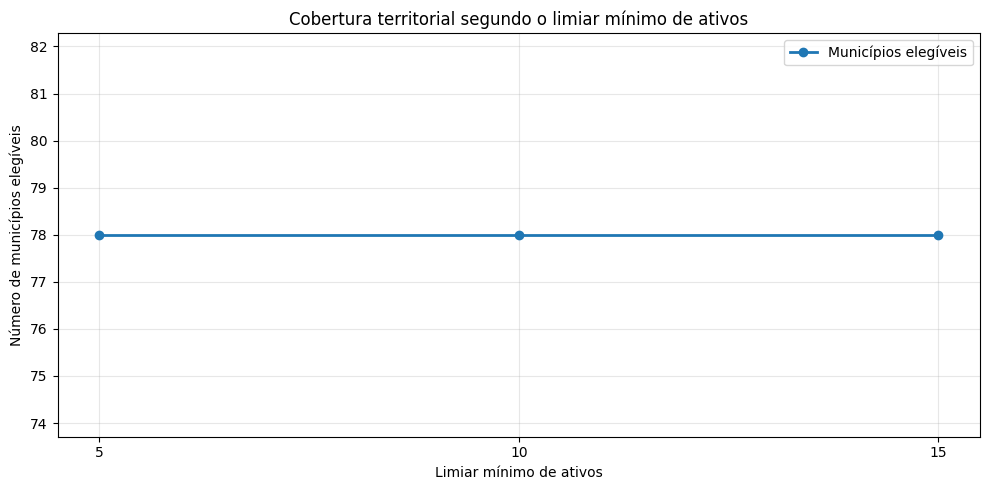

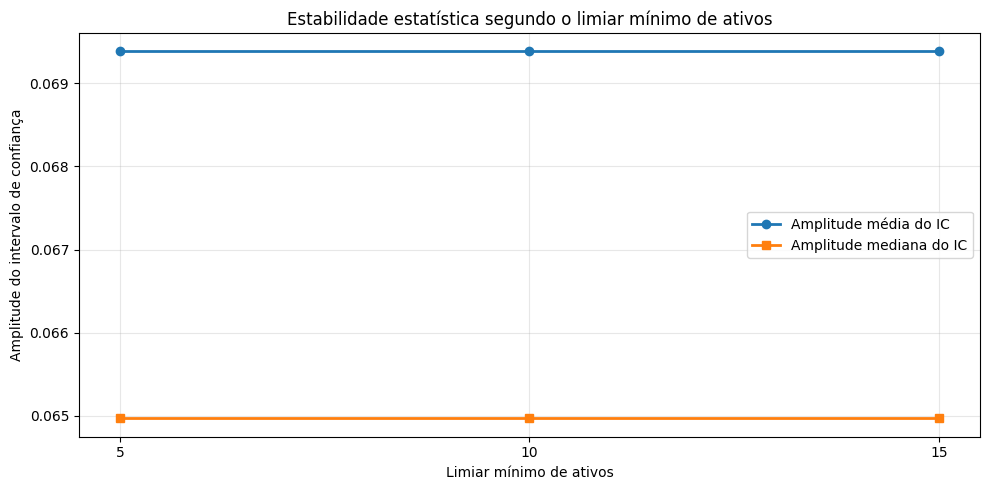


Arquivos salvos:
- /content/dados_output/10_analise_sensibilidade_limiares.csv
- /content/dados_output/11_top10_municipios_limiar_5.csv
- /content/dados_output/11_top10_municipios_limiar_10.csv
- /content/dados_output/11_top10_municipios_limiar_15.csv


In [33]:
# CARREGAMENTO DA BASE MUNICIPAL COM MÉTRICAS

agg_municipio_metricas = pd.read_parquet(
    DIR_SAIDAS / "08_agregado_municipal_com_metricas.parquet"
)

limiares = [5, 10, 15]

resultados_sensibilidade = []
tops_sensibilidade = {}

for limiar in limiares:
    df_tmp = agg_municipio_metricas.loc[
        agg_municipio_metricas["n_ativos"] >= limiar
    ].copy()

    resumo = {
        "min_ativos": limiar,
        "municipios_elegiveis": len(df_tmp),
        "percentual_cobertura_municipal": len(df_tmp) / len(agg_municipio_metricas),
        "n_ativos_total": int(df_tmp["n_ativos"].sum()),
        "media_ieep_bruto": df_tmp["ieep_bruto"].mean(),
        "mediana_ieep_bruto": df_tmp["ieep_bruto"].median(),
        "desvio_padrao_ieep_bruto": df_tmp["ieep_bruto"].std(),
        "media_ieep_estabilizado": df_tmp["ieep_estabilizado"].mean(),
        "mediana_ieep_estabilizado": df_tmp["ieep_estabilizado"].median(),
        "desvio_padrao_ieep_estabilizado": df_tmp["ieep_estabilizado"].std(),
        "amplitude_media_ic": df_tmp["ieep_ic_amplitude"].mean(),
        "amplitude_mediana_ic": df_tmp["ieep_ic_amplitude"].median(),
    }

    resultados_sensibilidade.append(resumo)

    tops_sensibilidade[limiar] = (
        df_tmp.sort_values(
            ["ieep_estabilizado", "n_ativos"],
            ascending=[False, False]
        )[
            [
                "Municipio_padronizado",
                "SRE_padronizada",
                "n_ativos",
                "n_excelencia",
                "ieep_bruto",
                "ieep_estabilizado",
                "ieep_ic_amplitude"
            ]
        ]
        .head(10)
        .reset_index(drop=True)
    )

df_sensibilidade = pd.DataFrame(resultados_sensibilidade)

print("=" * 78)
print("ANÁLISE DE SENSIBILIDADE DO IEEP POR VOLUMETRIA MÍNIMA")
print("=" * 78)

display(df_sensibilidade)

for limiar in limiares:
    print(f"\nTOP 10 MUNICÍPIOS POR IEEP ESTABILIZADO — CORTE >= {limiar} ATIVOS")
    print("-" * 78)
    display(tops_sensibilidade[limiar])

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    df_sensibilidade["min_ativos"],
    df_sensibilidade["municipios_elegiveis"],
    marker="o",
    linewidth=2,
    label="Municípios elegíveis"
)

ax.set_title("Cobertura territorial segundo o limiar mínimo de ativos")
ax.set_xlabel("Limiar mínimo de ativos")
ax.set_ylabel("Número de municípios elegíveis")
ax.set_xticks(limiares)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    df_sensibilidade["min_ativos"],
    df_sensibilidade["amplitude_media_ic"],
    marker="o",
    linewidth=2,
    label="Amplitude média do IC"
)

ax.plot(
    df_sensibilidade["min_ativos"],
    df_sensibilidade["amplitude_mediana_ic"],
    marker="s",
    linewidth=2,
    label="Amplitude mediana do IC"
)

ax.set_title("Estabilidade estatística segundo o limiar mínimo de ativos")
ax.set_xlabel("Limiar mínimo de ativos")
ax.set_ylabel("Amplitude do intervalo de confiança")
ax.set_xticks(limiares)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

# SALVAMENTO

df_sensibilidade.to_csv(
    DIR_SAIDAS / "10_analise_sensibilidade_limiares.csv",
    index=False,
    encoding="utf-8-sig"
)

for limiar in limiares:
    tops_sensibilidade[limiar].to_csv(
        DIR_SAIDAS / f"11_top10_municipios_limiar_{limiar}.csv",
        index=False,
        encoding="utf-8-sig"
    )

print("\nArquivos salvos:")
print(f"- {DIR_SAIDAS / '10_analise_sensibilidade_limiares.csv'}")
for limiar in limiares:
    print(f"- {DIR_SAIDAS / f'11_top10_municipios_limiar_{limiar}.csv'}")

COMPARAÇÃO ENTRE IEEP BRUTO E IEEP ESTABILIZADO
Média do delta (bruto - estabilizado): 0.002586
Mediana do delta (bruto - estabilizado): 0.002385
Média do |delta|: 0.002586
Mediana do |delta|: 0.002385
Maior |delta| observado: 0.009755
Menor |delta| observado: 0.000416

TOP 15 MUNICÍPIOS COM MAIOR DIFERENÇA ENTRE IEEP BRUTO E ESTABILIZADO
------------------------------------------------------------------------------


,Municipio_padronizado,SRE_padronizada,n_ativos,n_excelencia,ieep_bruto,ieep_estabilizado,delta_bruto_estabilizado,abs_delta_bruto_estabilizado,ieep_ic_amplitude
0,APIACA,SRE COMENDADORA JUREMA MORETZ SOHN,92,86,0.934783,0.925028,0.009755,0.009755,0.104828
1,BOM JESUS DO NORTE,SRE COMENDADORA JUREMA MORETZ SOHN,102,92,0.901961,0.894073,0.007888,0.007888,0.117000
2,ALTO RIO NOVO,SRE COLATINA,116,103,0.887931,0.881325,0.006606,0.006606,0.115661
3,DIVINO DE SAO LOURENCO,SRE COMENDADORA JUREMA MORETZ SOHN,119,106,0.890756,0.884243,0.006513,0.006513,0.113002
4,MUCURICI,SRE NOVA VENECIA,140,122,0.871429,0.866277,0.005151,0.005151,0.111186
5,MANTENOPOLIS,SRE BARRA DE SAO FRANCISCO,171,158,0.923977,0.918837,0.005140,0.005140,0.080749
6,RIO NOVO DO SUL,SRE CACHOEIRO DE ITAPEMIRIM,182,168,0.923077,0.918258,0.004819,0.004819,0.078593
7,SANTA LEOPOLDINA,SRE CARIACICA,140,119,0.850000,0.845298,0.004702,0.004702,0.118193
8,SAO JOSE DO CALCADO,SRE COMENDADORA JUREMA MORETZ SOHN,163,144,0.883436,0.878781,0.004655,0.004655,0.098974
9,PONTO BELO,SRE NOVA VENECIA,137,111,0.810219,0.806269,0.003950,0.003950,0.130622


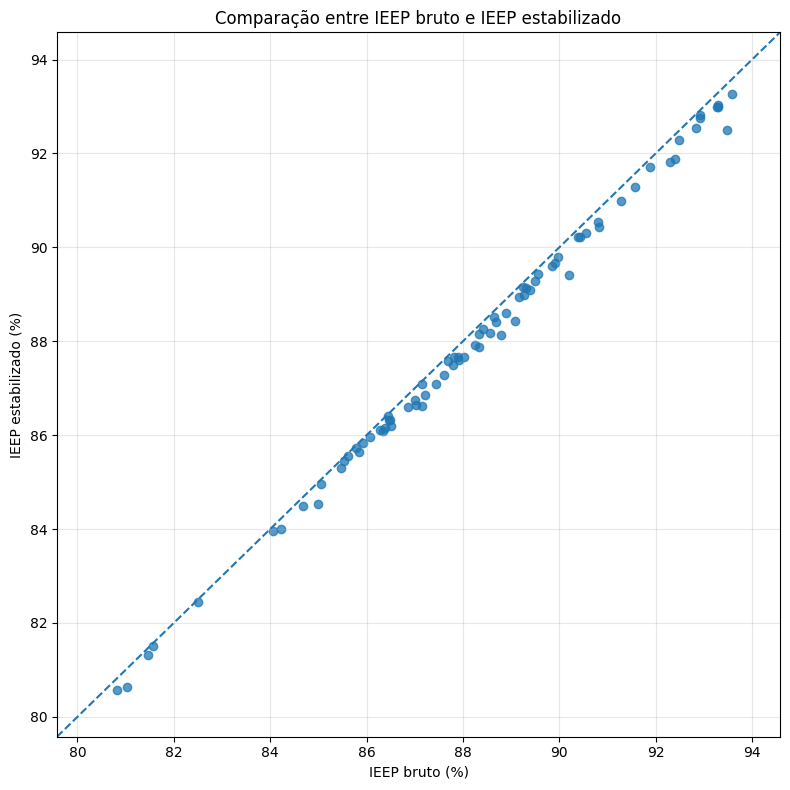

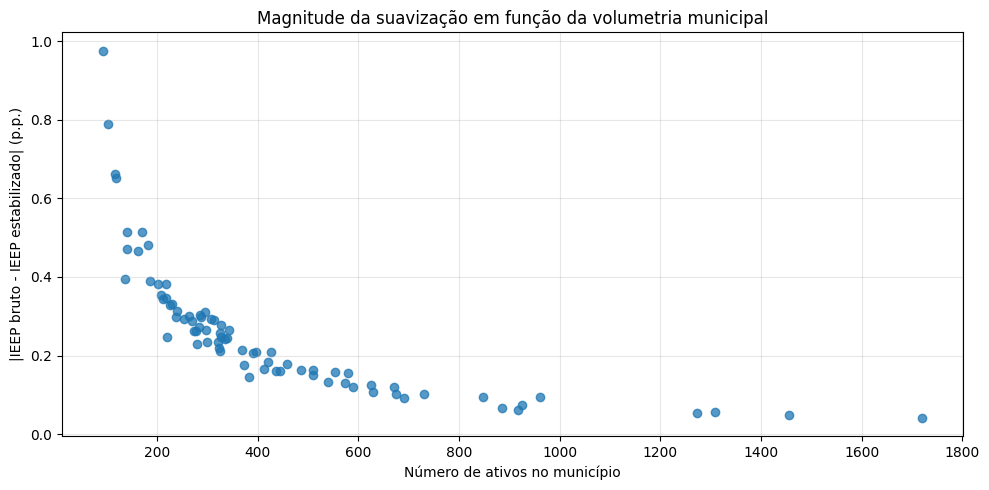


Arquivos salvos:
- /content/dados_output/12_agregado_municipal_metricas_comparadas.parquet
- /content/dados_output/13_municipios_maior_delta_bruto_estabilizado.csv


In [34]:
# CARREGAMENTO DA BASE MUNICIPAL COM MÉTRICAS

agg_municipio_metricas = pd.read_parquet(
    DIR_SAIDAS / "08_agregado_municipal_com_metricas.parquet"
).copy()


agg_municipio_metricas["delta_bruto_estabilizado"] = (
    agg_municipio_metricas["ieep_bruto"] - agg_municipio_metricas["ieep_estabilizado"]
)

agg_municipio_metricas["abs_delta_bruto_estabilizado"] = (
    agg_municipio_metricas["delta_bruto_estabilizado"].abs()
)

# Ranking dos municípios com maior diferença absoluta entre bruto e estabilizado
maiores_deltas = (
    agg_municipio_metricas.sort_values(
        ["abs_delta_bruto_estabilizado", "ieep_ic_amplitude"],
        ascending=[False, False]
    )[
        [
            "Municipio_padronizado",
            "SRE_padronizada",
            "n_ativos",
            "n_excelencia",
            "ieep_bruto",
            "ieep_estabilizado",
            "delta_bruto_estabilizado",
            "abs_delta_bruto_estabilizado",
            "ieep_ic_amplitude"
        ]
    ]
    .head(15)
    .reset_index(drop=True)
)

# Resumo global das diferenças
resumo_delta = {
    "media_delta": agg_municipio_metricas["delta_bruto_estabilizado"].mean(),
    "mediana_delta": agg_municipio_metricas["delta_bruto_estabilizado"].median(),
    "media_abs_delta": agg_municipio_metricas["abs_delta_bruto_estabilizado"].mean(),
    "mediana_abs_delta": agg_municipio_metricas["abs_delta_bruto_estabilizado"].median(),
    "max_abs_delta": agg_municipio_metricas["abs_delta_bruto_estabilizado"].max(),
    "min_abs_delta": agg_municipio_metricas["abs_delta_bruto_estabilizado"].min(),
}

print("=" * 78)
print("COMPARAÇÃO ENTRE IEEP BRUTO E IEEP ESTABILIZADO")
print("=" * 78)
print(f"Média do delta (bruto - estabilizado): {resumo_delta['media_delta']:.6f}")
print(f"Mediana do delta (bruto - estabilizado): {resumo_delta['mediana_delta']:.6f}")
print(f"Média do |delta|: {resumo_delta['media_abs_delta']:.6f}")
print(f"Mediana do |delta|: {resumo_delta['mediana_abs_delta']:.6f}")
print(f"Maior |delta| observado: {resumo_delta['max_abs_delta']:.6f}")
print(f"Menor |delta| observado: {resumo_delta['min_abs_delta']:.6f}")
print("=" * 78)

print("\nTOP 15 MUNICÍPIOS COM MAIOR DIFERENÇA ENTRE IEEP BRUTO E ESTABILIZADO")
print("-" * 78)
display(maiores_deltas)

# GRÁFICO 1: BRUTO VS ESTABILIZADO

fig, ax = plt.subplots(figsize=(8, 8))

ax.scatter(
    agg_municipio_metricas["ieep_bruto"] * 100,
    agg_municipio_metricas["ieep_estabilizado"] * 100,
    alpha=0.75
)

lim_inf = min(
    agg_municipio_metricas["ieep_bruto"].min(),
    agg_municipio_metricas["ieep_estabilizado"].min()
) * 100 - 1

lim_sup = max(
    agg_municipio_metricas["ieep_bruto"].max(),
    agg_municipio_metricas["ieep_estabilizado"].max()
) * 100 + 1

ax.plot([lim_inf, lim_sup], [lim_inf, lim_sup], linestyle="--", linewidth=1.5)

ax.set_title("Comparação entre IEEP bruto e IEEP estabilizado")
ax.set_xlabel("IEEP bruto (%)")
ax.set_ylabel("IEEP estabilizado (%)")
ax.set_xlim(lim_inf, lim_sup)
ax.set_ylim(lim_inf, lim_sup)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# GRÁFICO 2: DELTA ABSOLUTO VS NÚMERO DE ATIVOS

fig, ax = plt.subplots(figsize=(10, 5))

ax.scatter(
    agg_municipio_metricas["n_ativos"],
    agg_municipio_metricas["abs_delta_bruto_estabilizado"] * 100,
    alpha=0.75
)

ax.set_title("Magnitude da suavização em função da volumetria municipal")
ax.set_xlabel("Número de ativos no município")
ax.set_ylabel("|IEEP bruto - IEEP estabilizado| (p.p.)")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# SALVAMENTO

agg_municipio_metricas.to_parquet(
    DIR_SAIDAS / "12_agregado_municipal_metricas_comparadas.parquet",
    index=False
)

maiores_deltas.to_csv(
    DIR_SAIDAS / "13_municipios_maior_delta_bruto_estabilizado.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nArquivos salvos:")
print(f"- {DIR_SAIDAS / '12_agregado_municipal_metricas_comparadas.parquet'}")
print(f"- {DIR_SAIDAS / '13_municipios_maior_delta_bruto_estabilizado.csv'}")

## 9. Decomposição ocupacional do IEEP: Docência, Gestão Pedagógica e viés territorial

DECOMPOSIÇÃO OCUPACIONAL DO IEEP
Registros territoriais válidos: 0
Grupos ocupacionais considerados: Docência, Gestão Pedagógica

RESUMO POR SRE COM DECOMPOSIÇÃO OCUPACIONAL
------------------------------------------------------------------------------


,SRE_padronizada,n_ativos,ieep_bruto,ieep_estabilizado,ieep_docencia,ieep_gestao,vies_gestao_menos_docencia_pp
0,SRE COLATINA,4454,0.896947,0.896764,NaN,NaN,NaN
1,SRE NOVA VENECIA,3699,0.892674,0.892457,NaN,NaN,NaN
2,SRE BARRA DE SAO FRANCISCO,2134,0.888941,0.888572,NaN,NaN,NaN
3,SRE AFONSO CLAUDIO,2678,0.885362,0.885072,NaN,NaN,NaN
4,SRE COMENDADORA JUREMA MORETZ SOHN,3203,0.883859,0.883617,NaN,NaN,NaN
5,SRE CACHOEIRO DE ITAPEMIRIM,4902,0.878417,0.878263,NaN,NaN,NaN
6,SRE SAO MATEUS,2466,0.875507,0.875204,NaN,NaN,NaN
7,SRE CARAPINA,3009,0.868395,0.868153,NaN,NaN,NaN
8,SRE LINHARES,3154,0.867153,0.866924,NaN,NaN,NaN
9,SRE VILA VELHA,2715,0.849355,0.849109,NaN,NaN,NaN



TOP 15 MUNICÍPIOS COM MAIOR VIÉS OCUPACIONAL ABSOLUTO
------------------------------------------------------------------------------


,Municipio_padronizado,SRE_padronizada,n_ativos,ieep_estabilizado,ieep_docencia,ieep_gestao,vies_gestao_menos_docencia_pp


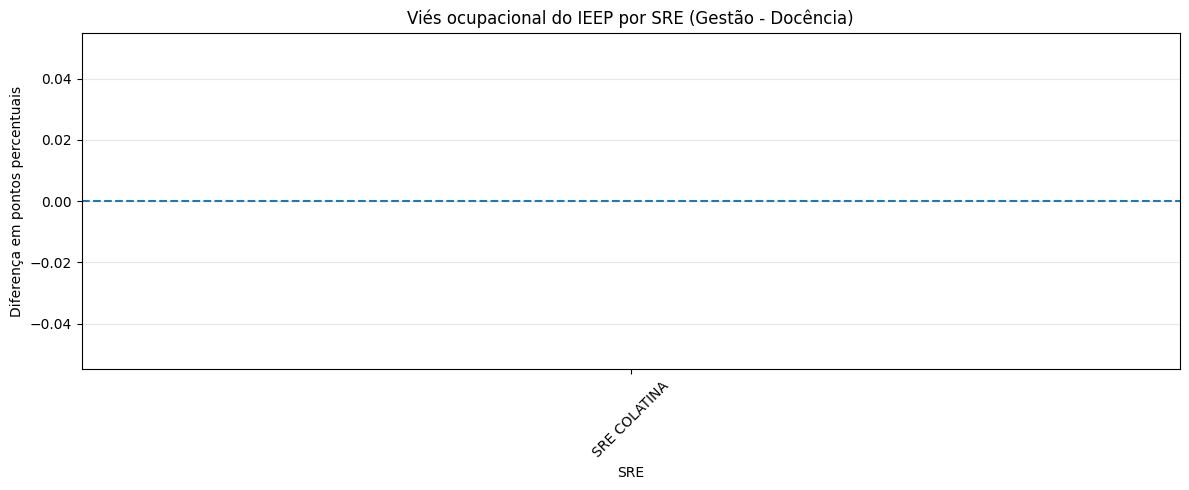


Arquivos salvos:
- /content/dados_output/14_agregado_municipal_com_decomposicao_ocupacional.parquet
- /content/dados_output/15_agregado_sre_com_decomposicao_ocupacional.parquet
- /content/dados_output/16_top15_municipios_vies_ocupacional.csv


In [35]:
base_geo = pd.read_parquet(
    DIR_SAIDAS / "05_base_territorial_valida.parquet"
).copy()

base_geo = base_geo[
    base_geo[COL_CARGO].isin(GRUPOS_COMBINADOS)
].copy()

base_geo["flg_excelencia"] = (
    base_geo[COL_PERSONA].eq(PERFIL_EXCELENCIA).astype(int)
)

print("=" * 78)
print("DECOMPOSIÇÃO OCUPACIONAL DO IEEP")
print("=" * 78)
print(f"Registros territoriais válidos: {len(base_geo):,}".replace(",", "."))
print("Grupos ocupacionais considerados:", ", ".join(GRUPOS_COMBINADOS))
print("=" * 78)

# AGREGAÇÃO MUNICIPAL POR GRUPO OCUPACIONAL

agg_municipio_cargo = (
    base_geo
    .groupby(["Municipio_padronizado", "SRE_padronizada", COL_CARGO], dropna=False)
    .agg(
        n_ativos=("flg_excelencia", "size"),
        n_excelencia=("flg_excelencia", "sum")
    )
    .reset_index()
)

agg_municipio_cargo["taxa_excelencia"] = (
    agg_municipio_cargo["n_excelencia"] / agg_municipio_cargo["n_ativos"]
)

# Pivot municipal
pivot_municipio = (
    agg_municipio_cargo
    .pivot_table(
        index=["Municipio_padronizado", "SRE_padronizada"],
        columns=COL_CARGO,
        values=["n_ativos", "n_excelencia", "taxa_excelencia"],
        aggfunc="first"
    )
)

pivot_municipio.columns = [
    f"{metric}_{cargo}".replace(" ", "_")
    for metric, cargo in pivot_municipio.columns
]

pivot_municipio = pivot_municipio.reset_index()

# Normalização de nomes esperados
rename_map = {
    "n_ativos_Docência": "n_docencia",
    "n_ativos_Gestão_Pedagógica": "n_gestao",
    "n_excelencia_Docência": "n_excelencia_docencia",
    "n_excelencia_Gestão_Pedagógica": "n_excelencia_gestao",
    "taxa_excelencia_Docência": "ieep_docencia",
    "taxa_excelencia_Gestão_Pedagógica": "ieep_gestao",
}
pivot_municipio = pivot_municipio.rename(columns=rename_map)

# Garantir colunas mesmo se algum grupo faltar em algum território
for col in [
    "n_docencia", "n_gestao",
    "n_excelencia_docencia", "n_excelencia_gestao",
    "ieep_docencia", "ieep_gestao"
]:
    if col not in pivot_municipio.columns:
        pivot_municipio[col] = np.nan

# Viés ocupacional em p.p. (gestão - docência)
pivot_municipio["vies_gestao_menos_docencia_pp"] = (
    (pivot_municipio["ieep_gestao"] - pivot_municipio["ieep_docencia"]) * 100
)

# Flags mínimas por grupo
pivot_municipio["flg_grupos_completos"] = (
    pivot_municipio["n_docencia"].fillna(0).ge(MIN_ATIVOS_MUNICIPIO) &
    pivot_municipio["n_gestao"].fillna(0).ge(MIN_ATIVOS_MUNICIPIO)
)

agg_sre_cargo = (
    base_geo
    .groupby(["SRE_padronizada", COL_CARGO], dropna=False)
    .agg(
        n_ativos=("flg_excelencia", "size"),
        n_excelencia=("flg_excelencia", "sum")
    )
    .reset_index()
)

agg_sre_cargo["taxa_excelencia"] = (
    agg_sre_cargo["n_excelencia"] / agg_sre_cargo["n_ativos"]
)

pivot_sre = (
    agg_sre_cargo
    .pivot_table(
        index=["SRE_padronizada"],
        columns=COL_CARGO,
        values=["n_ativos", "n_excelencia", "taxa_excelencia"],
        aggfunc="first"
    )
)

pivot_sre.columns = [
    f"{metric}_{cargo}".replace(" ", "_")
    for metric, cargo in pivot_sre.columns
]
pivot_sre = pivot_sre.reset_index().rename(columns=rename_map)

for col in [
    "n_docencia", "n_gestao",
    "n_excelencia_docencia", "n_excelencia_gestao",
    "ieep_docencia", "ieep_gestao"
]:
    if col not in pivot_sre.columns:
        pivot_sre[col] = np.nan

pivot_sre["vies_gestao_menos_docencia_pp"] = (
    (pivot_sre["ieep_gestao"] - pivot_sre["ieep_docencia"]) * 100
)

metricas_municipio = pd.read_parquet(
    DIR_SAIDAS / "12_agregado_municipal_metricas_comparadas.parquet"
).copy()

metricas_sre = pd.read_parquet(
    DIR_SAIDAS / "09_agregado_sre_com_metricas.parquet"
).copy()

municipio_final = metricas_municipio.merge(
    pivot_municipio,
    on=["Municipio_padronizado", "SRE_padronizada"],
    how="left"
)

sre_final = metricas_sre.merge(
    pivot_sre,
    on="SRE_padronizada",
    how="left"
)

top_sre_viés = (
    sre_final.sort_values("ieep_estabilizado", ascending=False)[[
        "SRE_padronizada",
        "n_ativos",
        "ieep_bruto",
        "ieep_estabilizado",
        "ieep_docencia",
        "ieep_gestao",
        "vies_gestao_menos_docencia_pp"
    ]]
    .reset_index(drop=True)
)

top_municipios_viés_abs = (
    municipio_final[
        municipio_final["flg_grupos_completos"].fillna(False)
    ]
    .assign(vies_abs=lambda df: df["vies_gestao_menos_docencia_pp"].abs())
    .sort_values(["vies_abs", "n_ativos"], ascending=[False, False])[
        [
            "Municipio_padronizado",
            "SRE_padronizada",
            "n_ativos",
            "ieep_estabilizado",
            "ieep_docencia",
            "ieep_gestao",
            "vies_gestao_menos_docencia_pp"
        ]
    ]
    .head(15)
    .reset_index(drop=True)
)

print("\nRESUMO POR SRE COM DECOMPOSIÇÃO OCUPACIONAL")
print("-" * 78)
display(top_sre_viés)

print("\nTOP 15 MUNICÍPIOS COM MAIOR VIÉS OCUPACIONAL ABSOLUTO")
print("-" * 78)
display(top_municipios_viés_abs)

graf_sre = sre_final.sort_values("ieep_estabilizado", ascending=False).copy()

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(
    graf_sre["SRE_padronizada"],
    graf_sre["vies_gestao_menos_docencia_pp"]
)

ax.axhline(0, linestyle="--", linewidth=1.5)
ax.set_title("Viés ocupacional do IEEP por SRE (Gestão - Docência)")
ax.set_xlabel("SRE")
ax.set_ylabel("Diferença em pontos percentuais")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

municipio_final.to_parquet(
    DIR_SAIDAS / "14_agregado_municipal_com_decomposicao_ocupacional.parquet",
    index=False
)

sre_final.to_parquet(
    DIR_SAIDAS / "15_agregado_sre_com_decomposicao_ocupacional.parquet",
    index=False
)

top_municipios_viés_abs.to_csv(
    DIR_SAIDAS / "16_top15_municipios_vies_ocupacional.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nArquivos salvos:")
print(f"- {DIR_SAIDAS / '14_agregado_municipal_com_decomposicao_ocupacional.parquet'}")
print(f"- {DIR_SAIDAS / '15_agregado_sre_com_decomposicao_ocupacional.parquet'}")
print(f"- {DIR_SAIDAS / '16_top15_municipios_vies_ocupacional.csv'}")

### 10. Auditoria dos grupos ocupacionais e correção da decomposição Docência × Gestão

In [36]:
if "base_territorial_valida" not in globals():
    arq_base_valida = DIR_SAIDAS / "05_base_territorial_valida.parquet"
    if not arq_base_valida.exists():
        raise FileNotFoundError(
            f"Base territorial válida não encontrada em: {arq_base_valida}"
        )
    base_territorial_valida = pd.read_parquet(arq_base_valida)

if COL_CARGO not in base_territorial_valida.columns:
    raise KeyError(f"Coluna {COL_CARGO} não encontrada na base territorial válida.")

freq_macro_cargo = (
    base_territorial_valida[COL_CARGO]
    .fillna("MISSING")
    .astype(str)
    .str.strip()
    .value_counts(dropna=False)
    .reset_index()
)

freq_macro_cargo.columns = ["Macro_Cargo_observado", "frequencia"]

print(f"Registros na base territorial válida: {len(base_territorial_valida):,}".replace(",", "."))
print(f"Valores únicos observados em {COL_CARGO}: {freq_macro_cargo.shape[0]}")
print("-" * 78)
display(freq_macro_cargo)

base_territorial_valida["Macro_Cargo_padronizado"] = (
    base_territorial_valida[COL_CARGO]
    .fillna("MISSING")
    .astype(str)
    .str.strip()
    .str.upper()
)

freq_macro_cargo_pad = (
    base_territorial_valida["Macro_Cargo_padronizado"]
    .value_counts(dropna=False)
    .reset_index()
)
freq_macro_cargo_pad.columns = ["Macro_Cargo_padronizado", "frequencia"]

print("-" * 78)
print("VALORES PADRONIZADOS (UPPERCASE)")
print("-" * 78)
display(freq_macro_cargo_pad)

GRUPOS_DOCENCIA_REAIS = [
    "DOCÊNCIA",
    "DOCENCIA"
]

GRUPOS_GESTAO_REAIS = [
    "GESTÃO PEDAGÓGICA",
    "GESTAO PEDAGOGICA"
]

base_territorial_valida["flg_docencia_tmp"] = (
    base_territorial_valida["Macro_Cargo_padronizado"].isin(GRUPOS_DOCENCIA_REAIS)
)

base_territorial_valida["flg_gestao_tmp"] = (
    base_territorial_valida["Macro_Cargo_padronizado"].isin(GRUPOS_GESTAO_REAIS)
)

n_doc = int(base_territorial_valida["flg_docencia_tmp"].sum())
n_ges = int(base_territorial_valida["flg_gestao_tmp"].sum())
n_total = len(base_territorial_valida)

print("-" * 78)
print("TESTE DE ADERÊNCIA DOS GRUPOS OCUPACIONAIS")
print("-" * 78)
print(f"Registros classificados como Docência: {n_doc:,}".replace(",", "."))
print(f"Registros classificados como Gestão Pedagógica: {n_ges:,}".replace(",", "."))
print(f"Registros fora desses dois grupos: {(n_total - n_doc - n_ges):,}".replace(",", "."))

freq_macro_cargo.to_csv(
    DIR_SAIDAS / "17_auditoria_macro_cargo_observado.csv",
    index=False,
    encoding="utf-8-sig"
)

freq_macro_cargo_pad.to_csv(
    DIR_SAIDAS / "18_auditoria_macro_cargo_padronizado.csv",
    index=False,
    encoding="utf-8-sig"
)

base_territorial_valida.to_parquet(
    DIR_SAIDAS / "19_base_territorial_valida_com_auditoria_ocupacional.parquet",
    index=False
)

print("-" * 78)
print("Arquivos salvos:")
print(f"- {DIR_SAIDAS / '17_auditoria_macro_cargo_observado.csv'}")
print(f"- {DIR_SAIDAS / '18_auditoria_macro_cargo_padronizado.csv'}")
print(f"- {DIR_SAIDAS / '19_base_territorial_valida_com_auditoria_ocupacional.parquet'}")

Registros na base territorial válida: 33.870
Valores únicos observados em Macro_Cargo: 4
------------------------------------------------------------------------------


,Macro_Cargo_observado,frequencia
0,1_DOCENCIA,18908
1,3_APOIO_ESCOLAR,7195
2,2_GESTAO_PEDAGOGICO,5878
3,0_NAO_INFORMADO_OUTROS,1889


------------------------------------------------------------------------------
VALORES PADRONIZADOS (UPPERCASE)
------------------------------------------------------------------------------


,Macro_Cargo_padronizado,frequencia
0,1_DOCENCIA,18908
1,3_APOIO_ESCOLAR,7195
2,2_GESTAO_PEDAGOGICO,5878
3,0_NAO_INFORMADO_OUTROS,1889


------------------------------------------------------------------------------
TESTE DE ADERÊNCIA DOS GRUPOS OCUPACIONAIS
------------------------------------------------------------------------------
Registros classificados como Docência: 0
Registros classificados como Gestão Pedagógica: 0
Registros fora desses dois grupos: 33.870
------------------------------------------------------------------------------
Arquivos salvos:
- /content/dados_output/17_auditoria_macro_cargo_observado.csv
- /content/dados_output/18_auditoria_macro_cargo_padronizado.csv
- /content/dados_output/19_base_territorial_valida_com_auditoria_ocupacional.parquet


### 11. Decomposição ocupacional corrigida do IEEP com recarga segura dos agregados

Registros territoriais válidos: 33.870
Docência identificada: 18.908
Gestão Pedagógica identificada: 5.878
Demais grupos fora da decomposição: 9.084
------------------------------------------------------------------------------
RESUMO POR SRE COM DECOMPOSIÇÃO OCUPACIONAL
------------------------------------------------------------------------------


,SRE_padronizada,n_ativos,ieep_bruto,ieep_estabilizado,n_docencia,ieep_docencia,n_gestao,ieep_gestao,vies_gestao_menos_docencia_pp
0,SRE COLATINA,4454,0.896947,0.896764,2903,0.904237,786,0.874046,-3.019119
1,SRE NOVA VENECIA,3699,0.892674,0.892457,2083,0.901104,611,0.844517,-5.658699
2,SRE BARRA DE SAO FRANCISCO,2134,0.888941,0.888572,1330,0.890977,304,0.871711,-1.926692
3,SRE AFONSO CLAUDIO,2678,0.885362,0.885072,1565,0.879233,518,0.888031,0.879766
4,SRE COMENDADORA JUREMA MORETZ SOHN,3203,0.883859,0.883617,1845,0.879675,444,0.873874,-0.580092
5,SRE CACHOEIRO DE ITAPEMIRIM,4902,0.878417,0.878263,2619,0.887362,941,0.867163,-2.019900
6,SRE SAO MATEUS,2466,0.875507,0.875204,1414,0.876945,416,0.843750,-3.319484
7,SRE CARAPINA,3009,0.868395,0.868153,1413,0.861996,451,0.784922,-7.707336
8,SRE LINHARES,3154,0.867153,0.866924,1722,0.876887,570,0.833333,-4.355401
9,SRE VILA VELHA,2715,0.849355,0.849109,1181,0.848434,577,0.814558,-3.387547


TOP 15 MUNICÍPIOS COM MAIOR VIÉS OCUPACIONAL ABSOLUTO
------------------------------------------------------------------------------


,Municipio_padronizado,SRE_padronizada,n_ativos,ieep_estabilizado,n_docencia,ieep_docencia,n_gestao,ieep_gestao,vies_gestao_menos_docencia_pp,abs_vies
0,PONTO BELO,SRE NOVA VENECIA,137,0.806269,74,0.824324,15,0.533333,-29.099099,29.099099
1,RIO BANANAL,SRE LINHARES,230,0.879303,160,0.918750,35,0.742857,-17.589286,17.589286
2,ALTO RIO NOVO,SRE COLATINA,116,0.881325,65,0.907692,21,0.761905,-14.578755,14.578755
3,VENDA NOVA DO IMIGRANTE,SRE AFONSO CLAUDIO,217,0.876717,101,0.871287,26,0.730769,-14.051790,14.051790
4,CONCEICAO DA BARRA,SRE SAO MATEUS,325,0.856334,193,0.886010,57,0.754386,-13.162440,13.162440
5,DORES DO RIO PRETO,SRE COMENDADORA JUREMA MORETZ SOHN,426,0.922792,329,0.948328,45,0.822222,-12.610605,12.610605
6,MUQUI,SRE CACHOEIRO DE ITAPEMIRIM,226,0.872828,124,0.870968,45,0.977778,10.681004,10.681004
7,PIUMA,SRE VILA VELHA,397,0.902194,143,0.923077,40,0.825000,-9.807692,9.807692
8,MARECHAL FLORIANO,SRE CARIACICA,211,0.868587,123,0.918699,34,0.823529,-9.516978,9.516978
9,MUCURICI,SRE NOVA VENECIA,140,0.866277,73,0.849315,18,0.944444,9.512938,9.512938


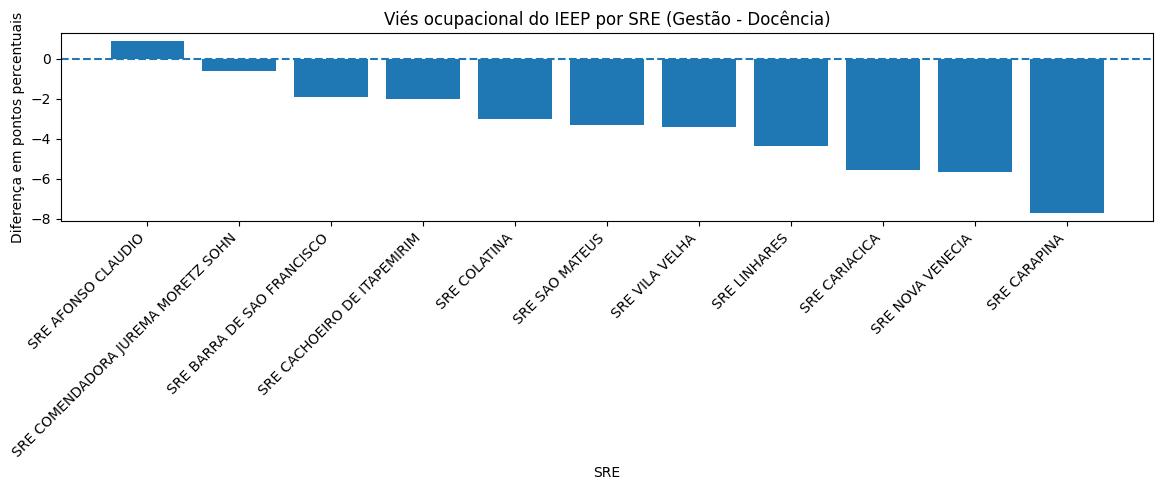

------------------------------------------------------------------------------
Arquivos salvos:
- /content/dados_output/14_agregado_municipal_com_decomposicao_ocupacional.parquet
- /content/dados_output/15_agregado_sre_com_decomposicao_ocupacional.parquet
- /content/dados_output/16_top15_municipios_vies_ocupacional.csv


In [37]:
# RECARGA SEGURA DOS ARQUIVOS NECESSÁRIOS

arq_base_valida = DIR_SAIDAS / "05_base_territorial_valida.parquet"
arq_agregado_municipal = DIR_SAIDAS / "08_agregado_municipal_com_metricas.parquet"
arq_agregado_sre = DIR_SAIDAS / "09_agregado_sre_com_metricas.parquet"

for arq in [arq_base_valida, arq_agregado_municipal, arq_agregado_sre]:
    if not arq.exists():
        raise FileNotFoundError(f"Arquivo necessário não encontrado: {arq}")

base_ocup = pd.read_parquet(arq_base_valida).copy()
agregado_municipal_com_metricas = pd.read_parquet(arq_agregado_municipal).copy()
agregado_sre_com_metricas = pd.read_parquet(arq_agregado_sre).copy()

base_ocup["Macro_Cargo_padronizado"] = (
    base_ocup[COL_CARGO]
    .fillna("MISSING")
    .astype(str)
    .str.strip()
    .str.upper()
)

# Perfil de excelência
base_ocup["flg_excelencia"] = (
    base_ocup[COL_PERSONA].astype(str).str.strip() == PERFIL_EXCELENCIA
).astype(int)

GRUPOS_DOCENCIA_REAIS = ["1_DOCENCIA"]
GRUPOS_GESTAO_REAIS = ["2_GESTAO_PEDAGOGICO"]

base_ocup["flg_docencia"] = base_ocup["Macro_Cargo_padronizado"].isin(GRUPOS_DOCENCIA_REAIS)
base_ocup["flg_gestao"] = base_ocup["Macro_Cargo_padronizado"].isin(GRUPOS_GESTAO_REAIS)

n_doc = int(base_ocup["flg_docencia"].sum())
n_ges = int(base_ocup["flg_gestao"].sum())

print(f"Registros territoriais válidos: {len(base_ocup):,}".replace(",", "."))
print(f"Docência identificada: {n_doc:,}".replace(",", "."))
print(f"Gestão Pedagógica identificada: {n_ges:,}".replace(",", "."))
print(f"Demais grupos fora da decomposição: {(len(base_ocup) - n_doc - n_ges):,}".replace(",", "."))
print("-" * 78)

def decompor_por_grupo(df, chave_agregacao, nome_flag_grupo):
    base_grupo = df[df[nome_flag_grupo]].copy()

    agrup = (
        base_grupo
        .groupby(chave_agregacao, dropna=False)
        .agg(
            n_ativos_grupo=("flg_excelencia", "size"),
            n_excelencia_grupo=("flg_excelencia", "sum")
        )
        .reset_index()
    )

    agrup["ieep_grupo"] = agrup["n_excelencia_grupo"] / agrup["n_ativos_grupo"]
    return agrup

sre_doc = decompor_por_grupo(base_ocup, "SRE_padronizada", "flg_docencia")
sre_doc = sre_doc.rename(columns={
    "n_ativos_grupo": "n_docencia",
    "n_excelencia_grupo": "n_docencia_excelencia",
    "ieep_grupo": "ieep_docencia"
})

sre_ges = decompor_por_grupo(base_ocup, "SRE_padronizada", "flg_gestao")
sre_ges = sre_ges.rename(columns={
    "n_ativos_grupo": "n_gestao",
    "n_excelencia_grupo": "n_gestao_excelencia",
    "ieep_grupo": "ieep_gestao"
})

df_sre_ocup = agregado_sre_com_metricas.merge(sre_doc, on="SRE_padronizada", how="left")
df_sre_ocup = df_sre_ocup.merge(sre_ges, on="SRE_padronizada", how="left")

df_sre_ocup["vies_gestao_menos_docencia_pp"] = (
    (df_sre_ocup["ieep_gestao"] - df_sre_ocup["ieep_docencia"]) * 100
)

mun_doc = decompor_por_grupo(
    base_ocup,
    ["Municipio_padronizado", "SRE_padronizada"],
    "flg_docencia"
)
mun_doc = mun_doc.rename(columns={
    "n_ativos_grupo": "n_docencia",
    "n_excelencia_grupo": "n_docencia_excelencia",
    "ieep_grupo": "ieep_docencia"
})

mun_ges = decompor_por_grupo(
    base_ocup,
    ["Municipio_padronizado", "SRE_padronizada"],
    "flg_gestao"
)
mun_ges = mun_ges.rename(columns={
    "n_ativos_grupo": "n_gestao",
    "n_excelencia_grupo": "n_gestao_excelencia",
    "ieep_grupo": "ieep_gestao"
})

df_municipio_ocup = agregado_municipal_com_metricas.merge(
    mun_doc,
    on=["Municipio_padronizado", "SRE_padronizada"],
    how="left"
)
df_municipio_ocup = df_municipio_ocup.merge(
    mun_ges,
    on=["Municipio_padronizado", "SRE_padronizada"],
    how="left"
)

df_municipio_ocup["vies_gestao_menos_docencia_pp"] = (
    (df_municipio_ocup["ieep_gestao"] - df_municipio_ocup["ieep_docencia"]) * 100
)

print("RESUMO POR SRE COM DECOMPOSIÇÃO OCUPACIONAL")
print("-" * 78)
display(
    df_sre_ocup[
        [
            "SRE_padronizada",
            "n_ativos",
            "ieep_bruto",
            "ieep_estabilizado",
            "n_docencia",
            "ieep_docencia",
            "n_gestao",
            "ieep_gestao",
            "vies_gestao_menos_docencia_pp"
        ]
    ]
    .sort_values("ieep_estabilizado", ascending=False)
    .reset_index(drop=True)
)

print("TOP 15 MUNICÍPIOS COM MAIOR VIÉS OCUPACIONAL ABSOLUTO")
print("-" * 78)

top_municipios_vies_abs = (
    df_municipio_ocup[
        [
            "Municipio_padronizado",
            "SRE_padronizada",
            "n_ativos",
            "ieep_estabilizado",
            "n_docencia",
            "ieep_docencia",
            "n_gestao",
            "ieep_gestao",
            "vies_gestao_menos_docencia_pp"
        ]
    ]
    .dropna(subset=["vies_gestao_menos_docencia_pp"])
    .assign(abs_vies=lambda x: x["vies_gestao_menos_docencia_pp"].abs())
    .sort_values("abs_vies", ascending=False)
    .head(15)
    .reset_index(drop=True)
)

display(top_municipios_vies_abs)

plot_sre = (
    df_sre_ocup[
        ["SRE_padronizada", "vies_gestao_menos_docencia_pp"]
    ]
    .dropna()
    .sort_values("vies_gestao_menos_docencia_pp", ascending=False)
)

plt.figure(figsize=(12, 5))
plt.bar(
    plot_sre["SRE_padronizada"],
    plot_sre["vies_gestao_menos_docencia_pp"]
)
plt.axhline(0, linestyle="--")
plt.title("Viés ocupacional do IEEP por SRE (Gestão - Docência)")
plt.xlabel("SRE")
plt.ylabel("Diferença em pontos percentuais")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

df_municipio_ocup.to_parquet(
    DIR_SAIDAS / "14_agregado_municipal_com_decomposicao_ocupacional.parquet",
    index=False
)

df_sre_ocup.to_parquet(
    DIR_SAIDAS / "15_agregado_sre_com_decomposicao_ocupacional.parquet",
    index=False
)

top_municipios_vies_abs.to_csv(
    DIR_SAIDAS / "16_top15_municipios_vies_ocupacional.csv",
    index=False,
    encoding="utf-8-sig"
)

print("-" * 78)
print("Arquivos salvos:")
print(f"- {DIR_SAIDAS / '14_agregado_municipal_com_decomposicao_ocupacional.parquet'}")
print(f"- {DIR_SAIDAS / '15_agregado_sre_com_decomposicao_ocupacional.parquet'}")
print(f"- {DIR_SAIDAS / '16_top15_municipios_vies_ocupacional.csv'}")

### 12. Robustez do viés ocupacional: filtragem por base mínima em Docência e Gestão

Critério mínimo por grupo ocupacional: 30
Municípios com viés ocupacional calculado: 78
Municípios com viés considerado robusto: 67
------------------------------------------------------------------------------
TOP 15 MUNICÍPIOS COM MAIOR VIÉS OCUPACIONAL ABSOLUTO (ROBUSTO)
------------------------------------------------------------------------------


,Municipio_padronizado,SRE_padronizada,n_ativos,ieep_estabilizado,n_docencia,ieep_docencia,n_gestao,ieep_gestao,vies_gestao_menos_docencia_pp,menor_base_ocupacional,abs_vies
0,RIO BANANAL,SRE LINHARES,230,0.879303,160,0.918750,35,0.742857,-17.589286,35,17.589286
1,CONCEICAO DA BARRA,SRE SAO MATEUS,325,0.856334,193,0.886010,57,0.754386,-13.162440,57,13.162440
2,DORES DO RIO PRETO,SRE COMENDADORA JUREMA MORETZ SOHN,426,0.922792,329,0.948328,45,0.822222,-12.610605,45,12.610605
3,MUQUI,SRE CACHOEIRO DE ITAPEMIRIM,226,0.872828,124,0.870968,45,0.977778,10.681004,45,10.681004
4,PIUMA,SRE VILA VELHA,397,0.902194,143,0.923077,40,0.825000,-9.807692,40,9.807692
5,MARECHAL FLORIANO,SRE CARIACICA,211,0.868587,123,0.918699,34,0.823529,-9.516978,34,9.516978
6,VIANA,SRE CARIACICA,219,0.805755,123,0.837398,47,0.744681,-9.271752,47,9.271752
7,JERONIMO MONTEIRO,SRE CACHOEIRO DE ITAPEMIRIM,296,0.932701,185,0.962162,39,0.871795,-9.036729,39,9.036729
8,NOVA VENECIA,SRE NOVA VENECIA,589,0.859591,341,0.894428,143,0.804196,-9.023235,143,9.023235
9,MARILANDIA,SRE COLATINA,326,0.905403,222,0.914414,40,0.825000,-8.941441,40,8.941441


RESUMO DESCRITIVO DO VIÉS OCUPACIONAL ROBUSTO
------------------------------------------------------------------------------


,estatistica
count,67.000000
mean,-2.841196
std,5.604920
min,-17.589286
25%,-6.790930
50%,-2.536462
75%,0.248968
max,10.681004


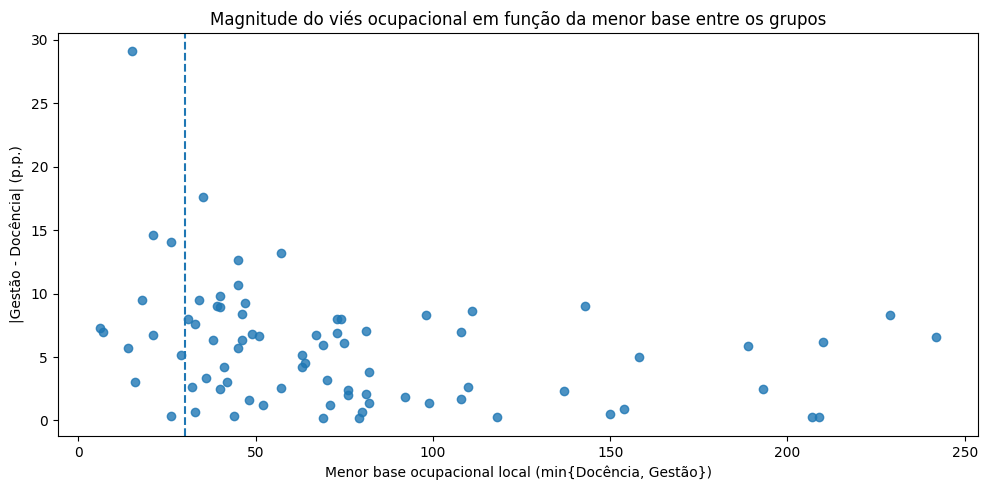

------------------------------------------------------------------------------
Arquivos salvos:
- /content/dados_output/20_agregado_municipal_com_vies_robusto.parquet
- /content/dados_output/21_top15_municipios_vies_robusto.csv


In [38]:
# PARÂMETRO DE ROBUSTEZ
MIN_GRUPO_OCUPACIONAL = 30

df_mun_vies = df_municipio_ocup.copy()
df_sre_vies = df_sre_ocup.copy()

df_mun_vies["flg_vies_robusto"] = (
    df_mun_vies["n_docencia"].fillna(0).ge(MIN_GRUPO_OCUPACIONAL) &
    df_mun_vies["n_gestao"].fillna(0).ge(MIN_GRUPO_OCUPACIONAL)
)

df_mun_vies["menor_base_ocupacional"] = df_mun_vies[
    ["n_docencia", "n_gestao"]
].min(axis=1)

print(f"Critério mínimo por grupo ocupacional: {MIN_GRUPO_OCUPACIONAL}")
print(f"Municípios com viés ocupacional calculado: {df_mun_vies['vies_gestao_menos_docencia_pp'].notna().sum()}")
print(f"Municípios com viés considerado robusto: {df_mun_vies['flg_vies_robusto'].sum()}")
print("-" * 78)

top_municipios_vies_robusto = (
    df_mun_vies[
        df_mun_vies["flg_vies_robusto"] &
        df_mun_vies["vies_gestao_menos_docencia_pp"].notna()
    ]
    .assign(abs_vies=lambda x: x["vies_gestao_menos_docencia_pp"].abs())
    .sort_values(["abs_vies", "menor_base_ocupacional"], ascending=[False, False])
    [
        [
            "Municipio_padronizado",
            "SRE_padronizada",
            "n_ativos",
            "ieep_estabilizado",
            "n_docencia",
            "ieep_docencia",
            "n_gestao",
            "ieep_gestao",
            "vies_gestao_menos_docencia_pp",
            "menor_base_ocupacional",
            "abs_vies"
        ]
    ]
    .head(15)
    .reset_index(drop=True)
)

print("TOP 15 MUNICÍPIOS COM MAIOR VIÉS OCUPACIONAL ABSOLUTO (ROBUSTO)")
print("-" * 78)
display(top_municipios_vies_robusto)

resumo_vies_robusto = (
    df_mun_vies[df_mun_vies["flg_vies_robusto"] & df_mun_vies["vies_gestao_menos_docencia_pp"].notna()]
    ["vies_gestao_menos_docencia_pp"]
    .describe()
    .to_frame("estatistica")
)

print("RESUMO DESCRITIVO DO VIÉS OCUPACIONAL ROBUSTO")
print("-" * 78)
display(resumo_vies_robusto)

plot_vies = df_mun_vies[
    df_mun_vies["vies_gestao_menos_docencia_pp"].notna()
].copy()

plt.figure(figsize=(10, 5))
plt.scatter(
    plot_vies["menor_base_ocupacional"],
    plot_vies["vies_gestao_menos_docencia_pp"].abs(),
    alpha=0.8
)
plt.axvline(MIN_GRUPO_OCUPACIONAL, linestyle="--")
plt.title("Magnitude do viés ocupacional em função da menor base entre os grupos")
plt.xlabel("Menor base ocupacional local (min{Docência, Gestão})")
plt.ylabel("|Gestão - Docência| (p.p.)")
plt.tight_layout()
plt.show()

df_mun_vies.to_parquet(
    DIR_SAIDAS / "20_agregado_municipal_com_vies_robusto.parquet",
    index=False
)

top_municipios_vies_robusto.to_csv(
    DIR_SAIDAS / "21_top15_municipios_vies_robusto.csv",
    index=False,
    encoding="utf-8-sig"
)

print("-" * 78)
print("Arquivos salvos:")
print(f"- {DIR_SAIDAS / '20_agregado_municipal_com_vies_robusto.parquet'}")
print(f"- {DIR_SAIDAS / '21_top15_municipios_vies_robusto.csv'}")

### 13. Síntese executiva da leitura territorial robusta

In [39]:
df_sre_exec = df_sre_ocup.copy()

# CLASSIFICAÇÕES INTERPRETATIVAS
def classificar_patamar_ieep(x):
    if pd.isna(x):
        return "Sem informação"
    elif x >= 0.89:
        return "Excelência territorial elevada"
    elif x >= 0.87:
        return "Excelência territorial intermediária-alta"
    elif x >= 0.85:
        return "Excelência territorial intermediária"
    else:
        return "Excelência territorial relativamente baixa"

def classificar_incerteza(x):
    if pd.isna(x):
        return "Sem informação"
    elif x <= 0.020:
        return "Baixa incerteza"
    elif x <= 0.030:
        return "Incerteza moderada"
    else:
        return "Incerteza elevada"

def classificar_vies(x):
    if pd.isna(x):
        return "Sem decomposição ocupacional"
    elif x >= 2:
        return "Gestão acima da Docência"
    elif x <= -2:
        return "Gestão abaixo da Docência"
    else:
        return "Equilíbrio relativo entre grupos"

df_sre_exec["patamar_ieep"] = df_sre_exec["ieep_estabilizado"].apply(classificar_patamar_ieep)
df_sre_exec["grau_incerteza"] = df_sre_exec["ieep_ic_amplitude"].apply(classificar_incerteza)
df_sre_exec["leitura_vies_ocupacional"] = df_sre_exec["vies_gestao_menos_docencia_pp"].apply(classificar_vies)

def gerar_leitura(row):
    sre = row["SRE_padronizada"]
    ieep = row["ieep_estabilizado"] * 100 if pd.notna(row["ieep_estabilizado"]) else np.nan
    amp = row["ieep_ic_amplitude"] * 100 if pd.notna(row["ieep_ic_amplitude"]) else np.nan
    vies = row["vies_gestao_menos_docencia_pp"]

    trecho_ieep = f"{sre} apresenta IEEP estabilizado de {ieep:.1f}\\%"
    trecho_inc = f"com {row['grau_incerteza'].lower()} (amplitude do IC = {amp:.1f} p.p.)"

    if pd.isna(vies):
        trecho_vies = "e sem decomposição ocupacional válida."
    else:
        if vies >= 2:
            trecho_vies = f"e viés ocupacional favorável à Gestão Pedagógica ({vies:.1f} p.p.)."
        elif vies <= -2:
            trecho_vies = f"e viés ocupacional desfavorável à Gestão Pedagógica ({vies:.1f} p.p.)."
        else:
            trecho_vies = f"e equilíbrio relativo entre Gestão e Docência ({vies:.1f} p.p.)."

    return f"{trecho_ieep}, {trecho_inc}, {trecho_vies}"

df_sre_exec["leitura_sintetica"] = df_sre_exec.apply(gerar_leitura, axis=1)

colunas_exec = [
    "SRE_padronizada",
    "n_ativos",
    "ieep_bruto",
    "ieep_estabilizado",
    "ieep_ic_amplitude",
    "n_docencia",
    "ieep_docencia",
    "n_gestao",
    "ieep_gestao",
    "vies_gestao_menos_docencia_pp",
    "patamar_ieep",
    "grau_incerteza",
    "leitura_vies_ocupacional",
    "leitura_sintetica"
]

tabela_executiva_sre = (
    df_sre_exec[colunas_exec]
    .sort_values("ieep_estabilizado", ascending=False)
    .reset_index(drop=True)
)

print("TABELA EXECUTIVA FINAL POR SRE")
print("-" * 78)
display(tabela_executiva_sre)

melhor_sre = tabela_executiva_sre.iloc[0]
pior_sre = tabela_executiva_sre.iloc[-1]

sre_maior_incerteza = tabela_executiva_sre.sort_values("ieep_ic_amplitude", ascending=False).iloc[0]
sre_maior_vies_abs = tabela_executiva_sre.assign(
    abs_vies=lambda x: x["vies_gestao_menos_docencia_pp"].abs()
).sort_values("abs_vies", ascending=False).iloc[0]

print("\nDESTAQUES AUTOMÁTICOS")
print("-" * 78)
print(f"Maior IEEP estabilizado: {melhor_sre['SRE_padronizada']} ({melhor_sre['ieep_estabilizado']*100:.2f}%)")
print(f"Menor IEEP estabilizado: {pior_sre['SRE_padronizada']} ({pior_sre['ieep_estabilizado']*100:.2f}%)")
print(f"Maior incerteza: {sre_maior_incerteza['SRE_padronizada']} (IC amplitude = {sre_maior_incerteza['ieep_ic_amplitude']*100:.2f} p.p.)")
print(f"Maior viés ocupacional absoluto: {sre_maior_vies_abs['SRE_padronizada']} ({sre_maior_vies_abs['vies_gestao_menos_docencia_pp']:.2f} p.p.)")

tabela_executiva_sre.to_csv(
    DIR_SAIDAS / "22_tabela_executiva_sre.csv",
    index=False,
    encoding="utf-8-sig"
)

tabela_executiva_sre.to_parquet(
    DIR_SAIDAS / "22_tabela_executiva_sre.parquet",
    index=False
)

print("-" * 78)
print("Arquivos salvos:")
print(f"- {DIR_SAIDAS / '22_tabela_executiva_sre.csv'}")
print(f"- {DIR_SAIDAS / '22_tabela_executiva_sre.parquet'}")

TABELA EXECUTIVA FINAL POR SRE
------------------------------------------------------------------------------


,SRE_padronizada,n_ativos,ieep_bruto,ieep_estabilizado,ieep_ic_amplitude,n_docencia,ieep_docencia,n_gestao,ieep_gestao,vies_gestao_menos_docencia_pp,patamar_ieep,grau_incerteza,leitura_vies_ocupacional,leitura_sintetica
0,SRE COLATINA,4454,0.896947,0.896764,0.017863,2903,0.904237,786,0.874046,-3.019119,Excelência territorial elevada,Baixa incerteza,Gestão abaixo da Docência,SRE COLATINA apresenta IEEP estabilizado de 89...
1,SRE NOVA VENECIA,3699,0.892674,0.892457,0.019956,2083,0.901104,611,0.844517,-5.658699,Excelência territorial elevada,Baixa incerteza,Gestão abaixo da Docência,SRE NOVA VENECIA apresenta IEEP estabilizado d...
2,SRE BARRA DE SAO FRANCISCO,2134,0.888941,0.888572,0.026675,1330,0.890977,304,0.871711,-1.926692,Excelência territorial intermediária-alta,Incerteza moderada,Equilíbrio relativo entre grupos,SRE BARRA DE SAO FRANCISCO apresenta IEEP esta...
3,SRE AFONSO CLAUDIO,2678,0.885362,0.885072,0.024140,1565,0.879233,518,0.888031,0.879766,Excelência territorial intermediária-alta,Incerteza moderada,Equilíbrio relativo entre grupos,SRE AFONSO CLAUDIO apresenta IEEP estabilizado...
4,SRE COMENDADORA JUREMA MORETZ SOHN,3203,0.883859,0.883617,0.022197,1845,0.879675,444,0.873874,-0.580092,Excelência territorial intermediária-alta,Incerteza moderada,Equilíbrio relativo entre grupos,SRE COMENDADORA JUREMA MORETZ SOHN apresenta I...
5,SRE CACHOEIRO DE ITAPEMIRIM,4902,0.878417,0.878263,0.018299,2619,0.887362,941,0.867163,-2.019900,Excelência territorial intermediária-alta,Baixa incerteza,Gestão abaixo da Docência,SRE CACHOEIRO DE ITAPEMIRIM apresenta IEEP est...
6,SRE SAO MATEUS,2466,0.875507,0.875204,0.026066,1414,0.876945,416,0.843750,-3.319484,Excelência territorial intermediária-alta,Incerteza moderada,Gestão abaixo da Docência,SRE SAO MATEUS apresenta IEEP estabilizado de ...
7,SRE CARAPINA,3009,0.868395,0.868153,0.024161,1413,0.861996,451,0.784922,-7.707336,Excelência territorial intermediária,Incerteza moderada,Gestão abaixo da Docência,SRE CARAPINA apresenta IEEP estabilizado de 86...
8,SRE LINHARES,3154,0.867153,0.866924,0.023693,1722,0.876887,570,0.833333,-4.355401,Excelência territorial intermediária,Incerteza moderada,Gestão abaixo da Docência,SRE LINHARES apresenta IEEP estabilizado de 86...
9,SRE VILA VELHA,2715,0.849355,0.849109,0.026909,1181,0.848434,577,0.814558,-3.387547,Excelência territorial relativamente baixa,Incerteza moderada,Gestão abaixo da Docência,SRE VILA VELHA apresenta IEEP estabilizado de ...



DESTAQUES AUTOMÁTICOS
------------------------------------------------------------------------------
Maior IEEP estabilizado: SRE COLATINA (89.68%)
Menor IEEP estabilizado: SRE CARIACICA (83.13%)
Maior incerteza: SRE CARIACICA (IC amplitude = 3.84 p.p.)
Maior viés ocupacional absoluto: SRE CARAPINA (-7.71 p.p.)
------------------------------------------------------------------------------
Arquivos salvos:
- /content/dados_output/22_tabela_executiva_sre.csv
- /content/dados_output/22_tabela_executiva_sre.parquet


### 14. Consolidação interpretativa final da análise geoespacial robusta

In [40]:

import pandas as pd

caminho_tabela_sre = DIR_SAIDAS / "22_tabela_executiva_sre.parquet"
caminho_municipios_metricas = DIR_SAIDAS / "12_agregado_municipal_metricas_comparadas.parquet"
caminho_municipios_vies_robusto = DIR_SAIDAS / "20_agregado_municipal_com_vies_robusto.parquet"

if not caminho_tabela_sre.exists():
    raise FileNotFoundError(f"Arquivo não encontrado: {caminho_tabela_sre}")

if not caminho_municipios_metricas.exists():
    raise FileNotFoundError(f"Arquivo não encontrado: {caminho_municipios_metricas}")

if not caminho_municipios_vies_robusto.exists():
    raise FileNotFoundError(f"Arquivo não encontrado: {caminho_municipios_vies_robusto}")

tabela_executiva_sre = pd.read_parquet(caminho_tabela_sre)
df_municipios_metricas = pd.read_parquet(caminho_municipios_metricas)
df_municipios_vies_robusto = pd.read_parquet(caminho_municipios_vies_robusto)

# RECUPERAÇÃO DOS PRINCIPAIS INDICADORES
tabela_executiva_sre = tabela_executiva_sre.sort_values(
    "ieep_estabilizado", ascending=False
).reset_index(drop=True)

melhor_sre = tabela_executiva_sre.iloc[0]
pior_sre = tabela_executiva_sre.iloc[-1]

sre_maior_incerteza = tabela_executiva_sre.sort_values(
    "ieep_ic_amplitude", ascending=False
).iloc[0]

sre_maior_vies_abs = (
    tabela_executiva_sre
    .assign(abs_vies=lambda x: x["vies_gestao_menos_docencia_pp"].abs())
    .sort_values("abs_vies", ascending=False)
    .iloc[0]
)

n_municipios_total = df_municipios_metricas["Municipio_padronizado"].nunique()
n_municipios_robustos = df_municipios_vies_robusto.loc[
    df_municipios_vies_robusto["menor_base_ocupacional"] >= 30,
    "Municipio_padronizado"
].nunique()

media_delta = float(df_municipios_metricas["delta_bruto_estabilizado"].mean() * 100)
max_delta = float(df_municipios_metricas["abs_delta_bruto_estabilizado"].max() * 100)

vies_robusto = df_municipios_vies_robusto.loc[
    df_municipios_vies_robusto["menor_base_ocupacional"] >= 30,
    "vies_gestao_menos_docencia_pp"
].dropna()

media_vies_robusto = float(vies_robusto.mean()) if len(vies_robusto) > 0 else float("nan")
mediana_vies_robusto = float(vies_robusto.median()) if len(vies_robusto) > 0 else float("nan")

texto_final = f"""
A análise geoespacial robusta da Rota B confirmou que a distribuição territorial do engajamento e eficiência proporcional
não é homogênea no estado. Considerando o IEEP estabilizado como métrica principal, a SRE com melhor
desempenho relativo foi {melhor_sre['SRE_padronizada']}, com {melhor_sre['ieep_estabilizado']*100:.2f}%,
enquanto a menor taxa foi observada em {pior_sre['SRE_padronizada']}, com {pior_sre['ieep_estabilizado']*100:.2f}%.

Do ponto de vista da precisão estatística, a maior incerteza foi registrada em
{sre_maior_incerteza['SRE_padronizada']}, cuja amplitude do intervalo de confiança atingiu
{sre_maior_incerteza['ieep_ic_amplitude']*100:.2f} pontos percentuais. Em contrapartida, as SREs de maior
volumetria apresentaram intervalos mais estreitos, reforçando a estabilidade comparativa dos resultados
macrorregionais.

A análise de sensibilidade mostrou que a cobertura territorial permaneceu integral entre os limiares de
5, 10 e 15 ativos, indicando que, nesta base específica, a escolha do limiar mínimo não alterou a presença
dos {n_municipios_total} municípios na análise. Isso sugere uma malha observacional suficientemente densa
para sustentar a comparação municipal sem perda de cobertura geográfica.

A estabilização empírico-bayesiana produziu ajustes modestos nas taxas brutas, com diferença média de
{media_delta:.3f} pontos percentuais e diferença máxima de {max_delta:.3f} pontos percentuais. Esse achado
indica que a suavização não alterou substantivamente a hierarquia territorial, mas contribuiu para reduzir
a superinterpretação de valores extremos em localidades de menor base.

Na decomposição ocupacional, observou-se que o viés entre Gestão Pedagógica e Docência não se distribui de
forma neutra. A SRE com maior viés ocupacional absoluto foi {sre_maior_vies_abs['SRE_padronizada']},
com {sre_maior_vies_abs['vies_gestao_menos_docencia_pp']:.2f} pontos percentuais. Entre os municípios com
base ocupacional mínima robusta, totalizando {n_municipios_robustos} casos, a média do viés foi de
{media_vies_robusto:.2f} p.p. e a mediana de {mediana_vies_robusto:.2f} p.p., sugerindo predominância de
desempenho relativamente inferior da Gestão Pedagógica em comparação à Docência em parte substantiva do
território analisado.

Em síntese, a versão robusta do IEEP amplia a confiabilidade interpretativa da análise geoespacial ao combinar
comparabilidade territorial, controle da incerteza e decomposição ocupacional. Com isso, os resultados deixam
de operar apenas como ranking descritivo e passam a constituir um instrumento analítico mais consistente para
subsidiar decisões focalizadas da política pública de formação continuada.
""".strip()

print(texto_final)

# SALVAMENTO
with open(DIR_SAIDAS / "23_consolidacao_interpretativa_final.txt", "w", encoding="utf-8") as f:
    f.write(texto_final)

print("-" * 78)
print("Arquivo salvo:")
print(f"- {DIR_SAIDAS / '23_consolidacao_interpretativa_final.txt'}")

A análise geoespacial robusta da Rota B confirmou que a distribuição territorial do engajamento e eficiência proporcional
não é homogênea no estado. Considerando o IEEP estabilizado como métrica principal, a SRE com melhor
desempenho relativo foi SRE COLATINA, com 89.68%,
enquanto a menor taxa foi observada em SRE CARIACICA, com 83.13%.

Do ponto de vista da precisão estatística, a maior incerteza foi registrada em
SRE CARIACICA, cuja amplitude do intervalo de confiança atingiu
3.84 pontos percentuais. Em contrapartida, as SREs de maior
volumetria apresentaram intervalos mais estreitos, reforçando a estabilidade comparativa dos resultados
macrorregionais.

A análise de sensibilidade mostrou que a cobertura territorial permaneceu integral entre os limiares de
5, 10 e 15 ativos, indicando que, nesta base específica, a escolha do limiar mínimo não alterou a presença
dos 78 municípios na análise. Isso sugere uma malha observacional suficientemente densa
para sustentar a comparação municipa

### 15. Fechamento do notebook e exportação dos artefatos finais

In [41]:
from pathlib import Path
import pandas as pd

arq_sre = DIR_SAIDAS / "22_tabela_executiva_sre.parquet"
arq_vies_robusto = DIR_SAIDAS / "20_agregado_municipal_com_vies_robusto.parquet"
arq_consolidacao = DIR_SAIDAS / "23_consolidacao_interpretativa_final.txt"

if not arq_sre.exists():
    raise FileNotFoundError(f"Arquivo não encontrado: {arq_sre}")
if not arq_vies_robusto.exists():
    raise FileNotFoundError(f"Arquivo não encontrado: {arq_vies_robusto}")
if not arq_consolidacao.exists():
    raise FileNotFoundError(f"Arquivo não encontrado: {arq_consolidacao}")

tabela_executiva_sre = pd.read_parquet(arq_sre)
df_municipios_vies_robusto = pd.read_parquet(arq_vies_robusto)

with open(arq_consolidacao, "r", encoding="utf-8") as f:
    consolidacao_txt = f.read()

top5_sre = tabela_executiva_sre.sort_values(
    "ieep_estabilizado", ascending=False
).head(5).copy()

top10_vies_robusto = (
    df_municipios_vies_robusto.loc[
        df_municipios_vies_robusto["menor_base_ocupacional"] >= 30
    ]
    .assign(abs_vies=lambda x: x["vies_gestao_menos_docencia_pp"].abs())
    .sort_values("abs_vies", ascending=False)
    .head(10)
    .copy()
)

top5_sre_csv = DIR_SAIDAS / "24_top5_sre_ieep_estabilizado.csv"
top10_vies_csv = DIR_SAIDAS / "25_top10_municipios_vies_robusto.csv"

top5_sre.to_csv(top5_sre_csv, index=False, encoding="utf-8-sig")
top10_vies_robusto.to_csv(top10_vies_csv, index=False, encoding="utf-8-sig")

melhor_sre = tabela_executiva_sre.sort_values("ieep_estabilizado", ascending=False).iloc[0]
pior_sre = tabela_executiva_sre.sort_values("ieep_estabilizado", ascending=True).iloc[0]
maior_incerteza = tabela_executiva_sre.sort_values("ieep_ic_amplitude", ascending=False).iloc[0]
maior_vies = tabela_executiva_sre.iloc[
    tabela_executiva_sre["vies_gestao_menos_docencia_pp"].abs().argmax()
]

n_municipios_robustos = (
    df_municipios_vies_robusto.loc[
        df_municipios_vies_robusto["menor_base_ocupacional"] >= 30,
        "Municipio_padronizado"
    ]
    .nunique()
)

media_vies_robusto = (
    df_municipios_vies_robusto.loc[
        df_municipios_vies_robusto["menor_base_ocupacional"] >= 30,
        "vies_gestao_menos_docencia_pp"
    ]
    .mean()
)

latex_final = rf"""
\noindent A versão robusta da análise geoespacial da Rota B confirmou que a distribuição territorial do engajamento e eficiência proporcional não é homogênea na rede estadual. Considerando o IEEP estabilizado como métrica principal, a \textit{{{melhor_sre['SRE_padronizada']}}} apresentou o maior desempenho relativo, com \textbf{{{melhor_sre['ieep_estabilizado']*100:.2f}\%}}, enquanto a menor taxa foi observada na \textit{{{pior_sre['SRE_padronizada']}}}, com \textbf{{{pior_sre['ieep_estabilizado']*100:.2f}\%}}.

\noindent Do ponto de vista da precisão estatística, a maior amplitude de intervalo de confiança foi registrada na \textit{{{maior_incerteza['SRE_padronizada']}}}, atingindo \textbf{{{maior_incerteza['ieep_ic_amplitude']*100:.2f} p.p.}}. Em contraste, as SREs de maior volumetria apresentaram intervalos mais estreitos, reforçando a estabilidade comparativa dos resultados macrorregionais.

\noindent A análise de sensibilidade mostrou que a cobertura territorial permaneceu integral entre os limiares de 5, 10 e 15 ativos, preservando os \textbf{{78 municípios}} na análise. Esse resultado indica que, nesta base específica, a malha observacional ativa mostrou-se suficientemente densa para sustentar comparações municipais sem perda de cobertura geográfica.

\noindent A estabilização empírico-bayesiana produziu ajustes modestos nas taxas brutas, atenuando oscilações locais sem alterar substantivamente a hierarquia territorial observada. Em termos substantivos, isso reforça que a suavização operou como mecanismo de robustez inferencial, e não como transformação arbitrária da estrutura empírica dos dados.

\noindent Na decomposição ocupacional, observou-se que o viés entre Gestão Pedagógica e Docência não se distribui de forma neutra no território. A maior discrepância macrorregional foi observada na \textit{{{maior_vies['SRE_padronizada']}}}, com viés de \textbf{{{maior_vies['vies_gestao_menos_docencia_pp']:.2f} p.p.}}. Entre os municípios com base ocupacional mínima robusta, totalizando \textbf{{{n_municipios_robustos}}} casos, a média do viés foi de \textbf{{{media_vies_robusto:.2f} p.p.}}, sugerindo predominância relativa de desempenho inferior da Gestão Pedagógica em comparação à Docência em parte substantiva da rede analisada.

\noindent Em síntese, a reformulação metodológica do IEEP ampliou a confiabilidade interpretativa da análise geoespacial ao combinar comparabilidade territorial, controle explícito da incerteza, estabilização de proporções e decomposição ocupacional. Com isso, os resultados deixam de operar apenas como \textit{{ranking}} descritivo e passam a constituir um instrumento analítico mais consistente para subsidiar decisões focalizadas na política pública de formação continuada \cite{{cerezo2024reviewing, guimaraes2025bigdata}}.
""".strip()

arq_latex = DIR_SAIDAS / "26_bloco_latex_fechamento_geoespacial.txt"
with open(arq_latex, "w", encoding="utf-8") as f:
    f.write(latex_final)

print("Arquivos finais gerados com sucesso:")
print(f"- {top5_sre_csv}")
print(f"- {top10_vies_csv}")
print(f"- {arq_latex}")

print("\n" + "-" * 78)
print("PRÉVIA DO BLOCO LATEX FINAL")
print("-" * 78)
print(latex_final[:3000])

Arquivos finais gerados com sucesso:
- /content/dados_output/24_top5_sre_ieep_estabilizado.csv
- /content/dados_output/25_top10_municipios_vies_robusto.csv
- /content/dados_output/26_bloco_latex_fechamento_geoespacial.txt

------------------------------------------------------------------------------
PRÉVIA DO BLOCO LATEX FINAL
------------------------------------------------------------------------------
\noindent A versão robusta da análise geoespacial da Rota B confirmou que a distribuição territorial do engajamento e eficiência proporcional não é homogênea na rede estadual. Considerando o IEEP estabilizado como métrica principal, a \textit{SRE COLATINA} apresentou o maior desempenho relativo, com \textbf{89.68\%}, enquanto a menor taxa foi observada na \textit{SRE CARIACICA}, com \textbf{83.13\%}.

\noindent Do ponto de vista da precisão estatística, a maior amplitude de intervalo de confiança foi registrada na \textit{SRE CARIACICA}, atingindo \textbf{3.84 p.p.}. Em contraste, as 

### 16. Figura final macrorregional: IEEP estabilizado por SRE

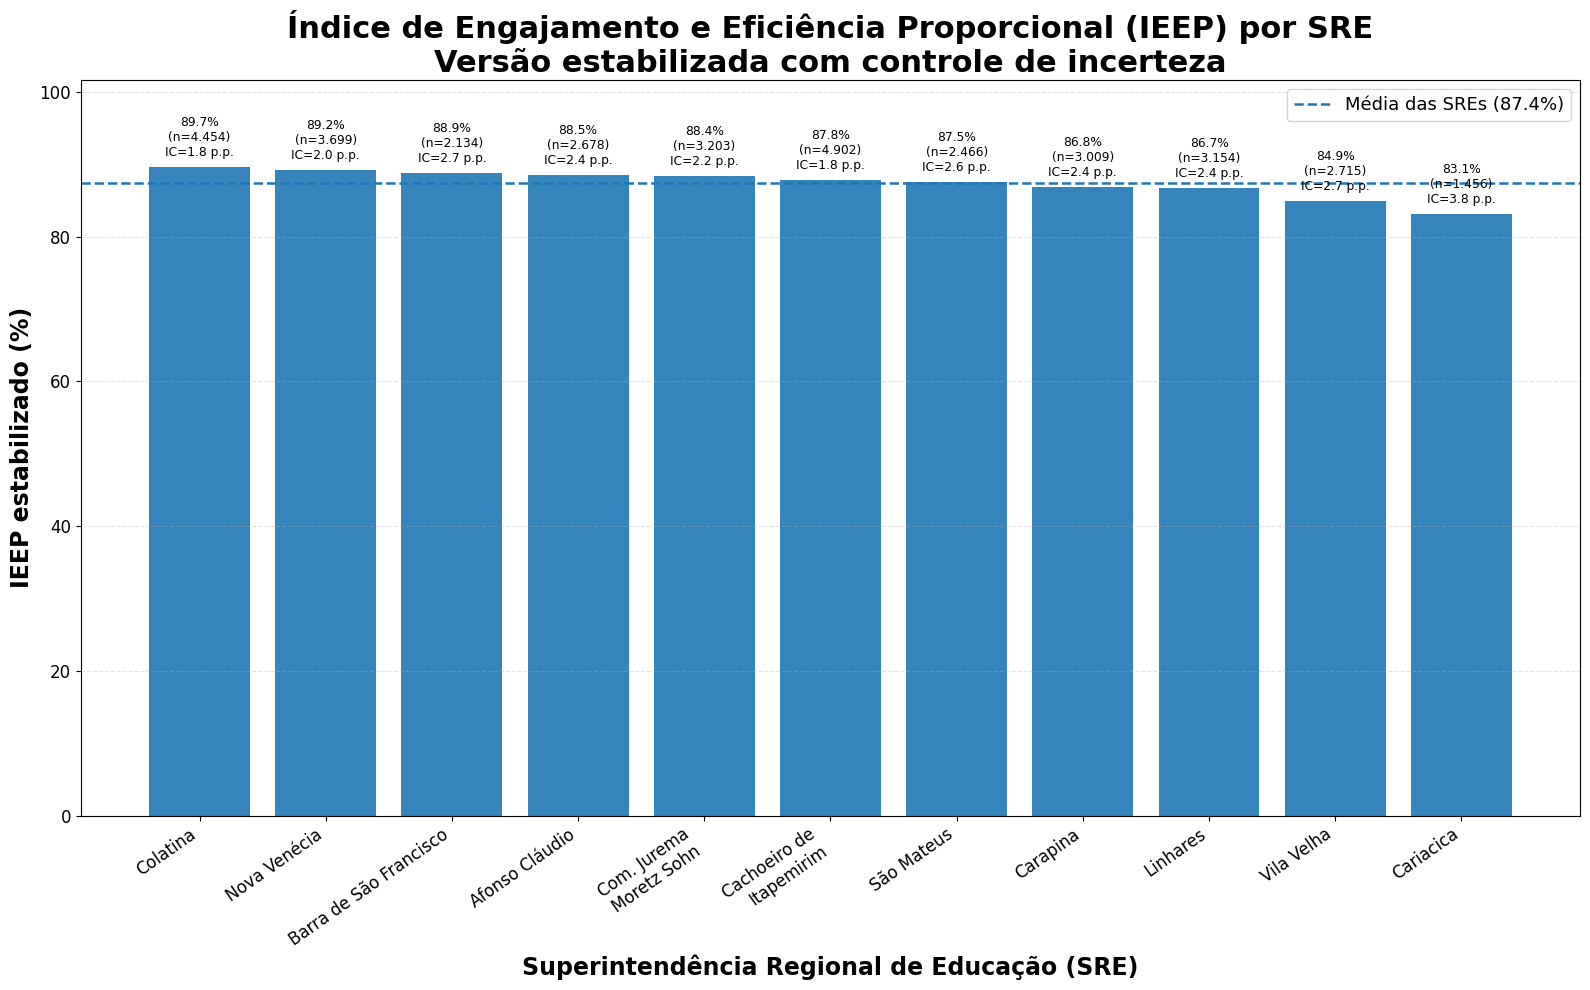

Arquivo salvo:
- /content/dados_output/27_figura_ieep_estabilizado_por_sre.png


In [42]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


arq_sre = DIR_SAIDAS / "22_tabela_executiva_sre.parquet"
if not arq_sre.exists():
    raise FileNotFoundError(f"Arquivo não encontrado: {arq_sre}")

df_sre_final = pd.read_parquet(arq_sre).copy()

df_sre_plot = df_sre_final.sort_values("ieep_estabilizado", ascending=False).copy()

df_sre_plot["ieep_pct"] = df_sre_plot["ieep_estabilizado"] * 100
df_sre_plot["ic_amp_pp"] = df_sre_plot["ieep_ic_amplitude"] * 100

def rotulo_sre_curto(nome):
    nome = str(nome).replace("SRE ", "").strip().title()

    ajustes = {
        "Nova Venecia": "Nova Venécia",
        "Afonso Claudio": "Afonso Cláudio",
        "Barra De Sao Francisco": "Barra de São Francisco",
        "Sao Mateus": "São Mateus",
        "Comendadora Jurema Moretz Sohn": "Com. Jurema\nMoretz Sohn",
        "Cachoeiro De Itapemirim": "Cachoeiro de\nItapemirim",
        "Vila Velha": "Vila Velha",
        "Linhares": "Linhares",
        "Cariacica": "Cariacica",
        "Carapina": "Carapina",
        "Colatina": "Colatina",
    }
    return ajustes.get(nome, nome)

df_sre_plot["rotulo_curto"] = df_sre_plot["SRE_padronizada"].apply(rotulo_sre_curto)

x = np.arange(len(df_sre_plot))

fig, ax = plt.subplots(figsize=(16, 10))

bars = ax.bar(
    x,
    df_sre_plot["ieep_pct"],
    alpha=0.9
)

# média das SREs
media_global_sre = df_sre_plot["ieep_pct"].mean()
ax.axhline(
    media_global_sre,
    linestyle="--",
    linewidth=1.8,
    label=f"Média das SREs ({media_global_sre:.1f}%)"
)

for i, (valor, n, ic) in enumerate(zip(
    df_sre_plot["ieep_pct"],
    df_sre_plot["n_ativos"],
    df_sre_plot["ic_amp_pp"]
)):
    ax.text(
        i,
        valor + 1.1,
        f"{valor:.1f}%\n(n={n:,})\nIC={ic:.1f} p.p.".replace(",", "."),
        ha="center",
        va="bottom",
        fontsize=8.8
    )

ax.set_title(
    "Índice de Engajamento e Eficiência Proporcional (IEEP) por SRE\n"
    "Versão estabilizada com controle de incerteza",
    fontsize=22,
    weight="bold"
)

ax.set_ylabel("IEEP estabilizado (%)", fontsize=17, weight="bold")
ax.set_xlabel("Superintendência Regional de Educação (SRE)", fontsize=17, weight="bold")

ax.set_xticks(x)
ax.set_xticklabels(df_sre_plot["rotulo_curto"], rotation=35, ha="right", fontsize=12)
ax.tick_params(axis="y", labelsize=12)

ax.set_ylim(0, df_sre_plot["ieep_pct"].max() + 12)

ax.legend(loc="upper right", frameon=True, fontsize=13)
ax.grid(axis="y", linestyle="--", alpha=0.35)

plt.tight_layout()

arq_fig_sre = DIR_SAIDAS / "27_figura_ieep_estabilizado_por_sre.png"
plt.savefig(arq_fig_sre, dpi=300, bbox_inches="tight")
plt.show()

print("Arquivo salvo:")
print(f"- {arq_fig_sre}")

### 17. Figura final microrregional: municípios com maior IEEP estabilizado (versão limpa)

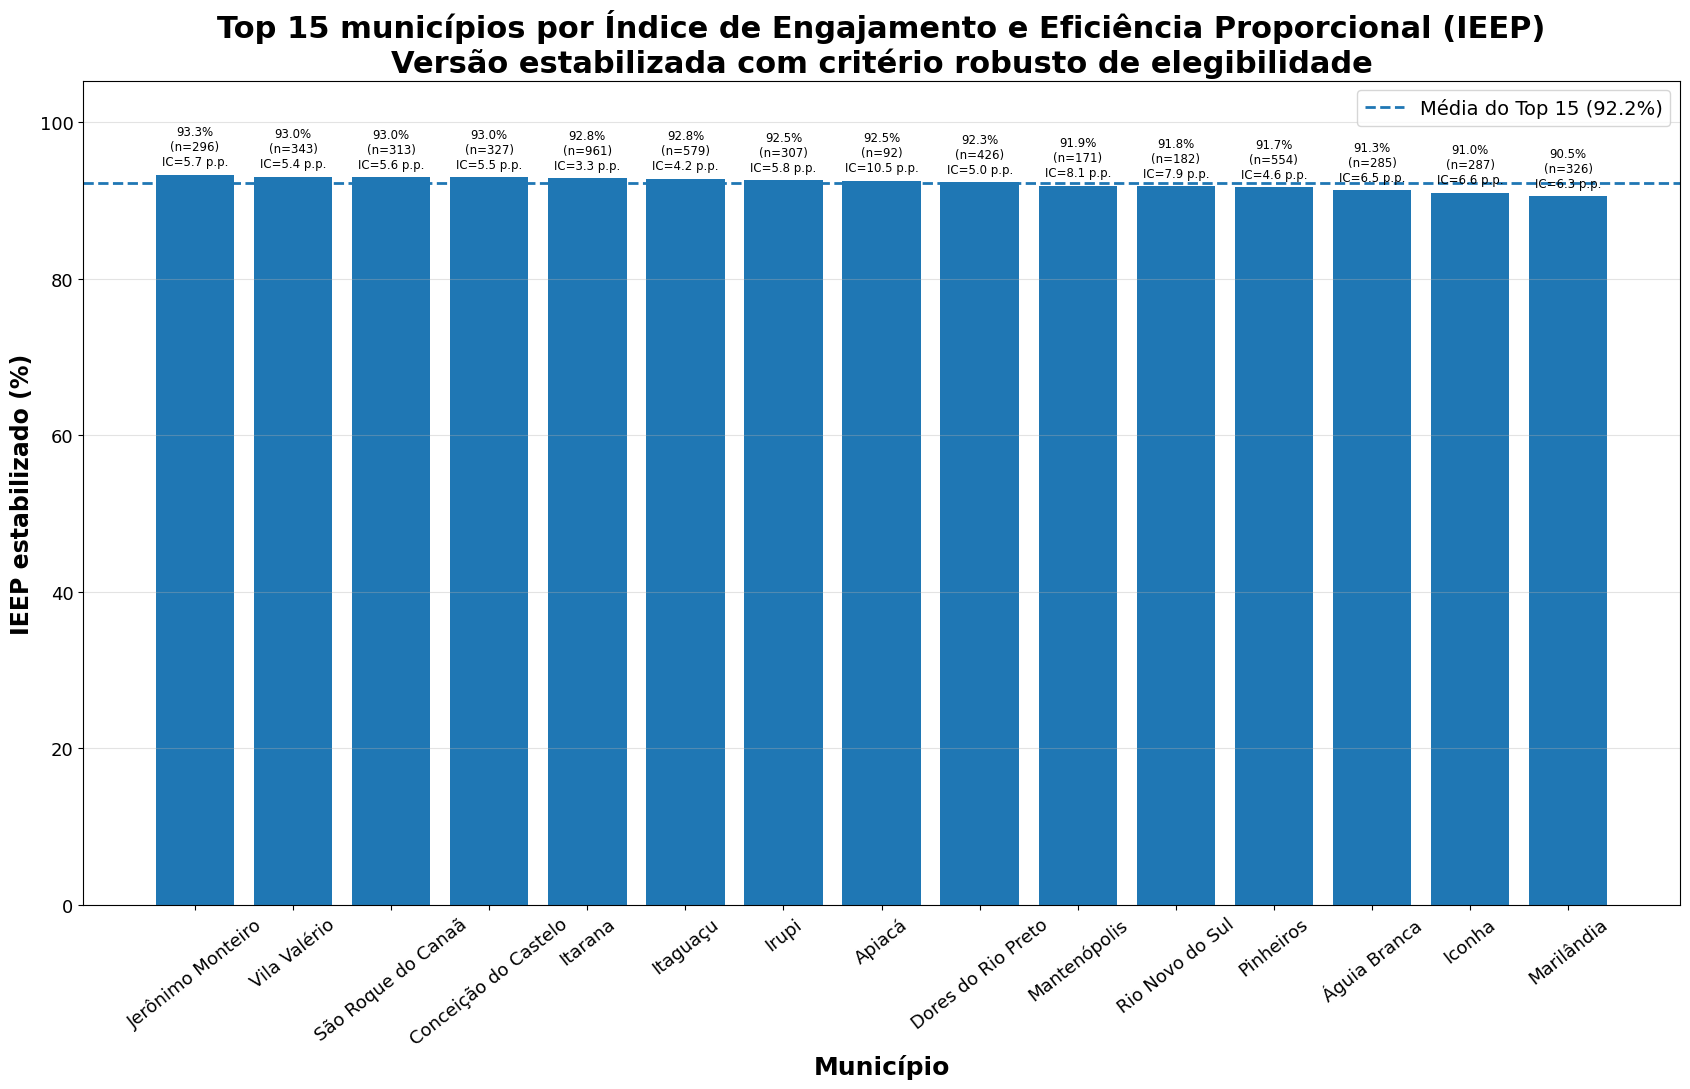

FIGURA FINAL MICRORREGIONAL: TOP MUNICÍPIOS POR IEEP ESTABILIZADO
Arquivo salvo:
- /content/dados_output/28_figura_top15_municipios_ieep_estabilizado.png


In [43]:
import matplotlib.pyplot as plt

df_top_municipios = (
    df_municipios_metricas[df_municipios_metricas["flg_elegivel_hotspot"]]
    .sort_values("ieep_estabilizado", ascending=False)
    .head(15)
    .copy()
)

df_top_municipios["ieep_pct"] = df_top_municipios["ieep_estabilizado"] * 100
df_top_municipios["ic_pp"] = df_top_municipios["ieep_ic_amplitude"] * 100

def rotulo_municipio(nome):
    ajustes = {
        "Jeronimo Monteiro": "Jerônimo Monteiro",
        "Vila Valerio": "Vila Valério",
        "Sao Roque Do Canaa": "São Roque do Canaã",
        "Conceicao Do Castelo": "Conceição do Castelo",
        "Itaguacu": "Itaguaçu",
        "Apiaca": "Apiacá",
        "Dores Do Rio Preto": "Dores do Rio Preto",
        "Rio Novo Do Sul": "Rio Novo do Sul",
        "Aguia Branca": "Águia Branca",
        "Iconha": "Iconha",
        "Marilandia": "Marilândia",
        "Mantenopolis": "Mantenópolis",
        "Pinheiros": "Pinheiros",
        "Irupi": "Irupi",
        "Itarana": "Itarana",
    }
    nome = str(nome).title()
    return ajustes.get(nome, nome)

df_top_municipios["rotulo"] = (
    df_top_municipios["Municipio_padronizado"]
    .astype(str)
    .apply(rotulo_municipio)
)

media_top15 = df_top_municipios["ieep_pct"].mean()

fig, ax = plt.subplots(figsize=(17, 11))

bars = ax.bar(
    df_top_municipios["rotulo"],
    df_top_municipios["ieep_pct"]
)

# Linha de média do Top 15
ax.axhline(
    media_top15,
    linestyle="--",
    linewidth=2,
    label=f"Média do Top 15 ({media_top15:.1f}%)"
)

for bar, (_, row) in zip(bars, df_top_municipios.iterrows()):
    x = bar.get_x() + bar.get_width() / 2
    y = bar.get_height()

    ax.text(
        x,
        y + 0.8,
        f"{row['ieep_pct']:.1f}%\n(n={int(row['n_ativos'])})\nIC={row['ic_pp']:.1f} p.p.",
        ha="center",
        va="bottom",
        fontsize=8.5
    )

ax.set_title(
    "Top 15 municípios por Índice de Engajamento e Eficiência Proporcional (IEEP)\n"
    "Versão estabilizada com critério robusto de elegibilidade",
    fontsize=22,
    weight="bold"
)

ax.set_ylabel("IEEP estabilizado (%)", fontsize=17, weight="bold")
ax.set_xlabel("Município", fontsize=18, weight="bold")

ax.tick_params(axis="x", labelrotation=38, labelsize=13)
ax.tick_params(axis="y", labelsize=13)

ax.set_ylim(0, max(df_top_municipios["ieep_pct"]) + 12)
ax.legend(fontsize=14)
ax.grid(axis="y", alpha=0.35)

plt.tight_layout()

arq_fig_top15 = DIR_SAIDAS / "28_figura_top15_municipios_ieep_estabilizado.png"
plt.savefig(arq_fig_top15, dpi=300, bbox_inches="tight")
plt.show()

print("=" * 78)
print("FIGURA FINAL MICRORREGIONAL: TOP MUNICÍPIOS POR IEEP ESTABILIZADO")
print("=" * 78)
print(f"Arquivo salvo:\n- {arq_fig_top15}")

# 18. Construção da base geográfica oficial e derivação territorial das SREs

In [44]:
import subprocess
import sys
from pathlib import Path

import pandas as pd
import geopandas as gpd

try:
    import geobr
except ImportError:
    print("Pacote 'geobr' não encontrado. Instalando...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "geobr"])
    import geobr

arq_municipios_metricas = DIR_SAIDAS / "12_agregado_municipal_metricas_comparadas.parquet"
arq_base_territorial = DIR_SAIDAS / "05_base_territorial_valida.parquet"

if not arq_municipios_metricas.exists():
    raise FileNotFoundError(f"Arquivo não encontrado: {arq_municipios_metricas}")

if not arq_base_territorial.exists():
    raise FileNotFoundError(f"Arquivo não encontrado: {arq_base_territorial}")

df_municipios_metricas = pd.read_parquet(arq_municipios_metricas).copy()
df_base_territorial = pd.read_parquet(arq_base_territorial).copy()

def padronizar_texto(x):
    if pd.isna(x):
        return pd.NA
    x = str(x).strip().upper()
    substituicoes = {
        "Á": "A", "À": "A", "Â": "A", "Ã": "A",
        "É": "E", "Ê": "E",
        "Í": "I",
        "Ó": "O", "Ô": "O", "Õ": "O",
        "Ú": "U",
        "Ç": "C"
    }
    for a, b in substituicoes.items():
        x = x.replace(a, b)
    x = " ".join(x.split())
    return x

print("Baixando malha municipal oficial do Espírito Santo...")
gdf_mun_es = geobr.read_municipality(code_muni="ES", year=2022)

print(f"Municípios na malha oficial: {len(gdf_mun_es)}")

# Padronização dos nomes oficiais
gdf_mun_es["Municipio_padronizado"] = gdf_mun_es["name_muni"].apply(padronizar_texto)
gdf_mun_es["Codigo_IBGE"] = pd.to_numeric(gdf_mun_es["code_muni"], errors="coerce")

df_municipios_metricas["Municipio_padronizado"] = df_municipios_metricas["Municipio_padronizado"].apply(padronizar_texto)

# garantir código IBGE se existir
if "Codigo_IBGE" in df_base_territorial.columns:
    base_codigo = (
        df_base_territorial[["Municipio_padronizado", "Codigo_IBGE"]]
        .copy()
    )
    base_codigo["Municipio_padronizado"] = base_codigo["Municipio_padronizado"].apply(padronizar_texto)
    base_codigo["Codigo_IBGE"] = pd.to_numeric(base_codigo["Codigo_IBGE"], errors="coerce")
    base_codigo = (
        base_codigo
        .dropna(subset=["Municipio_padronizado", "Codigo_IBGE"])
        .drop_duplicates(subset=["Municipio_padronizado"])
    )
    df_municipios_metricas = df_municipios_metricas.merge(
        base_codigo,
        on="Municipio_padronizado",
        how="left"
    )
else:
    df_municipios_metricas["Codigo_IBGE"] = pd.NA

gdf_municipios = gdf_mun_es.merge(
    df_municipios_metricas.drop(columns=["Municipio_padronizado"], errors="ignore"),
    left_on="Codigo_IBGE",
    right_on="Codigo_IBGE",
    how="left"
)

# fallback por nome para casos sem código
faltantes = gdf_municipios["ieep_estabilizado"].isna()

if faltantes.sum() > 0:
    complemento_nome = gdf_mun_es.loc[faltantes, ["Municipio_padronizado"]].merge(
        df_municipios_metricas,
        on="Municipio_padronizado",
        how="left"
    )
    for col in complemento_nome.columns:
        if col not in gdf_municipios.columns:
            continue
    cols_atualizar = [c for c in df_municipios_metricas.columns if c in gdf_municipios.columns and c != "Municipio_padronizado"]
    for col in cols_atualizar:
        gdf_municipios.loc[faltantes, col] = complemento_nome[col].values

df_base_territorial["Municipio_padronizado"] = df_base_territorial["Municipio_padronizado"].apply(padronizar_texto)
df_base_territorial["SRE_padronizada"] = df_base_territorial["SRE_padronizada"].apply(padronizar_texto)

dic_mun_sre = (
    df_base_territorial
    .groupby(["Municipio_padronizado", "SRE_padronizada"])
    .size()
    .reset_index(name="freq")
    .sort_values(["Municipio_padronizado", "freq"], ascending=[True, False])
    .drop_duplicates(subset=["Municipio_padronizado"])
    [["Municipio_padronizado", "SRE_padronizada"]]
    .copy()
)

# ajustar manualmente a rotulagem institucional, se necessário
dic_mun_sre["SRE_padronizada"] = dic_mun_sre["SRE_padronizada"].replace({
    "SRE COMENDADORA JUREMA MORETZ SOHN": "SRE COMENDADORA JUREMA MORETZ SOHN"
})

# acoplar SRE à malha municipal
gdf_municipios = gdf_municipios.merge(
    dic_mun_sre,
    on="Municipio_padronizado",
    how="left",
    suffixes=("", "_dict")
)

# se já existir coluna de SRE oriunda do merge anterior, priorizar a do dicionário territorial
if "SRE_padronizada_dict" in gdf_municipios.columns:
    gdf_municipios["SRE_padronizada"] = gdf_municipios["SRE_padronizada_dict"].combine_first(
        gdf_municipios.get("SRE_padronizada")
    )
    gdf_municipios = gdf_municipios.drop(columns=["SRE_padronizada_dict"], errors="ignore")

gdf_sre = (
    gdf_municipios
    .dropna(subset=["SRE_padronizada"])
    .dissolve(by="SRE_padronizada", as_index=False)
)

# anexar tabela executiva de SRE
arq_tabela_sre = DIR_SAIDAS / "22_tabela_executiva_sre.parquet"
if arq_tabela_sre.exists():
    df_sre_exec = pd.read_parquet(arq_tabela_sre).copy()
    df_sre_exec["SRE_padronizada"] = df_sre_exec["SRE_padronizada"].apply(padronizar_texto)
    gdf_sre = gdf_sre.merge(df_sre_exec, on="SRE_padronizada", how="left")

print("-" * 78)
print("AUDITORIA FINAL DAS CAMADAS GEOGRÁFICAS")
print("-" * 78)
print(f"Municípios na malha oficial: {len(gdf_mun_es)}")
print(f"Municípios com indicadores acoplados: {gdf_municipios['ieep_estabilizado'].notna().sum()}")
print(f"SREs derivadas por dissolve: {gdf_sre['SRE_padronizada'].nunique()}")

print("\nAMOSTRA DA CAMADA MUNICIPAL:")
display(
    gdf_municipios[
        ["Municipio_padronizado", "SRE_padronizada", "n_ativos", "ieep_estabilizado"]
    ].head(10)
)

print("\nAMOSTRA DA CAMADA DAS SREs:")
cols_sre_preview = [c for c in ["SRE_padronizada", "n_ativos", "ieep_estabilizado", "vies_gestao_menos_docencia_pp"] if c in gdf_sre.columns]
display(gdf_sre[cols_sre_preview].head(11))

# -------------------------------------------------------------------------
# SALVAR CAMADAS FINAIS
# -------------------------------------------------------------------------
arq_gpkg_municipios = DIR_SAIDAS / "30_malha_municipal_ieep.gpkg"
arq_gpkg_sre = DIR_SAIDAS / "31_malha_sre_derivada_ieep.gpkg"

gdf_municipios.to_file(arq_gpkg_municipios, layer="municipios_ieep", driver="GPKG")
gdf_sre.to_file(arq_gpkg_sre, layer="sre_ieep", driver="GPKG")

print("-" * 78)
print("Arquivos salvos:")
print(f"- {arq_gpkg_municipios}")
print(f"- {arq_gpkg_sre}")

Baixando malha municipal oficial do Espírito Santo...
Municípios na malha oficial: 78
------------------------------------------------------------------------------
AUDITORIA FINAL DAS CAMADAS GEOGRÁFICAS
------------------------------------------------------------------------------
Municípios na malha oficial: 78
Municípios com indicadores acoplados: 78
SREs derivadas por dissolve: 11

AMOSTRA DA CAMADA MUNICIPAL:


,Municipio_padronizado,SRE_padronizada,n_ativos,ieep_estabilizado
0,AFONSO CLAUDIO,SRE AFONSO CLAUDIO,509,0.882574
1,AGUIA BRANCA,SRE BARRA DE SAO FRANCISCO,285,0.912770
2,AGUA DOCE DO NORTE,SRE BARRA DE SAO FRANCISCO,322,0.876547
3,ALEGRE,SRE COMENDADORA JUREMA MORETZ SOHN,383,0.813155
4,ALFREDO CHAVES,SRE VILA VELHA,298,0.889959
5,ALTO RIO NOVO,SRE COLATINA,116,0.881325
6,ANCHIETA,SRE VILA VELHA,413,0.853071
7,APIACA,SRE COMENDADORA JUREMA MORETZ SOHN,92,0.925028
8,ARACRUZ,SRE LINHARES,675,0.858227
9,ATILIO VIVACQUA,SRE CACHOEIRO DE ITAPEMIRIM,254,0.875010



AMOSTRA DA CAMADA DAS SREs:


,SRE_padronizada,vies_gestao_menos_docencia_pp
0,SRE AFONSO CLAUDIO,0.879766
1,SRE BARRA DE SAO FRANCISCO,-1.926692
2,SRE CACHOEIRO DE ITAPEMIRIM,-2.019900
3,SRE CARAPINA,-7.707336
4,SRE CARIACICA,-5.572075
5,SRE COLATINA,-3.019119
6,SRE COMENDADORA JUREMA MORETZ SOHN,-0.580092
7,SRE LINHARES,-4.355401
8,SRE NOVA VENECIA,-5.658699
9,SRE SAO MATEUS,-3.319484


------------------------------------------------------------------------------
Arquivos salvos:
- /content/dados_output/30_malha_municipal_ieep.gpkg
- /content/dados_output/31_malha_sre_derivada_ieep.gpkg


## 19. MAPA DINÂMICO MACRORREGIONAL DO IEEP ESTABILIZADO POR SRE

In [45]:
import json
import numpy as np
import pandas as pd
import geopandas as gpd
import folium
import branca.colormap as cm

from shapely.geometry import Polygon, MultiPolygon, GeometryCollection
from shapely.ops import unary_union
from branca.element import Template, MacroElement
from IPython.display import display

ARQ_SRE_GPKG = DIR_SAIDAS / "31_malha_sre_derivada_ieep.gpkg"
ARQ_SRE_TAB = DIR_SAIDAS / "22_tabela_executiva_sre.parquet"

if not ARQ_SRE_GPKG.exists():
    raise FileNotFoundError(f"Arquivo não encontrado: {ARQ_SRE_GPKG}")

if not ARQ_SRE_TAB.exists():
    raise FileNotFoundError(f"Arquivo não encontrado: {ARQ_SRE_TAB}")

gdf_sre = gpd.read_file(ARQ_SRE_GPKG).copy()
df_sre = pd.read_parquet(ARQ_SRE_TAB).copy()

print("-" * 78)
print("AUDITORIA INICIAL")
print("-" * 78)
print(f"SREs na malha geográfica: {len(gdf_sre)}")
print(f"SREs na tabela executiva: {len(df_sre)}")

gdf_sre["SRE_padronizada"] = gdf_sre["SRE_padronizada"].astype(str).str.strip().str.upper()
df_sre["SRE_padronizada"] = df_sre["SRE_padronizada"].astype(str).str.strip().str.upper()

colunas_desejadas = [
    "SRE_padronizada",
    "n_ativos",
    "ieep_bruto",
    "ieep_estabilizado",
    "ieep_ic_amplitude",
    "n_docencia",
    "ieep_docencia",
    "n_gestao",
    "ieep_gestao",
    "vies_gestao_menos_docencia_pp",
    "patamar_ieep",
    "grau_incerteza",
    "leitura_vies_ocupacional"
]

colunas_existentes = [c for c in colunas_desejadas if c in df_sre.columns]
df_sre_merge = df_sre[colunas_existentes].copy()

# remover possíveis colunas antigas duplicadas
cols_drop = [c for c in colunas_desejadas if c != "SRE_padronizada" and c in gdf_sre.columns]
if cols_drop:
    gdf_sre = gdf_sre.drop(columns=cols_drop)

gdf_sre = gdf_sre.merge(df_sre_merge, on="SRE_padronizada", how="left")

# garantir colunas mínimas
for col in [
    "n_ativos", "ieep_bruto", "ieep_estabilizado", "ieep_ic_amplitude",
    "n_docencia", "ieep_docencia", "n_gestao", "ieep_gestao",
    "vies_gestao_menos_docencia_pp", "patamar_ieep",
    "grau_incerteza", "leitura_vies_ocupacional"
]:
    if col not in gdf_sre.columns:
        gdf_sre[col] = np.nan

print("-" * 78)
print("AUDITORIA APÓS MERGE")
print("-" * 78)
print(f"SREs com IEEP estabilizado não nulo: {gdf_sre['ieep_estabilizado'].notna().sum()}")

def remover_buracos_pequenos(geom, area_min_buraco=0.00005):
    if geom is None or geom.is_empty:
        return geom

    if isinstance(geom, Polygon):
        holes_filtrados = []
        for ring in geom.interiors:
            try:
                hole_poly = Polygon(ring)
                if hole_poly.area >= area_min_buraco:
                    holes_filtrados.append(ring)
            except Exception:
                continue
        return Polygon(geom.exterior, holes_filtrados)

    if isinstance(geom, MultiPolygon):
        partes = [remover_buracos_pequenos(g, area_min_buraco) for g in geom.geoms]
        partes = [g for g in partes if g is not None and not g.is_empty]
        return MultiPolygon(partes) if len(partes) > 1 else (partes[0] if partes else geom)

    return geom


def remover_fragmentos_pequenos(geom, area_min_parte=0.0002):
    if geom is None or geom.is_empty:
        return geom

    if isinstance(geom, Polygon):
        return geom if geom.area >= area_min_parte else GeometryCollection()

    if isinstance(geom, MultiPolygon):
        partes_validas = [g for g in geom.geoms if g.area >= area_min_parte]
        if len(partes_validas) == 0:
            return GeometryCollection()
        if len(partes_validas) == 1:
            return partes_validas[0]
        return MultiPolygon(partes_validas)

    return geom


def limpar_geom_sre(geom, area_min_buraco=0.00005, area_min_parte=0.0002, simpl_tolerancia=0.0003):
    if geom is None or geom.is_empty:
        return geom

    geom = geom.buffer(0)
    geom = unary_union(geom)
    geom = geom.buffer(0)

    geom = remover_buracos_pequenos(geom, area_min_buraco=area_min_buraco)
    geom = remover_fragmentos_pequenos(geom, area_min_parte=area_min_parte)

    if geom is None or geom.is_empty:
        return geom

    geom = geom.simplify(simpl_tolerancia, preserve_topology=True)
    geom = geom.buffer(0)

    return geom

gdf_sre = gdf_sre[gdf_sre.geometry.notna()].copy()
area_total_antes = gdf_sre.geometry.area.sum()

gdf_sre["geometry"] = gdf_sre["geometry"].apply(
    lambda g: limpar_geom_sre(
        g,
        area_min_buraco=0.00005,
        area_min_parte=0.00020,
        simpl_tolerancia=0.00030
    )
)

gdf_sre = gdf_sre[gdf_sre.geometry.notna()].copy()
gdf_sre = gdf_sre[~gdf_sre.geometry.is_empty].copy()

area_total_depois = gdf_sre.geometry.area.sum()

print("-" * 78)
print("LIMPEZA TOPOLOGICA")
print("-" * 78)
print(f"SREs após limpeza: {len(gdf_sre)}")
print(f"Área total antes:  {area_total_antes:.6f}")
print(f"Área total depois: {area_total_depois:.6f}")
print(f"Variação relativa: {((area_total_depois - area_total_antes) / area_total_antes) * 100:.4f}%")

gdf_sre["ieep_pct"] = gdf_sre["ieep_estabilizado"] * 100
gdf_sre["ieep_bruto_pct"] = gdf_sre["ieep_bruto"] * 100
gdf_sre["ic_amp_pp"] = gdf_sre["ieep_ic_amplitude"] * 100
gdf_sre["ieep_doc_pct"] = gdf_sre["ieep_docencia"] * 100
gdf_sre["ieep_gest_pct"] = gdf_sre["ieep_gestao"] * 100

def fmt_pct(x):
    return "N/D" if pd.isna(x) else f"{x:.1f}%"

def fmt_pp(x):
    return "N/D" if pd.isna(x) else f"{x:.1f} p.p."

def fmt_pp_signed(x):
    return "N/D" if pd.isna(x) else f"{x:+.1f} p.p."

def fmt_int(x):
    return "N/D" if pd.isna(x) else f"{int(x):,}".replace(",", ".")

def encurtar_sre(nome):
    nome = str(nome).replace("SRE ", "").title()
    nome = nome.replace("Comendadora Jurema Moretz Sohn", "Guaçuí")
    nome = nome.replace("Afonso Claudio", "Afonso Cláudio")
    nome = nome.replace("Sao Mateus", "São Mateus")
    nome = nome.replace("Nova Venecia", "Nova Venécia")
    return nome

gdf_sre["SRE_curta"] = gdf_sre["SRE_padronizada"].apply(encurtar_sre)
gdf_sre["n_ativos_str"] = gdf_sre["n_ativos"].apply(fmt_int)
gdf_sre["ieep_str"] = gdf_sre["ieep_pct"].apply(fmt_pct)
gdf_sre["ieep_bruto_str"] = gdf_sre["ieep_bruto_pct"].apply(fmt_pct)
gdf_sre["ic_amp_str"] = gdf_sre["ic_amp_pp"].apply(fmt_pp)
gdf_sre["doc_str"] = gdf_sre["ieep_doc_pct"].apply(fmt_pct)
gdf_sre["gest_str"] = gdf_sre["ieep_gest_pct"].apply(fmt_pct)
gdf_sre["vies_str"] = gdf_sre["vies_gestao_menos_docencia_pp"].apply(fmt_pp_signed)

gdf_sre["patamar_ieep"] = gdf_sre["patamar_ieep"].fillna("Não disponível")
gdf_sre["grau_incerteza"] = gdf_sre["grau_incerteza"].fillna("Não disponível")
gdf_sre["leitura_vies_ocupacional"] = gdf_sre["leitura_vies_ocupacional"].fillna("Não disponível")

gdf_sre_4326 = gdf_sre.to_crs(epsg=4326)

# centro do mapa
centroide_estado = gdf_sre_4326.unary_union.centroid
es_centro = [centroide_estado.y, centroide_estado.x]

mapa_sre = folium.Map(
    location=es_centro,
    zoom_start=8,
    tiles=None,
    control_scale=True
)

folium.TileLayer(
    tiles="https://{s}.basemaps.cartocdn.com/light_nolabels/{z}/{x}/{y}{r}.png",
    attr='&copy; OpenStreetMap contributors &copy; CARTO',
    name="Base clara sem rótulos",
    overlay=False,
    control=True
).add_to(mapa_sre)

min_val = float(np.floor(gdf_sre["ieep_pct"].min()))
max_val = float(np.ceil(gdf_sre["ieep_pct"].max()))

if min_val == max_val:
    min_val -= 1
    max_val += 1

colormap = cm.linear.YlGnBu_06.scale(min_val, max_val)
colormap.caption = "IEEP estabilizado (%)"
colormap.add_to(mapa_sre)

tooltip_fields = [
    "SRE_curta",
    "n_ativos_str",
    "ieep_str",
    "ieep_bruto_str",
    "ic_amp_str",
    "doc_str",
    "gest_str",
    "vies_str",
    "patamar_ieep",
    "grau_incerteza",
    "leitura_vies_ocupacional"
]

tooltip_aliases = [
    "SRE:",
    "Ativos elegíveis:",
    "IEEP estabilizado:",
    "IEEP bruto:",
    "Amplitude do IC:",
    "IEEP Docência:",
    "IEEP Gestão:",
    "Viés Gestão - Docência:",
    "Patamar territorial:",
    "Grau de incerteza:",
    "Leitura do viés:"
]

tooltip = folium.GeoJsonTooltip(
    fields=tooltip_fields,
    aliases=tooltip_aliases,
    localize=True,
    sticky=True,
    labels=True,
    style="""
        background-color: rgba(255,255,255,0.96);
        color: #1a1a1a;
        font-family: Arial, Helvetica, sans-serif;
        font-size: 12px;
        padding: 12px;
        border: 2px solid #6e6e6e;
        border-radius: 6px;
        box-shadow: 3px 3px 8px rgba(0,0,0,0.25);
        line-height: 1.5;
    """
)

def style_function(feature):
    valor = feature["properties"]["ieep_pct"]
    return {
        "fillColor": colormap(valor) if valor is not None else "#d9d9d9",
        "color": "black",
        "weight": 1.8,
        "fillOpacity": 0.88
    }

def highlight_function(feature):
    return {
        "weight": 3.2,
        "color": "#111111",
        "fillOpacity": 0.97
    }

folium.GeoJson(
    gdf_sre_4326.to_json(),
    name="SRE - IEEP estabilizado",
    style_function=style_function,
    highlight_function=highlight_function,
    tooltip=tooltip
).add_to(mapa_sre)

template = """
{% macro html(this, kwargs) %}
<div style="
    position: fixed;
    bottom: 45px;
    left: 45px;
    width: 360px;
    height: auto;
    background-color: rgba(255,255,255,0.96);
    border: 2px solid #7a7a7a;
    z-index: 9999;
    font-family: Arial, Helvetica, sans-serif;
    padding: 16px;
    border-radius: 8px;
    box-shadow: 4px 4px 10px rgba(0,0,0,0.28);
">
    <h4 style="
        margin: 0 0 10px 0;
        font-size: 15px;
        text-align: center;
        border-bottom: 1px solid #d0d0d0;
        padding-bottom: 6px;
    ">
        <b>Guia de leitura — IEEP por SRE</b>
    </h4>

    <p style="margin: 0; font-size: 12px; line-height: 1.6;">
        <b>Coloração:</b> representa o <b>IEEP estabilizado</b>, isto é, a versão
        robusta do indicador territorial após suavização das proporções.<br><br>

        <b>IEEP bruto:</b> taxa observada antes da estabilização.<br>
        <b>Amplitude do IC:</b> medida de incerteza da estimativa territorial.<br>
        <b>IEEP Docência / Gestão:</b> decomposição ocupacional do desempenho.<br>
        <b>Viés Gestão - Docência:</b> contraste entre os dois grupos, em pontos percentuais.<br><br>

        Passe o mouse sobre cada SRE para inspecionar os indicadores.
    </p>
</div>
{% endmacro %}
"""
macro = MacroElement()
macro._template = Template(template)
mapa_sre.get_root().add_child(macro)

titulo_html = """
<div style="
    position: fixed;
    top: 12px;
    left: 50%;
    transform: translateX(-50%);
    z-index: 9998;
    background-color: rgba(255,255,255,0.88);
    padding: 10px 18px;
    border-radius: 8px;
    border: 1px solid #bfbfbf;
    font-family: Arial, Helvetica, sans-serif;
    text-align: center;
    box-shadow: 2px 2px 8px rgba(0,0,0,0.18);
">
    <div style="font-size: 18px; font-weight: bold; color: #111;">
        IEEP estabilizado por SRE
    </div>
    <div style="font-size: 12px; color: #333;">
        Versão robusta com controle de incerteza
    </div>
</div>
"""
mapa_sre.get_root().html.add_child(folium.Element(titulo_html))

folium.LayerControl(collapsed=False).add_to(mapa_sre)

arq_html_sre = DIR_SAIDAS / "34_mapa_dinamico_sre_ieep_estabilizado.html"
mapa_sre.save(str(arq_html_sre))

print("-" * 78)
print("[SUCESSO] Mapa dinâmico macrorregional renderizado.")
print("Arquivo salvo:")
print(f"- {arq_html_sre}")

display(mapa_sre)

------------------------------------------------------------------------------
AUDITORIA INICIAL
------------------------------------------------------------------------------
SREs na malha geográfica: 11
SREs na tabela executiva: 11
------------------------------------------------------------------------------
AUDITORIA APÓS MERGE
------------------------------------------------------------------------------
SREs com IEEP estabilizado não nulo: 11
------------------------------------------------------------------------------
LIMPEZA TOPOLOGICA
------------------------------------------------------------------------------
SREs após limpeza: 11
Área total antes:  3.966935
Área total depois: 3.967485
Variação relativa: 0.0139%
------------------------------------------------------------------------------
[SUCESSO] Mapa dinâmico macrorregional renderizado.
Arquivo salvo:
- /content/dados_output/34_mapa_dinamico_sre_ieep_estabilizado.html


## 20. MAPA ESTÁTICO FINAL DAS SREs COM LEGENDA NUMÉRICA LATERAL E TABELA LATEX REFINADA PARA PUBLICAÇÃO

------------------------------------------------------------------------------
Renderizando mapa final com legenda lateral...
------------------------------------------------------------------------------


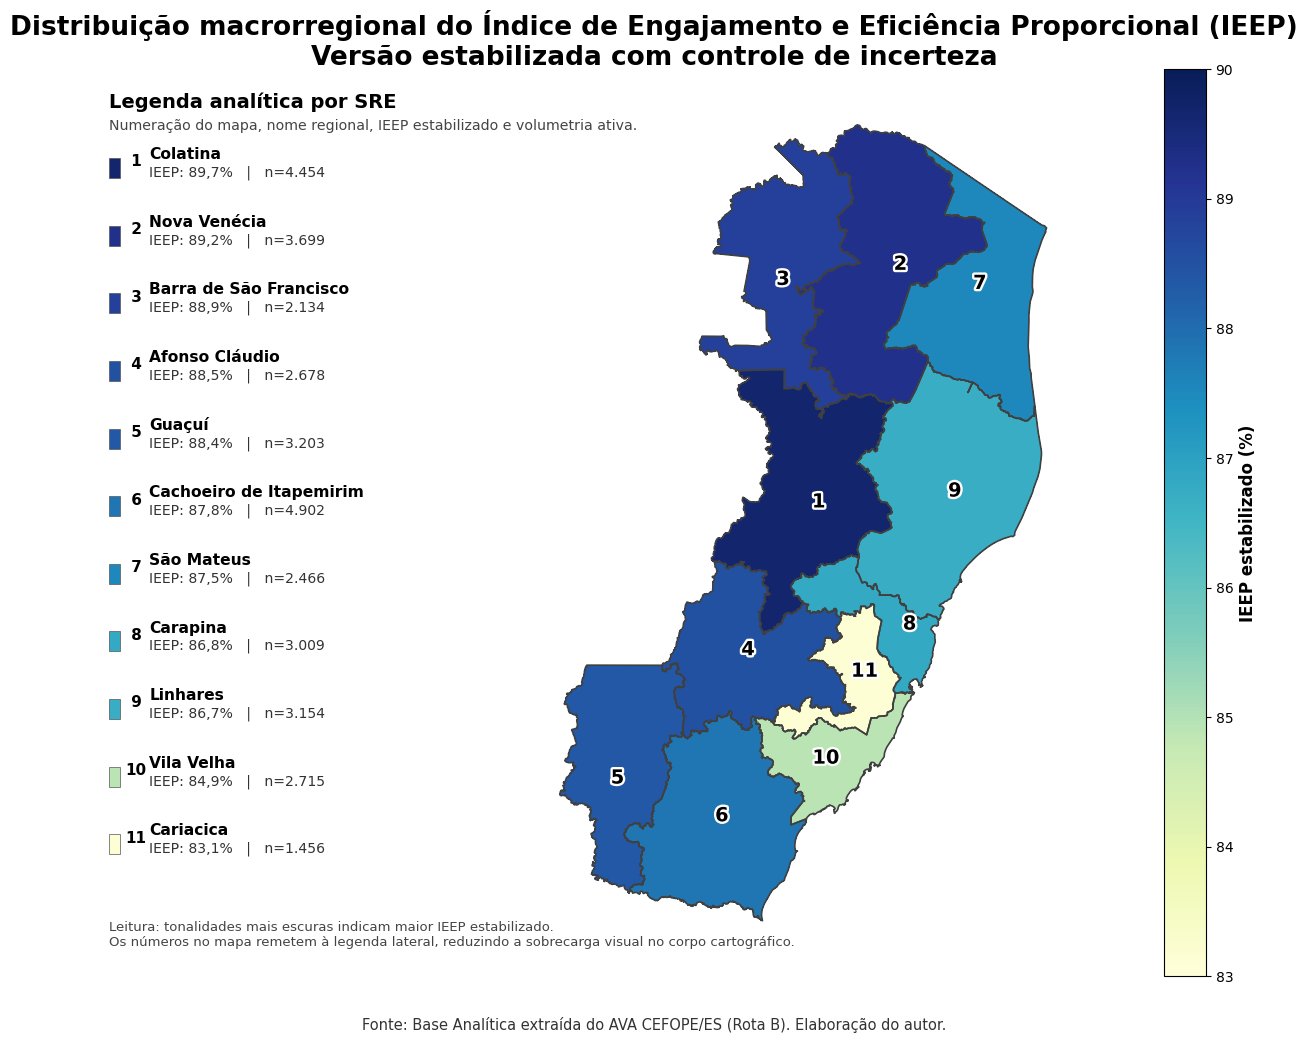

------------------------------------------------------------------------------
Gerando tabela LaTeX refinada...
------------------------------------------------------------------------------
Arquivos salvos:
- /content/dados_output/37_mapa_estatico_sre_ieep_numerado_legenda_lateral.png
- /content/dados_output/38_tabela_ieep_sre_estabilizado_final.tex
------------------------------------------------------------------------------
PRÉVIA DO BLOCO LATEX
------------------------------------------------------------------------------
\begin{table}[H]
    \centering
    \caption{Síntese macrorregional do IEEP estabilizado por Superintendência Regional de Educação (SRE).}
    \label{tab:ieep_sre_estabilizado}
    \vspace{0.2cm}
    \footnotesize
    \renewcommand{\arraystretch}{1.16}
    \setlength{\tabcolsep}{4.5pt}
    \begin{tabular*}{0.98\textwidth}{@{\extracolsep{\fill}} c l c c c c c c}
        \toprule
        \textbf{Núm} & \textbf{SRE} & \textbf{Vol.\ Ativos} & \textbf{Taxa Bruta (\%)}

In [46]:
import math
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe

from shapely.geometry import Polygon, MultiPolygon
from shapely.ops import unary_union
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

ARQ_MALHA_MUNICIPAL = DIR_SAIDAS / "30_malha_municipal_ieep.gpkg"
ARQ_TABELA_SRE = DIR_SAIDAS / "22_tabela_executiva_sre.parquet"

if not ARQ_MALHA_MUNICIPAL.exists():
    raise FileNotFoundError(f"Arquivo não encontrado: {ARQ_MALHA_MUNICIPAL}")

if not ARQ_TABELA_SRE.exists():
    raise FileNotFoundError(f"Arquivo não encontrado: {ARQ_TABELA_SRE}")

gdf_mun = gpd.read_file(ARQ_MALHA_MUNICIPAL).copy()
df_sre = pd.read_parquet(ARQ_TABELA_SRE).copy()

gdf_mun["SRE_padronizada"] = gdf_mun["SRE_padronizada"].astype(str).str.strip().str.upper()
df_sre["SRE_padronizada"] = df_sre["SRE_padronizada"].astype(str).str.strip().str.upper()

def encurtar_sre(nome):
    nome = str(nome).replace("SRE ", "").title()
    nome = nome.replace("Comendadora Jurema Moretz Sohn", "Guaçuí")
    nome = nome.replace("Afonso Claudio", "Afonso Cláudio")
    nome = nome.replace("Barra De Sao Francisco", "Barra de São Francisco")
    nome = nome.replace("Cachoeiro De Itapemirim", "Cachoeiro de Itapemirim")
    nome = nome.replace("Nova Venecia", "Nova Venécia")
    nome = nome.replace("Sao Mateus", "São Mateus")
    return nome

def limpar_geometria_sre(geom):
    if geom is None or geom.is_empty:
        return geom
    geom = geom.buffer(0)
    if isinstance(geom, MultiPolygon):
        geom = unary_union([g.buffer(0) for g in geom.geoms])
        if isinstance(geom, MultiPolygon):
            geom = max(list(geom.geoms), key=lambda g: g.area)
    if isinstance(geom, Polygon):
        geom = Polygon(geom.exterior)
    return geom.buffer(0)

def fmt_milhar(x):
    if pd.isna(x):
        return "N/D"
    return f"{int(round(x)):,}".replace(",", ".")

def fmt_pct_texto(x, casas=1):
    if pd.isna(x):
        return "N/D"
    return f"{x:.{casas}f}".replace(".", ",")

def escapar_latex(txt):
    txt = str(txt)
    return txt.replace("&", "\\&")

gdf_sre = (
    gdf_mun[["SRE_padronizada", "geometry"]]
    .dissolve(by="SRE_padronizada", as_index=False)
    .copy()
)

gdf_sre["geometry"] = gdf_sre["geometry"].apply(limpar_geometria_sre)

cols_metricas = [
    "SRE_padronizada",
    "n_ativos",
    "ieep_bruto",
    "ieep_estabilizado",
    "ieep_ic_amplitude",
    "n_docencia",
    "ieep_docencia",
    "n_gestao",
    "ieep_gestao",
    "vies_gestao_menos_docencia_pp",
    "patamar_ieep",
    "grau_incerteza",
    "leitura_vies_ocupacional"
]
cols_metricas = [c for c in cols_metricas if c in df_sre.columns]

gdf_sre = gdf_sre.merge(df_sre[cols_metricas], on="SRE_padronizada", how="left")

gdf_sre["SRE_curta"] = gdf_sre["SRE_padronizada"].apply(encurtar_sre)
gdf_sre["ieep_pct"] = gdf_sre["ieep_estabilizado"] * 100
gdf_sre["ieep_bruto_pct"] = gdf_sre["ieep_bruto"] * 100
gdf_sre["ieep_doc_pct"] = gdf_sre["ieep_docencia"] * 100
gdf_sre["ieep_gest_pct"] = gdf_sre["ieep_gestao"] * 100
gdf_sre["ic_amp_pp"] = gdf_sre["ieep_ic_amplitude"] * 100

gdf_sre = gdf_sre.to_crs(epsg=4326)

df_leg = gdf_sre[[
    "SRE_padronizada", "SRE_curta", "n_ativos", "ieep_pct",
    "ieep_bruto_pct", "ieep_doc_pct", "ieep_gest_pct",
    "vies_gestao_menos_docencia_pp", "ic_amp_pp"
]].copy()

df_leg = df_leg.sort_values("ieep_pct", ascending=False).reset_index(drop=True)
df_leg.insert(0, "num", range(1, len(df_leg) + 1))

gdf_sre = gdf_sre.merge(
    df_leg[["SRE_padronizada", "num"]],
    on="SRE_padronizada",
    how="left"
)

bounds = gdf_sre.geometry.bounds
minx = bounds["minx"].min()
miny = bounds["miny"].min()
maxx = bounds["maxx"].max()
maxy = bounds["maxy"].max()

dx = (maxx - minx) * 0.10
dy = (maxy - miny) * 0.07

print("-" * 78)
print("Renderizando mapa final com legenda lateral...")
print("-" * 78)

fig = plt.figure(figsize=(12, 10.8), facecolor="white")
gs = fig.add_gridspec(
    1, 3,
    width_ratios=[1.15, 2.3, 0.14],
    left=0.04, right=0.96, top=0.92, bottom=0.08, wspace=0.06
)

ax_leg = fig.add_subplot(gs[0, 0])
ax_map = fig.add_subplot(gs[0, 1])
cax = fig.add_subplot(gs[0, 2])

cmap = plt.cm.YlGnBu
vmin = float(np.floor(gdf_sre["ieep_pct"].min()))
vmax = float(np.ceil(gdf_sre["ieep_pct"].max()))
norm = Normalize(vmin=vmin, vmax=vmax)

# preenchimento sem bordas internas
gdf_sre.plot(
    column="ieep_pct",
    cmap=cmap,
    ax=ax_map,
    linewidth=0,
    edgecolor="none",
    antialiased=False,
    vmin=vmin,
    vmax=vmax,
    zorder=1
)

# contorno externo
gdf_sre.boundary.plot(
    ax=ax_map,
    color="#404040",
    linewidth=1.2,
    zorder=2
)

# números dentro das SREs
for _, row in gdf_sre.iterrows():
    if row.geometry is None or row.geometry.is_empty or pd.isna(row["num"]):
        continue

    p = row.geometry.representative_point()
    ax_map.text(
        p.x, p.y, str(int(row["num"])),
        ha="center", va="center",
        fontsize=14, fontweight="bold", color="black",
        path_effects=[pe.withStroke(linewidth=3.4, foreground="white")],
        zorder=3
    )

ax_map.set_xlim(minx - dx, maxx + dx)
ax_map.set_ylim(miny - dy, maxy + dy)
ax_map.axis("off")

# barra de cor
sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = fig.colorbar(sm, cax=cax)
cbar.set_label("IEEP estabilizado (%)", fontsize=12, fontweight="bold")
cbar.ax.tick_params(labelsize=10)

ax_leg.axis("off")
ax_leg.set_xlim(0, 1)
ax_leg.set_ylim(0, 1)

ax_leg.text(
    0.02, 0.975,
    "Legenda analítica por SRE",
    fontsize=14, fontweight="bold", ha="left", va="top"
)

ax_leg.text(
    0.02, 0.945,
    "Numeração do mapa, nome regional, IEEP estabilizado e volumetria ativa.",
    fontsize=10.2, color="#444444", ha="left", va="top"
)

# distribuição vertical
n_itens = len(df_leg)
y_top = 0.90
y_bottom = 0.08
step = (y_top - y_bottom) / n_itens

for i, (_, row) in enumerate(df_leg.iterrows()):
    y = y_top - i * step

    cor = cmap(norm(row["ieep_pct"]))

    # quadrado da cor
    ax_leg.add_patch(
        plt.Rectangle(
            (0.02, y - 0.020), 0.032, 0.022,
            facecolor=cor, edgecolor="#555555", linewidth=0.5
        )
    )

    # número
    ax_leg.text(
        0.07, y - 0.002,
        f"{int(row['num']):>2}",
        fontsize=11, fontweight="bold",
        ha="left", va="center"
    )

    # conteúdo principal
    ax_leg.text(
        0.14, y + 0.006,
        f"{row['SRE_curta']}",
        fontsize=11.2, fontweight="bold",
        ha="left", va="center"
    )

    ax_leg.text(
        0.14, y - 0.014,
        f"IEEP: {fmt_pct_texto(row['ieep_pct'])}%   |   n={fmt_milhar(row['n_ativos'])}",
        fontsize=10.1, color="#333333",
        ha="left", va="center"
    )

# caixa interpretativa curta
ax_leg.text(
    0.02, 0.03,
    "Leitura: tonalidades mais escuras indicam maior IEEP estabilizado.\n"
    "Os números no mapa remetem à legenda lateral, reduzindo a sobrecarga visual no corpo cartográfico.",
    fontsize=9.5, color="#444444", ha="left", va="bottom"
)

fig.suptitle(
    "Distribuição macrorregional do Índice de Engajamento e Eficiência Proporcional (IEEP)\n"
    "Versão estabilizada com controle de incerteza",
    fontsize=19,
    fontweight="bold",
    y=0.975
)

fig.text(
    0.5, 0.035,
    "Fonte: Base Analítica extraída do AVA CEFOPE/ES (Rota B). Elaboração do autor.",
    ha="center", va="center", fontsize=10.5, color="#333333"
)

ARQ_MAPA_FINAL = DIR_SAIDAS / "37_mapa_estatico_sre_ieep_numerado_legenda_lateral.png"
plt.savefig(ARQ_MAPA_FINAL, dpi=300, bbox_inches="tight", pad_inches=0.18)
plt.show()

print("-" * 78)
print("Gerando tabela LaTeX refinada...")
print("-" * 78)

df_tab = df_leg.copy()

linhas_latex = []
for _, r in df_tab.iterrows():
    linhas_latex.append(
        f"{int(r['num'])} & "
        f"{escapar_latex(r['SRE_curta'])} & "
        f"{fmt_milhar(r['n_ativos'])} & "
        f"{fmt_pct_texto(r['ieep_bruto_pct'])} & "
        f"{fmt_pct_texto(r['ieep_pct'])} & "
        f"{fmt_pct_texto(r['ieep_doc_pct'])} & "
        f"{fmt_pct_texto(r['ieep_gest_pct'])} & "
        f"{fmt_pct_texto(r['vies_gestao_menos_docencia_pp'])} \\\\"
    )

corpo = "\n".join(linhas_latex)

latex_final = rf"""
\begin{{table}}[H]
    \centering
    \caption{{Síntese macrorregional do IEEP estabilizado por Superintendência Regional de Educação (SRE).}}
    \label{{tab:ieep_sre_estabilizado}}
    \vspace{{0.2cm}}
    \footnotesize
    \renewcommand{{\arraystretch}}{{1.16}}
    \setlength{{\tabcolsep}}{{4.5pt}}
    \begin{{tabular*}}{{0.98\textwidth}}{{@{{\extracolsep{{\fill}}}} c l c c c c c c}}
        \toprule
        \textbf{{Núm}} & \textbf{{SRE}} & \textbf{{Vol.\ Ativos}} & \textbf{{Taxa Bruta (\%)}} & \textbf{{IEEP (\%)}} & \textbf{{Docência (\%)}} & \textbf{{Gestão (\%)}} & \textbf{{Viés (p.p.)}} \\
        \midrule
{corpo}
        \bottomrule
    \end{{tabular*}}

    \vspace{{0.2cm}}
    \begin{{minipage}}{{0.98\textwidth}}
        \footnotesize \RaggedRight
        \textbf{{Fonte:}} Elaborado pelo autor (2026), com base na versão robusta do IEEP da Rota B.
    \end{{minipage}}
\end{{table}}
""".strip()

ARQ_TEX_FINAL = DIR_SAIDAS / "38_tabela_ieep_sre_estabilizado_final.tex"
with open(ARQ_TEX_FINAL, "w", encoding="utf-8") as f:
    f.write(latex_final)

print("Arquivos salvos:")
print(f"- {ARQ_MAPA_FINAL}")
print(f"- {ARQ_TEX_FINAL}")
print("-" * 78)
print("PRÉVIA DO BLOCO LATEX")
print("-" * 78)
print(latex_final)

------------------------------------------------------------------------------
Renderizando mapa final com legenda lateral...
------------------------------------------------------------------------------


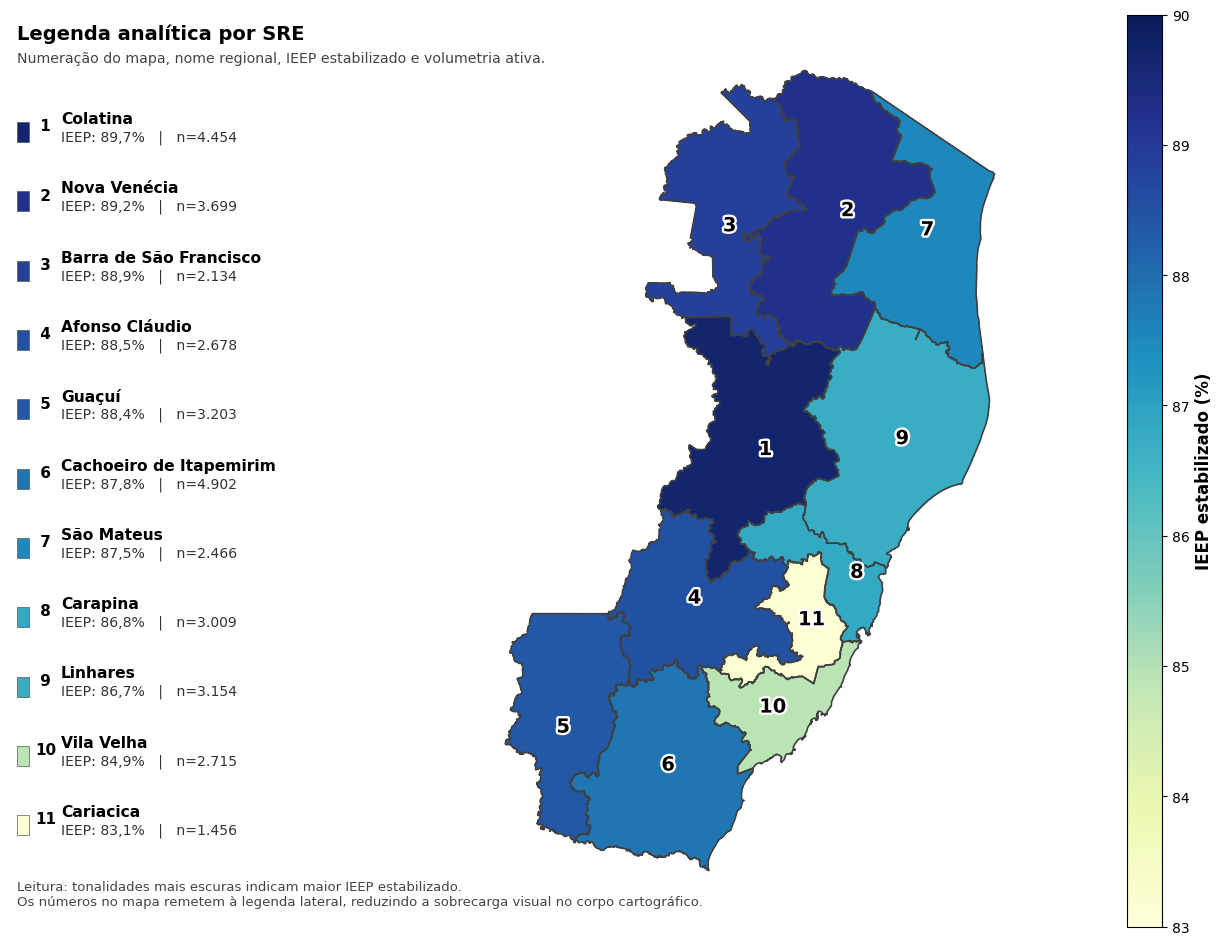

------------------------------------------------------------------------------
Gerando tabela LaTeX refinada...
------------------------------------------------------------------------------
Arquivos salvos:
- /content/dados_output/37_mapa_estatico_sre_ieep_numerado_legenda_lateral.png
- /content/dados_output/38_tabela_ieep_sre_estabilizado_final.tex
------------------------------------------------------------------------------
PRÉVIA DO BLOCO LATEX
------------------------------------------------------------------------------
\begin{table}[H]
    \centering
    \caption{Síntese macrorregional do IEEP estabilizado por Superintendência Regional de Educação (SRE).}
    \label{tab:ieep_sre_estabilizado}
    \vspace{0.2cm}
    \footnotesize
    \renewcommand{\arraystretch}{1.16}
    \setlength{\tabcolsep}{4.5pt}
    \begin{tabular*}{0.98\textwidth}{@{\extracolsep{\fill}} c l c c c c c c}
        \toprule
        \textbf{Núm} & \textbf{SRE} & \textbf{Vol.\ Ativos} & \textbf{Taxa Bruta (\%)}

In [47]:
import math
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe

from shapely.geometry import Polygon, MultiPolygon
from shapely.ops import unary_union
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

ARQ_MALHA_MUNICIPAL = DIR_SAIDAS / "30_malha_municipal_ieep.gpkg"
ARQ_TABELA_SRE = DIR_SAIDAS / "22_tabela_executiva_sre.parquet"

if not ARQ_MALHA_MUNICIPAL.exists():
    raise FileNotFoundError(f"Arquivo não encontrado: {ARQ_MALHA_MUNICIPAL}")

if not ARQ_TABELA_SRE.exists():
    raise FileNotFoundError(f"Arquivo não encontrado: {ARQ_TABELA_SRE}")

gdf_mun = gpd.read_file(ARQ_MALHA_MUNICIPAL).copy()
df_sre = pd.read_parquet(ARQ_TABELA_SRE).copy()

gdf_mun["SRE_padronizada"] = gdf_mun["SRE_padronizada"].astype(str).str.strip().str.upper()
df_sre["SRE_padronizada"] = df_sre["SRE_padronizada"].astype(str).str.strip().str.upper()

def encurtar_sre(nome):
    nome = str(nome).replace("SRE ", "").title()
    nome = nome.replace("Comendadora Jurema Moretz Sohn", "Guaçuí")
    nome = nome.replace("Afonso Claudio", "Afonso Cláudio")
    nome = nome.replace("Barra De Sao Francisco", "Barra de São Francisco")
    nome = nome.replace("Cachoeiro De Itapemirim", "Cachoeiro de Itapemirim")
    nome = nome.replace("Nova Venecia", "Nova Venécia")
    nome = nome.replace("Sao Mateus", "São Mateus")
    return nome

def limpar_geometria_sre(geom):
    if geom is None or geom.is_empty:
        return geom
    geom = geom.buffer(0)
    if isinstance(geom, MultiPolygon):
        geom = unary_union([g.buffer(0) for g in geom.geoms])
        if isinstance(geom, MultiPolygon):
            geom = max(list(geom.geoms), key=lambda g: g.area)
    if isinstance(geom, Polygon):
        geom = Polygon(geom.exterior)
    return geom.buffer(0)

def fmt_milhar(x):
    if pd.isna(x):
        return "N/D"
    return f"{int(round(x)):,}".replace(",", ".")

def fmt_pct_texto(x, casas=1):
    if pd.isna(x):
        return "N/D"
    return f"{x:.{casas}f}".replace(".", ",")

def escapar_latex(txt):
    txt = str(txt)
    return txt.replace("&", "\\&")

gdf_sre = (
    gdf_mun[["SRE_padronizada", "geometry"]]
    .dissolve(by="SRE_padronizada", as_index=False)
    .copy()
)

gdf_sre["geometry"] = gdf_sre["geometry"].apply(limpar_geometria_sre)

cols_metricas = [
    "SRE_padronizada",
    "n_ativos",
    "ieep_bruto",
    "ieep_estabilizado",
    "ieep_ic_amplitude",
    "n_docencia",
    "ieep_docencia",
    "n_gestao",
    "ieep_gestao",
    "vies_gestao_menos_docencia_pp",
    "patamar_ieep",
    "grau_incerteza",
    "leitura_vies_ocupacional"
]
cols_metricas = [c for c in cols_metricas if c in df_sre.columns]

gdf_sre = gdf_sre.merge(df_sre[cols_metricas], on="SRE_padronizada", how="left")

gdf_sre["SRE_curta"] = gdf_sre["SRE_padronizada"].apply(encurtar_sre)
gdf_sre["ieep_pct"] = gdf_sre["ieep_estabilizado"] * 100
gdf_sre["ieep_bruto_pct"] = gdf_sre["ieep_bruto"] * 100
gdf_sre["ieep_doc_pct"] = gdf_sre["ieep_docencia"] * 100
gdf_sre["ieep_gest_pct"] = gdf_sre["ieep_gestao"] * 100
gdf_sre["ic_amp_pp"] = gdf_sre["ieep_ic_amplitude"] * 100

gdf_sre = gdf_sre.to_crs(epsg=4326)

df_leg = gdf_sre[[
    "SRE_padronizada", "SRE_curta", "n_ativos", "ieep_pct",
    "ieep_bruto_pct", "ieep_doc_pct", "ieep_gest_pct",
    "vies_gestao_menos_docencia_pp", "ic_amp_pp"
]].copy()

df_leg = df_leg.sort_values("ieep_pct", ascending=False).reset_index(drop=True)
df_leg.insert(0, "num", range(1, len(df_leg) + 1))

gdf_sre = gdf_sre.merge(
    df_leg[["SRE_padronizada", "num"]],
    on="SRE_padronizada",
    how="left"
)

bounds = gdf_sre.geometry.bounds
minx = bounds["minx"].min()
miny = bounds["miny"].min()
maxx = bounds["maxx"].max()
maxy = bounds["maxy"].max()

dx = (maxx - minx) * 0.10
dy = (maxy - miny) * 0.07

print("-" * 78)
print("Renderizando mapa final com legenda lateral...")
print("-" * 78)

# Altura reduzida (de 10.8 para 9.5) para compensar a remoção do título e fonte
fig = plt.figure(figsize=(12, 9.5), facecolor="white")
gs = fig.add_gridspec(
    1, 3,
    width_ratios=[1.25, 2.4, 0.12], # Ajuste fino nas proporções
    left=0.02, right=0.98, top=0.98, bottom=0.02, wspace=0.08 # Margens otimizadas
)

ax_leg = fig.add_subplot(gs[0, 0])
ax_map = fig.add_subplot(gs[0, 1])
cax = fig.add_subplot(gs[0, 2])

cmap = plt.cm.YlGnBu
vmin = float(np.floor(gdf_sre["ieep_pct"].min()))
vmax = float(np.ceil(gdf_sre["ieep_pct"].max()))
norm = Normalize(vmin=vmin, vmax=vmax)

# preenchimento sem bordas internas
gdf_sre.plot(
    column="ieep_pct",
    cmap=cmap,
    ax=ax_map,
    linewidth=0,
    edgecolor="none",
    antialiased=False,
    vmin=vmin,
    vmax=vmax,
    zorder=1
)

# contorno externo
gdf_sre.boundary.plot(
    ax=ax_map,
    color="#404040",
    linewidth=1.2,
    zorder=2
)

# números dentro das SREs
for _, row in gdf_sre.iterrows():
    if row.geometry is None or row.geometry.is_empty or pd.isna(row["num"]):
        continue

    p = row.geometry.representative_point()
    ax_map.text(
        p.x, p.y, str(int(row["num"])),
        ha="center", va="center",
        fontsize=14, fontweight="bold", color="black",
        path_effects=[pe.withStroke(linewidth=3.4, foreground="white")],
        zorder=3
    )

ax_map.set_xlim(minx - dx, maxx + dx)
ax_map.set_ylim(miny - dy, maxy + dy)
ax_map.axis("off")

# barra de cor
sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = fig.colorbar(sm, cax=cax)
cbar.set_label("IEEP estabilizado (%)", fontsize=12, fontweight="bold")
cbar.ax.tick_params(labelsize=10)

ax_leg.axis("off")
ax_leg.set_xlim(0, 1)
ax_leg.set_ylim(0, 1)

# Posição do título da legenda ajustada para o topo
ax_leg.text(
    0.02, 0.99,
    "Legenda analítica por SRE",
    fontsize=14, fontweight="bold", ha="left", va="top"
)

ax_leg.text(
    0.02, 0.96,
    "Numeração do mapa, nome regional, IEEP estabilizado e volumetria ativa.",
    fontsize=10.2, color="#444444", ha="left", va="top"
)

# distribuição vertical recalculada
n_itens = len(df_leg)
y_top = 0.88     # Topo da lista de itens
y_bottom = 0.12  # Fundo da lista de itens
step = (y_top - y_bottom) / (n_itens - 1) # Divisão exata pelo número de intervalos

for i, (_, row) in enumerate(df_leg.iterrows()):
    y = y_top - i * step

    cor = cmap(norm(row["ieep_pct"]))

    # quadrado da cor
    ax_leg.add_patch(
        plt.Rectangle(
            (0.02, y - 0.020), 0.032, 0.022,
            facecolor=cor, edgecolor="#555555", linewidth=0.5
        )
    )

    # número
    ax_leg.text(
        0.07, y - 0.002,
        f"{int(row['num']):>2}",
        fontsize=11, fontweight="bold",
        ha="left", va="center"
    )

    # conteúdo principal
    ax_leg.text(
        0.14, y + 0.006,
        f"{row['SRE_curta']}",
        fontsize=11.2, fontweight="bold",
        ha="left", va="center"
    )

    ax_leg.text(
        0.14, y - 0.014,
        f"IEEP: {fmt_pct_texto(row['ieep_pct'])}%   |   n={fmt_milhar(row['n_ativos'])}",
        fontsize=10.1, color="#333333",
        ha="left", va="center"
    )

# caixa interpretativa curta fixada na parte inferior
ax_leg.text(
    0.02, 0.02,
    "Leitura: tonalidades mais escuras indicam maior IEEP estabilizado.\n"
    "Os números no mapa remetem à legenda lateral, reduzindo a sobrecarga visual no corpo cartográfico.",
    fontsize=9.5, color="#444444", ha="left", va="bottom"
)

ARQ_MAPA_FINAL = DIR_SAIDAS / "37_mapa_estatico_sre_ieep_numerado_legenda_lateral.png"
plt.savefig(ARQ_MAPA_FINAL, dpi=300, bbox_inches="tight", pad_inches=0.1)
plt.show()

print("-" * 78)
print("Gerando tabela LaTeX refinada...")
print("-" * 78)

df_tab = df_leg.copy()

linhas_latex = []
for _, r in df_tab.iterrows():
    linhas_latex.append(
        f"{int(r['num'])} & "
        f"{escapar_latex(r['SRE_curta'])} & "
        f"{fmt_milhar(r['n_ativos'])} & "
        f"{fmt_pct_texto(r['ieep_bruto_pct'])} & "
        f"{fmt_pct_texto(r['ieep_pct'])} & "
        f"{fmt_pct_texto(r['ieep_doc_pct'])} & "
        f"{fmt_pct_texto(r['ieep_gest_pct'])} & "
        f"{fmt_pct_texto(r['vies_gestao_menos_docencia_pp'])} \\\\"
    )

corpo = "\n".join(linhas_latex)

latex_final = rf"""
\begin{{table}}[H]
    \centering
    \caption{{Síntese macrorregional do IEEP estabilizado por Superintendência Regional de Educação (SRE).}}
    \label{{tab:ieep_sre_estabilizado}}
    \vspace{{0.2cm}}
    \footnotesize
    \renewcommand{{\arraystretch}}{{1.16}}
    \setlength{{\tabcolsep}}{{4.5pt}}
    \begin{{tabular*}}{{0.98\textwidth}}{{@{{\extracolsep{{\fill}}}} c l c c c c c c}}
        \toprule
        \textbf{{Núm}} & \textbf{{SRE}} & \textbf{{Vol.\ Ativos}} & \textbf{{Taxa Bruta (\%)}} & \textbf{{IEEP (\%)}} & \textbf{{Docência (\%)}} & \textbf{{Gestão (\%)}} & \textbf{{Viés (p.p.)}} \\
        \midrule
{corpo}
        \bottomrule
    \end{{tabular*}}

    \vspace{{0.2cm}}
    \begin{{minipage}}{{0.98\textwidth}}
        \footnotesize \RaggedRight
        \textbf{{Fonte:}} Elaborado pelo autor (2026), com base na versão robusta do IEEP da Rota B.
    \end{{minipage}}
\end{{table}}
""".strip()

ARQ_TEX_FINAL = DIR_SAIDAS / "38_tabela_ieep_sre_estabilizado_final.tex"
with open(ARQ_TEX_FINAL, "w", encoding="utf-8") as f:
    f.write(latex_final)

print("Arquivos salvos:")
print(f"- {ARQ_MAPA_FINAL}")
print(f"- {ARQ_TEX_FINAL}")
print("-" * 78)
print("PRÉVIA DO BLOCO LATEX")
print("-" * 78)
print(latex_final)

## 21. MAPA DINÂMICO MICRORREGIONAL DO IEEP ESTABILIZADO POR MUNICÍPIO VERSÃO FINAL REFINADA, COM LIMPEZA TOPOLOGICA E ESCALA DE CORES

In [48]:
import json
import numpy as np
import pandas as pd
import geopandas as gpd
import folium
import branca.colormap as cm

from shapely.geometry import Polygon, MultiPolygon, GeometryCollection
from shapely.ops import unary_union
from branca.element import Template, MacroElement
from IPython.display import display

ARQ_MUN_GPKG = DIR_SAIDAS / "30_malha_municipal_ieep.gpkg"
ARQ_MUN_TAB = DIR_SAIDAS / "20_agregado_municipal_com_vies_robusto.parquet"

if not ARQ_MUN_GPKG.exists():
    raise FileNotFoundError(f"Arquivo não encontrado: {ARQ_MUN_GPKG}")

if not ARQ_MUN_TAB.exists():
    raise FileNotFoundError(f"Arquivo não encontrado: {ARQ_MUN_TAB}")

gdf_mun = gpd.read_file(ARQ_MUN_GPKG).copy()
df_mun = pd.read_parquet(ARQ_MUN_TAB).copy()

print("-" * 78)
print("AUDITORIA INICIAL")
print("-" * 78)
print(f"Municípios na malha geográfica: {len(gdf_mun)}")
print(f"Municípios na tabela analítica: {len(df_mun)}")

gdf_mun["Municipio_padronizado"] = gdf_mun["Municipio_padronizado"].astype(str).str.strip().str.upper()
gdf_mun["SRE_padronizada"] = gdf_mun["SRE_padronizada"].astype(str).str.strip().str.upper()

df_mun["Municipio_padronizado"] = df_mun["Municipio_padronizado"].astype(str).str.strip().str.upper()
df_mun["SRE_padronizada"] = df_mun["SRE_padronizada"].astype(str).str.strip().str.upper()

colunas_desejadas = [
    "Municipio_padronizado",
    "SRE_padronizada",
    "n_ativos",
    "n_excelencia",
    "ieep_bruto",
    "ieep_estabilizado",
    "ieep_ic_inf",
    "ieep_ic_sup",
    "ieep_ic_amplitude",
    "flg_elegivel_mapa",
    "flg_elegivel_hotspot",
    "n_docencia",
    "ieep_docencia",
    "n_gestao",
    "ieep_gestao",
    "vies_gestao_menos_docencia_pp",
    "menor_base_ocupacional",
    "abs_vies"
]

colunas_existentes = [c for c in colunas_desejadas if c in df_mun.columns]
df_mun_merge = df_mun[colunas_existentes].copy()

cols_drop = [
    c for c in colunas_desejadas
    if c not in ["Municipio_padronizado", "SRE_padronizada"] and c in gdf_mun.columns
]
if cols_drop:
    gdf_mun = gdf_mun.drop(columns=cols_drop)

gdf_mun = gdf_mun.merge(
    df_mun_merge,
    on=["Municipio_padronizado", "SRE_padronizada"],
    how="left"
)

# garantir colunas mínimas
for col in [
    "n_ativos", "n_excelencia", "ieep_bruto", "ieep_estabilizado",
    "ieep_ic_inf", "ieep_ic_sup", "ieep_ic_amplitude",
    "flg_elegivel_mapa", "flg_elegivel_hotspot",
    "n_docencia", "ieep_docencia", "n_gestao", "ieep_gestao",
    "vies_gestao_menos_docencia_pp", "menor_base_ocupacional", "abs_vies"
]:
    if col not in gdf_mun.columns:
        gdf_mun[col] = np.nan

print("-" * 78)
print("AUDITORIA APÓS MERGE")
print("-" * 78)
print(f"Municípios com IEEP estabilizado não nulo: {gdf_mun['ieep_estabilizado'].notna().sum()}")

def remover_buracos_pequenos(geom, area_min_buraco=0.000005):
    if geom is None or geom.is_empty:
        return geom

    if isinstance(geom, Polygon):
        holes_filtrados = []
        for ring in geom.interiors:
            try:
                hole_poly = Polygon(ring)
                if hole_poly.area >= area_min_buraco:
                    holes_filtrados.append(ring)
            except Exception:
                continue
        return Polygon(geom.exterior, holes_filtrados)

    if isinstance(geom, MultiPolygon):
        partes = [remover_buracos_pequenos(g, area_min_buraco) for g in geom.geoms]
        partes = [g for g in partes if g is not None and not g.is_empty]
        return MultiPolygon(partes) if len(partes) > 1 else (partes[0] if partes else geom)

    return geom


def remover_fragmentos_pequenos(geom, area_min_parte=0.000015):
    if geom is None or geom.is_empty:
        return geom

    if isinstance(geom, Polygon):
        return geom if geom.area >= area_min_parte else GeometryCollection()

    if isinstance(geom, MultiPolygon):
        partes_validas = [g for g in geom.geoms if g.area >= area_min_parte]
        if len(partes_validas) == 0:
            return GeometryCollection()
        if len(partes_validas) == 1:
            return partes_validas[0]
        return MultiPolygon(partes_validas)

    return geom


def limpar_geom_municipio(geom, area_min_buraco=0.000005, area_min_parte=0.000015, simpl_tolerancia=0.00008):
    if geom is None or geom.is_empty:
        return geom

    geom = geom.buffer(0)
    geom = unary_union(geom)
    geom = geom.buffer(0)

    geom = remover_buracos_pequenos(geom, area_min_buraco=area_min_buraco)
    geom = remover_fragmentos_pequenos(geom, area_min_parte=area_min_parte)

    if geom is None or geom.is_empty:
        return geom

    geom = geom.simplify(simpl_tolerancia, preserve_topology=True)
    geom = geom.buffer(0)
    return geom

gdf_mun = gdf_mun[gdf_mun.geometry.notna()].copy()
area_total_antes = gdf_mun.geometry.area.sum()

gdf_mun["geometry"] = gdf_mun["geometry"].apply(
    lambda g: limpar_geom_municipio(
        g,
        area_min_buraco=0.000005,
        area_min_parte=0.000015,
        simpl_tolerancia=0.00008
    )
)

gdf_mun = gdf_mun[gdf_mun.geometry.notna()].copy()
gdf_mun = gdf_mun[~gdf_mun.geometry.is_empty].copy()

area_total_depois = gdf_mun.geometry.area.sum()

print("-" * 78)
print("LIMPEZA TOPOLOGICA")
print("-" * 78)
print(f"Municípios após limpeza: {len(gdf_mun)}")
print(f"Área total antes:  {area_total_antes:.6f}")
print(f"Área total depois: {area_total_depois:.6f}")
print(f"Variação relativa: {((area_total_depois - area_total_antes) / area_total_antes) * 100:.4f}%")

if "flg_elegivel_mapa" in gdf_mun.columns:
    gdf_mun = gdf_mun[gdf_mun["flg_elegivel_mapa"].fillna(False)].copy()

print("-" * 78)
print("ELEGIBILIDADE")
print("-" * 78)
print(f"Municípios elegíveis ao mapa: {len(gdf_mun)}")

gdf_mun["ieep_pct"] = gdf_mun["ieep_estabilizado"] * 100
gdf_mun["ieep_bruto_pct"] = gdf_mun["ieep_bruto"] * 100
gdf_mun["ic_amp_pp"] = gdf_mun["ieep_ic_amplitude"] * 100
gdf_mun["ieep_doc_pct"] = gdf_mun["ieep_docencia"] * 100
gdf_mun["ieep_gest_pct"] = gdf_mun["ieep_gestao"] * 100

def fmt_pct(x):
    return "N/D" if pd.isna(x) else f"{x:.1f}%"

def fmt_pp(x):
    return "N/D" if pd.isna(x) else f"{x:.1f} p.p."

def fmt_pp_signed(x):
    return "N/D" if pd.isna(x) else f"{x:+.1f} p.p."

def fmt_int(x):
    return "N/D" if pd.isna(x) else f"{int(x):,}".replace(",", ".")

def encurtar_sre(nome):
    nome = str(nome).replace("SRE ", "").title()
    nome = nome.replace("Comendadora Jurema Moretz Sohn", "Guaçuí")
    nome = nome.replace("Afonso Claudio", "Afonso Cláudio")
    nome = nome.replace("Sao Mateus", "São Mateus")
    nome = nome.replace("Nova Venecia", "Nova Venécia")
    nome = nome.replace("Barra De Sao Francisco", "Barra de São Francisco")
    return nome

def encurtar_municipio(nome):
    nome = str(nome).title()
    nome = nome.replace("Sao ", "São ")
    nome = nome.replace("Joao ", "João ")
    nome = nome.replace("Conceicao", "Conceição")
    nome = nome.replace("Venecia", "Venécia")
    return nome

gdf_mun["Municipio_curto"] = gdf_mun["Municipio_padronizado"].apply(encurtar_municipio)
gdf_mun["SRE_curta"] = gdf_mun["SRE_padronizada"].apply(encurtar_sre)

gdf_mun["n_ativos_str"] = gdf_mun["n_ativos"].apply(fmt_int)
gdf_mun["n_excelencia_str"] = gdf_mun["n_excelencia"].apply(fmt_int)
gdf_mun["ieep_str"] = gdf_mun["ieep_pct"].apply(fmt_pct)
gdf_mun["ieep_bruto_str"] = gdf_mun["ieep_bruto_pct"].apply(fmt_pct)
gdf_mun["ic_amp_str"] = gdf_mun["ic_amp_pp"].apply(fmt_pp)
gdf_mun["doc_str"] = gdf_mun["ieep_doc_pct"].apply(fmt_pct)
gdf_mun["gest_str"] = gdf_mun["ieep_gest_pct"].apply(fmt_pct)
gdf_mun["vies_str"] = gdf_mun["vies_gestao_menos_docencia_pp"].apply(fmt_pp_signed)
gdf_mun["menor_base_str"] = gdf_mun["menor_base_ocupacional"].apply(fmt_int)

# classificação simples da robustez do viés
if "menor_base_ocupacional" in gdf_mun.columns:
    gdf_mun["robustez_vies"] = np.where(
        gdf_mun["menor_base_ocupacional"].fillna(0) >= 30,
        "Viés ocupacional robusto",
        "Viés ocupacional com base reduzida"
    )
else:
    gdf_mun["robustez_vies"] = "Não disponível"

gdf_mun_4326 = gdf_mun.to_crs(epsg=4326)

centroide_estado = gdf_mun_4326.unary_union.centroid
es_centro = [centroide_estado.y, centroide_estado.x]

mapa_mun = folium.Map(
    location=es_centro,
    zoom_start=8,
    tiles=None,
    control_scale=True
)

folium.TileLayer(
    tiles="https://{s}.basemaps.cartocdn.com/light_nolabels/{z}/{x}/{y}{r}.png",
    attr='&copy; OpenStreetMap contributors &copy; CARTO',
    name="Base clara sem rótulos",
    overlay=False,
    control=True
).add_to(mapa_mun)

min_val = float(np.floor(gdf_mun["ieep_pct"].min()))
max_val = float(np.ceil(gdf_mun["ieep_pct"].max()))

if min_val == max_val:
    min_val -= 1
    max_val += 1

colormap = cm.linear.YlGnBu_06.scale(min_val, max_val)
colormap.caption = "IEEP estabilizado (%)"
colormap.add_to(mapa_mun)

tooltip_fields = [
    "Municipio_curto",
    "SRE_curta",
    "n_ativos_str",
    "n_excelencia_str",
    "ieep_str",
    "ieep_bruto_str",
    "ic_amp_str",
    "doc_str",
    "gest_str",
    "vies_str",
    "menor_base_str",
    "robustez_vies"
]

tooltip_aliases = [
    "Município:",
    "SRE:",
    "Ativos elegíveis:",
    "Casos de excelência:",
    "IEEP estabilizado:",
    "IEEP bruto:",
    "Amplitude do IC:",
    "IEEP Docência:",
    "IEEP Gestão:",
    "Viés Gestão - Docência:",
    "Menor base ocupacional:",
    "Robustez do viés:"
]

tooltip = folium.GeoJsonTooltip(
    fields=tooltip_fields,
    aliases=tooltip_aliases,
    localize=True,
    sticky=True,
    labels=True,
    style="""
        background-color: rgba(255,255,255,0.96);
        color: #1a1a1a;
        font-family: Arial, Helvetica, sans-serif;
        font-size: 12px;
        padding: 12px;
        border: 2px solid #6e6e6e;
        border-radius: 6px;
        box-shadow: 3px 3px 8px rgba(0,0,0,0.25);
        line-height: 1.5;
    """
)

def style_function(feature):
    valor = feature["properties"]["ieep_pct"]
    return {
        "fillColor": colormap(valor) if valor is not None else "#d9d9d9",
        "color": "#4a4a4a",
        "weight": 0.7,
        "fillOpacity": 0.88
    }

def highlight_function(feature):
    return {
        "weight": 2.0,
        "color": "#111111",
        "fillOpacity": 0.97
    }

folium.GeoJson(
    gdf_mun_4326.to_json(),
    name="Municípios - IEEP estabilizado",
    style_function=style_function,
    highlight_function=highlight_function,
    tooltip=tooltip
).add_to(mapa_mun)

template = """
{% macro html(this, kwargs) %}
<div style="
    position: fixed;
    bottom: 45px;
    left: 45px;
    width: 365px;
    height: auto;
    background-color: rgba(255,255,255,0.96);
    border: 2px solid #7a7a7a;
    z-index: 9999;
    font-family: Arial, Helvetica, sans-serif;
    padding: 16px;
    border-radius: 8px;
    box-shadow: 4px 4px 10px rgba(0,0,0,0.28);
">
    <h4 style="
        margin: 0 0 10px 0;
        font-size: 15px;
        text-align: center;
        border-bottom: 1px solid #d0d0d0;
        padding-bottom: 6px;
    ">
        <b>Guia de leitura — IEEP municipal</b>
    </h4>

    <p style="margin: 0; font-size: 12px; line-height: 1.6;">
        <b>Coloração:</b> representa o <b>IEEP estabilizado</b>, isto é, a versão
        robusta do indicador local após suavização das proporções.<br><br>

        <b>IEEP bruto:</b> taxa observada antes da estabilização.<br>
        <b>Amplitude do IC:</b> medida de incerteza da estimativa municipal.<br>
        <b>IEEP Docência / Gestão:</b> decomposição ocupacional local do desempenho.<br>
        <b>Viés Gestão - Docência:</b> contraste entre os dois grupos, em pontos percentuais.<br>
        <b>Menor base ocupacional:</b> menor tamanho local entre Docência e Gestão.<br><br>

        Passe o mouse sobre cada município para inspecionar os indicadores.
    </p>
</div>
{% endmacro %}
"""
macro = MacroElement()
macro._template = Template(template)
mapa_mun.get_root().add_child(macro)

titulo_html = """
<div style="
    position: fixed;
    top: 12px;
    left: 50%;
    transform: translateX(-50%);
    z-index: 9998;
    background-color: rgba(255,255,255,0.88);
    padding: 10px 18px;
    border-radius: 8px;
    border: 1px solid #bfbfbf;
    font-family: Arial, Helvetica, sans-serif;
    text-align: center;
    box-shadow: 2px 2px 8px rgba(0,0,0,0.18);
">
    <div style="font-size: 18px; font-weight: bold; color: #111;">
        IEEP estabilizado por município
    </div>
    <div style="font-size: 12px; color: #333;">
        Versão robusta com controle de incerteza
    </div>
</div>
"""
mapa_mun.get_root().html.add_child(folium.Element(titulo_html))

folium.LayerControl(collapsed=False).add_to(mapa_mun)

arq_html_mun = DIR_SAIDAS / "39_mapa_dinamico_municipios_ieep_estabilizado.html"
mapa_mun.save(str(arq_html_mun))

print("-" * 78)
print("[SUCESSO] Mapa dinâmico microrregional renderizado.")
print("Arquivo salvo:")
print(f"- {arq_html_mun}")

display(mapa_mun)

------------------------------------------------------------------------------
AUDITORIA INICIAL
------------------------------------------------------------------------------
Municípios na malha geográfica: 78
Municípios na tabela analítica: 78
------------------------------------------------------------------------------
AUDITORIA APÓS MERGE
------------------------------------------------------------------------------
Municípios com IEEP estabilizado não nulo: 78
------------------------------------------------------------------------------
LIMPEZA TOPOLOGICA
------------------------------------------------------------------------------
Municípios após limpeza: 78
Área total antes:  3.967573
Área total depois: 3.967499
Variação relativa: -0.0019%
------------------------------------------------------------------------------
ELEGIBILIDADE
------------------------------------------------------------------------------
Municípios elegíveis ao mapa: 78
-----------------------------------

## 22.Mapa Estático Final: Top 15 Municípios por IEEP Estabilizado

------------------------------------------------------------------------------
AUDITORIA
------------------------------------------------------------------------------
Municípios na base completa do ES: 78
Municípios destacados no Top 15: 15
------------------------------------------------------------------------------
Renderizando mapa municipal com legenda lateral ajustada...
------------------------------------------------------------------------------


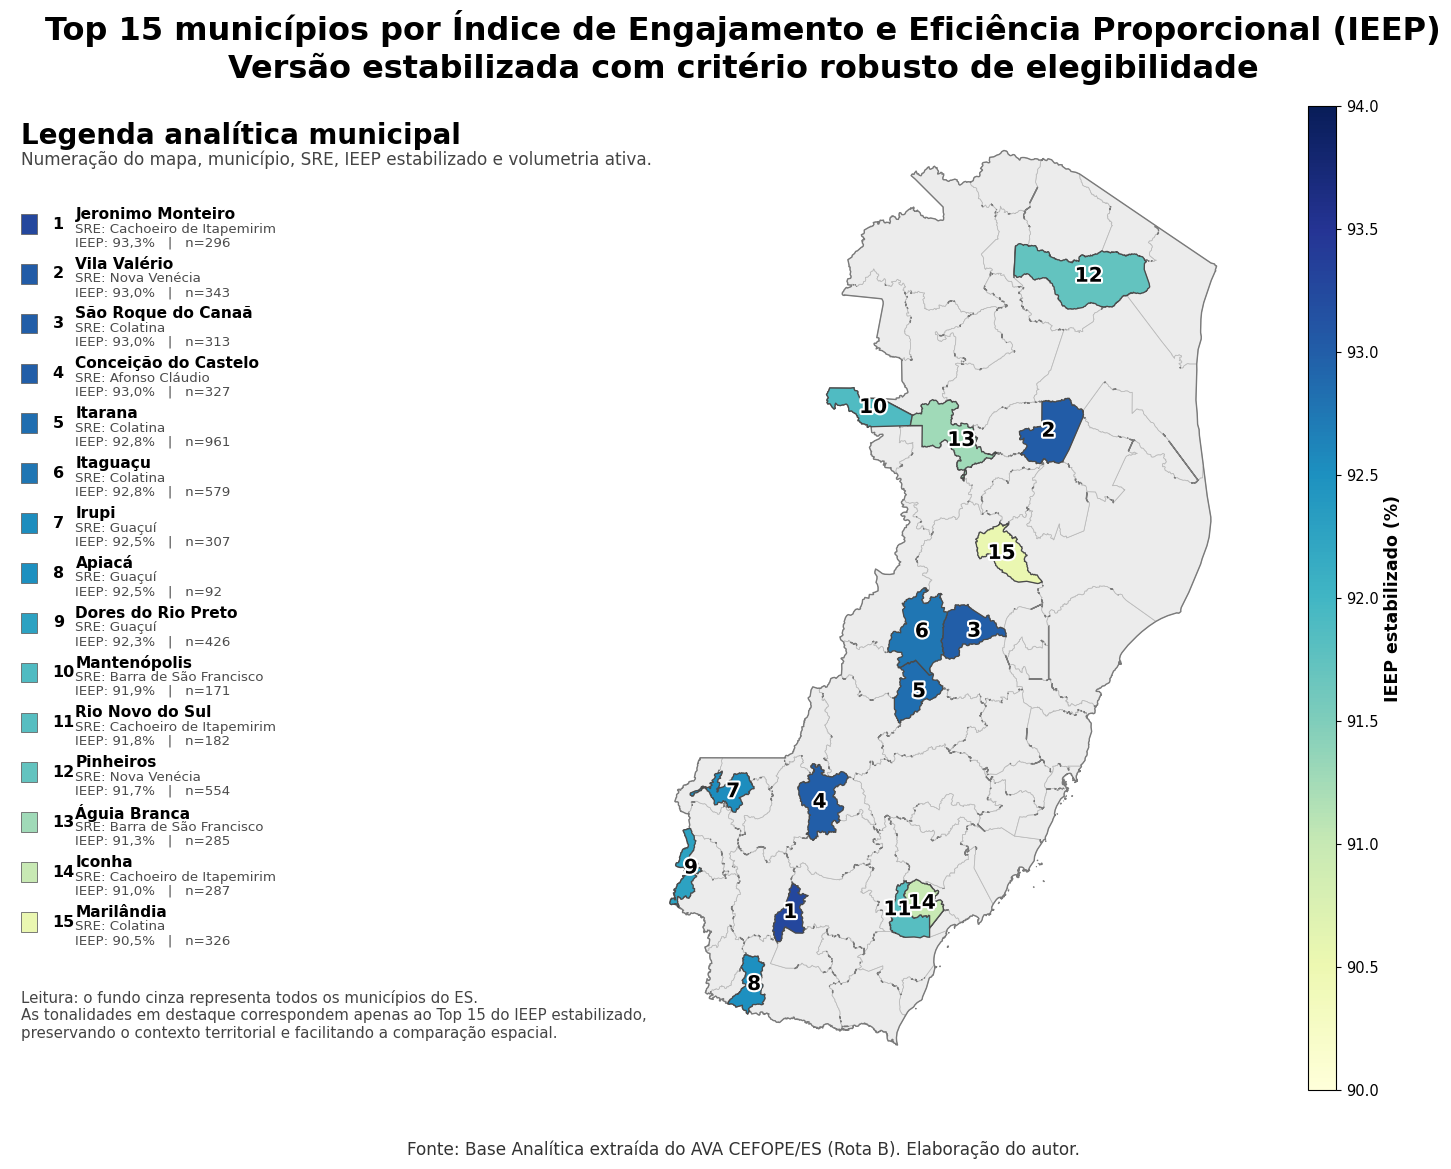

In [49]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe

from shapely.geometry import Polygon, MultiPolygon, GeometryCollection
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

ARQ_MALHA_MUNICIPAL = DIR_SAIDAS / "30_malha_municipal_ieep.gpkg"
ARQ_MUN_METRICAS = DIR_SAIDAS / "20_agregado_municipal_com_vies_robusto.parquet"

if not ARQ_MALHA_MUNICIPAL.exists():
    raise FileNotFoundError(f"Arquivo não encontrado: {ARQ_MALHA_MUNICIPAL}")

if not ARQ_MUN_METRICAS.exists():
    raise FileNotFoundError(f"Arquivo não encontrado: {ARQ_MUN_METRICAS}")

gdf_mun = gpd.read_file(ARQ_MALHA_MUNICIPAL).copy()
df_mun = pd.read_parquet(ARQ_MUN_METRICAS).copy()

for col in ["Municipio_padronizado", "SRE_padronizada"]:
    if col in gdf_mun.columns:
        gdf_mun[col] = gdf_mun[col].astype(str).str.strip().str.upper()
    if col in df_mun.columns:
        df_mun[col] = df_mun[col].astype(str).str.strip().str.upper()

def fmt_milhar(x):
    if pd.isna(x):
        return "N/D"
    return f"{int(round(x)):,}".replace(",", ".")

def fmt_pct_texto(x, casas=1):
    if pd.isna(x):
        return "N/D"
    return f"{x:.{casas}f}".replace(".", ",")

def titulo_municipio(nome):
    nome = str(nome).strip().title()
    substituicoes = {
        "Apiaca": "Apiacá",
        "Agua Branca": "Águia Branca",
        "Sao Roque Do Canaa": "São Roque do Canaã",
        "Conceicao Do Castelo": "Conceição do Castelo",
        "Rio Novo Do Sul": "Rio Novo do Sul",
        "Dores Do Rio Preto": "Dores do Rio Preto",
        "Joao Neiva": "João Neiva",
        "Vila Valerio": "Vila Valério",
        "Marilandia": "Marilândia",
        "Mantenopolis": "Mantenópolis",
        "Itaguacu": "Itaguaçu",
        "Iupi": "Irupi",
        "Piuma": "Piúma",
        "Aguia Branca": "Águia Branca",
        "Nova Venecia": "Nova Venécia",
        "Afonso Claudio": "Afonso Cláudio",
        "Guacui": "Guaçuí",
        "Sao Mateus": "São Mateus",
        "Vitoria": "Vitória",
        "Iconha": "Iconha",
        "Ibitirama": "Ibitirama",
    }
    return substituicoes.get(nome, nome)

def encurtar_sre(nome):
    nome = str(nome).replace("SRE ", "").title()
    substituicoes = {
        "Comendadora Jurema Moretz Sohn": "Guaçuí",
        "Afonso Claudio": "Afonso Cláudio",
        "Barra De Sao Francisco": "Barra de São Francisco",
        "Cachoeiro De Itapemirim": "Cachoeiro de Itapemirim",
        "Nova Venecia": "Nova Venécia",
        "Sao Mateus": "São Mateus",
    }
    return substituicoes.get(nome, nome)

def remover_fragmentos_offshore(geom, limite_x=-38.5):
    if geom is None or geom.is_empty:
        return geom

    if isinstance(geom, Polygon):
        return geom if geom.centroid.x <= limite_x else GeometryCollection()

    if isinstance(geom, MultiPolygon):
        partes_validas = [g for g in geom.geoms if g.centroid.x <= limite_x]
        if len(partes_validas) == 0:
            return GeometryCollection()
        if len(partes_validas) == 1:
            return partes_validas[0]
        return MultiPolygon(partes_validas)

    return geom

cols_merge = [
    "Municipio_padronizado",
    "SRE_padronizada",
    "n_ativos",
    "ieep_bruto",
    "ieep_estabilizado",
    "ieep_ic_amplitude",
    "n_docencia",
    "ieep_docencia",
    "n_gestao",
    "ieep_gestao",
    "vies_gestao_menos_docencia_pp",
    "menor_base_ocupacional",
    "abs_vies"
]
cols_merge = [c for c in cols_merge if c in df_mun.columns]

cols_drop = [c for c in cols_merge if c not in ["Municipio_padronizado", "SRE_padronizada"] and c in gdf_mun.columns]
if cols_drop:
    gdf_mun = gdf_mun.drop(columns=cols_drop)

gdf_mun = gdf_mun.merge(
    df_mun[cols_merge],
    on=["Municipio_padronizado", "SRE_padronizada"],
    how="left"
)

gdf_base_es = gdf_mun.copy()
gdf_base_es["geometry"] = gdf_base_es["geometry"].apply(remover_fragmentos_offshore)
gdf_base_es = gdf_base_es[gdf_base_es.geometry.notna()].copy()
gdf_base_es = gdf_base_es[~gdf_base_es.geometry.is_empty].copy()

gdf_top15 = (
    gdf_base_es[gdf_base_es["ieep_estabilizado"].notna()]
    .sort_values(["ieep_estabilizado", "n_ativos"], ascending=[False, False])
    .head(15)
    .copy()
)

gdf_top15["ieep_pct"] = gdf_top15["ieep_estabilizado"] * 100
gdf_top15["Municipio_curto"] = gdf_top15["Municipio_padronizado"].apply(titulo_municipio)
gdf_top15["SRE_curta"] = gdf_top15["SRE_padronizada"].apply(encurtar_sre)

df_leg = gdf_top15[
    ["Municipio_padronizado", "Municipio_curto", "SRE_curta", "n_ativos", "ieep_pct"]
].copy()

df_leg = df_leg.sort_values(["ieep_pct", "n_ativos"], ascending=[False, False]).reset_index(drop=True)
df_leg.insert(0, "num", range(1, len(df_leg) + 1))

gdf_top15 = gdf_top15.merge(
    df_leg[["Municipio_padronizado", "num"]],
    on="Municipio_padronizado",
    how="left"
)

print("-" * 78)
print("AUDITORIA")
print("-" * 78)
print(f"Municípios na base completa do ES: {len(gdf_base_es)}")
print(f"Municípios destacados no Top 15: {len(gdf_top15)}")

bounds = gdf_base_es.geometry.bounds
minx = bounds["minx"].min()
miny = bounds["miny"].min()
maxx = bounds["maxx"].max()
maxy = bounds["maxy"].max()

dx = (maxx - minx) * 0.07
dy = (maxy - miny) * 0.05

print("-" * 78)
print("Renderizando mapa municipal com legenda lateral ajustada...")
print("-" * 78)

fig = plt.figure(figsize=(15.6, 12.0), facecolor="white")

gs = fig.add_gridspec(
    1, 3,
    width_ratios=[1.60, 2.00, 0.08],
    left=0.03, right=0.88, top=0.90, bottom=0.08, wspace=0.02
)

ax_leg = fig.add_subplot(gs[0, 0])
ax_map = fig.add_subplot(gs[0, 1])
cax = fig.add_subplot(gs[0, 2])

gdf_base_es.plot(
    ax=ax_map,
    color="#ececec",
    edgecolor="#b9b9b9",
    linewidth=0.55,
    zorder=1
)

gdf_base_es.dissolve().boundary.plot(
    ax=ax_map,
    color="#7a7a7a",
    linewidth=1.0,
    zorder=2
)

cmap = plt.cm.YlGnBu
vmin = float(np.floor(gdf_top15["ieep_pct"].min()))
vmax = float(np.ceil(gdf_top15["ieep_pct"].max()))
norm = Normalize(vmin=vmin, vmax=vmax)

gdf_top15.plot(
    column="ieep_pct",
    cmap=cmap,
    ax=ax_map,
    linewidth=0.95,
    edgecolor="#4a4a4a",
    vmin=vmin,
    vmax=vmax,
    zorder=3
)

for _, row in gdf_top15.iterrows():
    if row.geometry is None or row.geometry.is_empty or pd.isna(row["num"]):
        continue

    p = row.geometry.representative_point()
    ax_map.text(
        p.x, p.y, str(int(row["num"])),
        ha="center", va="center",
        fontsize=14.5, fontweight="bold", color="black",
        path_effects=[pe.withStroke(linewidth=3.0, foreground="white")],
        zorder=4
    )

ax_map.set_xlim(minx - dx, maxx + dx)
ax_map.set_ylim(miny - dy, maxy + dy)
ax_map.axis("off")

sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = fig.colorbar(sm, cax=cax)
cbar.set_label("IEEP estabilizado (%)", fontsize=12.5, fontweight="bold")
cbar.ax.tick_params(labelsize=10.5)

ax_leg.axis("off")
ax_leg.set_xlim(0, 1)
ax_leg.set_ylim(0, 1)

ax_leg.text(
    0.02, 0.985,
    "Legenda analítica municipal",
    fontsize=20, fontweight="bold", ha="left", va="top"
)

ax_leg.text(
    0.02, 0.955,
    "Numeração do mapa, município, SRE, IEEP estabilizado e volumetria ativa.",
    fontsize=12.2, color="#444444", ha="left", va="top"
)

y_top = 0.88
y_bottom = 0.12
n_itens = len(df_leg)
step = (y_top - y_bottom) / n_itens

for i, (_, row) in enumerate(df_leg.iterrows()):
    y = y_top - i * step
    cor = cmap(norm(row["ieep_pct"]))

    # quadrado da cor
    ax_leg.add_patch(
        plt.Rectangle(
            (0.02, y - 0.010),
            0.028,
            0.020,
            facecolor=cor,
            edgecolor="#666666",
            linewidth=0.6
        )
    )

    # número
    ax_leg.text(
        0.075, y,
        f"{int(row['num'])}",
        fontsize=11.5,
        fontweight="bold",
        ha="left",
        va="center"
    )

    # linha 1: município
    ax_leg.text(
        0.115, y + 0.010,
        f"{row['Municipio_curto']}",
        fontsize=11.1,
        fontweight="bold",
        ha="left",
        va="center"
    )

    # linha 2: SRE
    ax_leg.text(
        0.115, y - 0.005,
        f"SRE: {row['SRE_curta']}",
        fontsize=9.6,
        color="#4b4b4b",
        ha="left",
        va="center"
    )

    # linha 3: IEEP e n
    ax_leg.text(
        0.115, y - 0.019,
        f"IEEP: {fmt_pct_texto(row['ieep_pct'])}%   |   n={fmt_milhar(row['n_ativos'])}",
        fontsize=9.6,
        color="#4b4b4b",
        ha="left",
        va="center"
    )

ax_leg.text(
    0.02, 0.05,
    "Leitura: o fundo cinza representa todos os municípios do ES.\n"
    "As tonalidades em destaque correspondem apenas ao Top 15 do IEEP estabilizado,\n"
    "preservando o contexto territorial e facilitando a comparação espacial.",
    fontsize=10.8, color="#444444", ha="left", va="bottom"
)

fig.suptitle(
    "Top 15 municípios por Índice de Engajamento e Eficiência Proporcional (IEEP)\n"
    "Versão estabilizada com critério robusto de elegibilidade",
    fontsize=23,
    fontweight="bold",
    y=0.98
)

fig.text(
    0.5, 0.03,
    "Fonte: Base Analítica extraída do AVA CEFOPE/ES (Rota B). Elaboração do autor.",
    ha="center", va="center", fontsize=12.2, color="#333333"
)

plt.show()


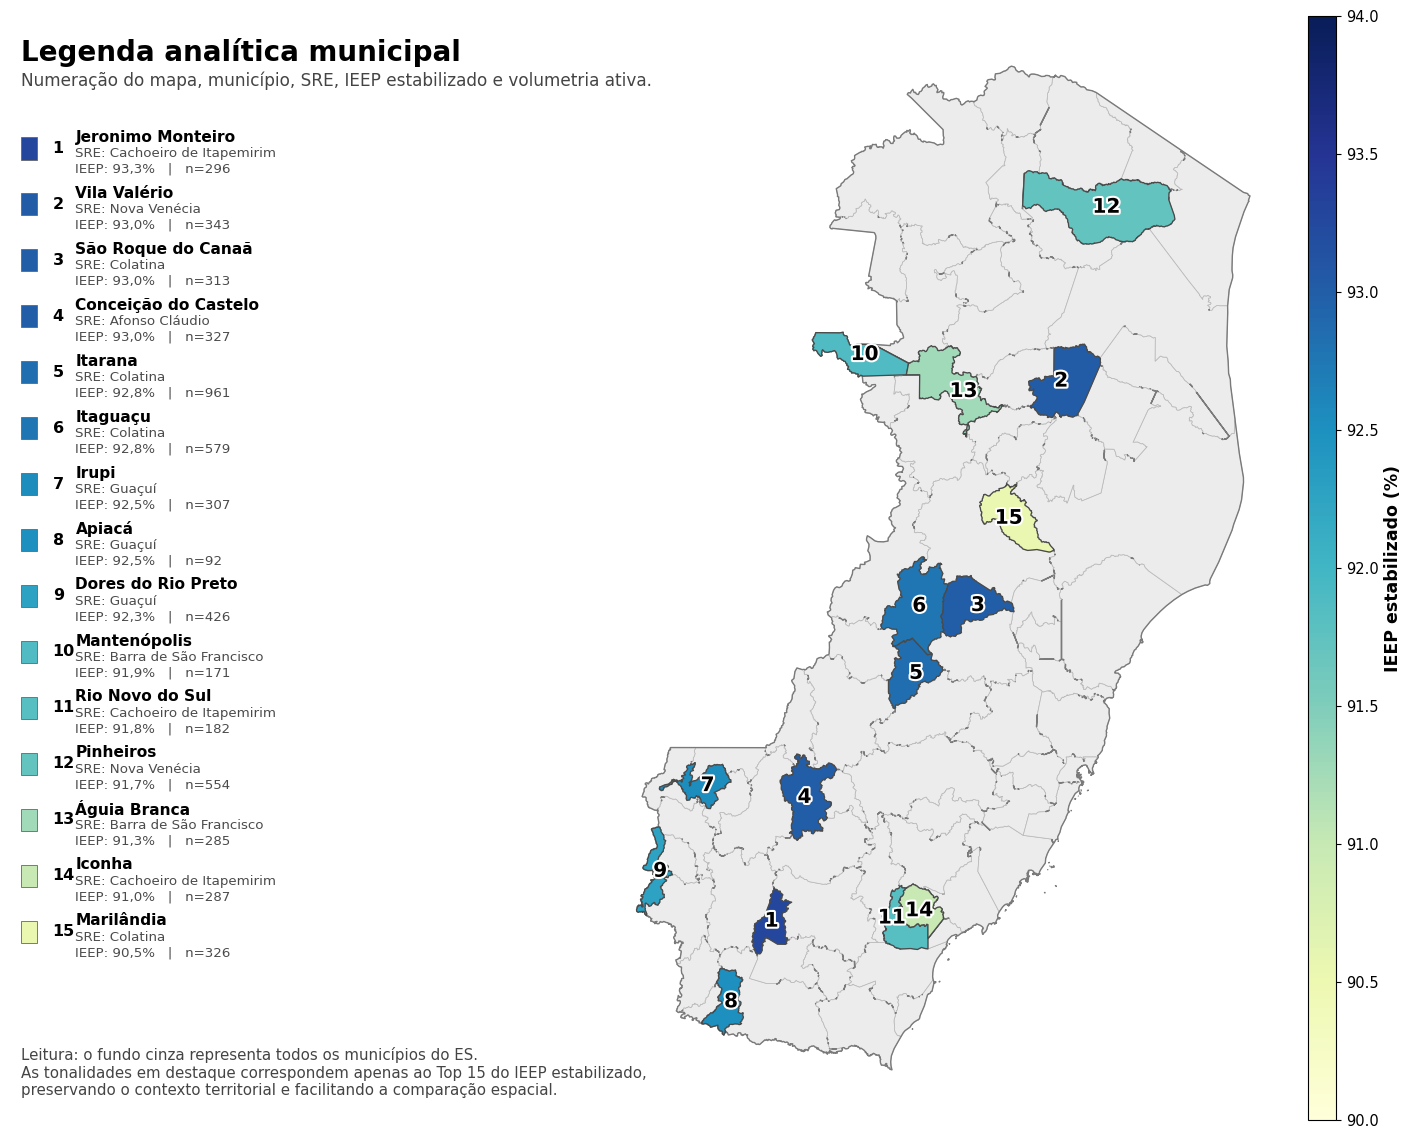

In [50]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe

from shapely.geometry import Polygon, MultiPolygon, GeometryCollection
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable


if not ARQ_MALHA_MUNICIPAL.exists():
    raise FileNotFoundError(f"Arquivo não encontrado: {ARQ_MALHA_MUNICIPAL}")

if not ARQ_MUN_METRICAS.exists():
    raise FileNotFoundError(f"Arquivo não encontrado: {ARQ_MUN_METRICAS}")

gdf_mun = gpd.read_file(ARQ_MALHA_MUNICIPAL).copy()
df_mun = pd.read_parquet(ARQ_MUN_METRICAS).copy()

for col in ["Municipio_padronizado", "SRE_padronizada"]:
    if col in gdf_mun.columns:
        gdf_mun[col] = gdf_mun[col].astype(str).str.strip().str.upper()
    if col in df_mun.columns:
        df_mun[col] = df_mun[col].astype(str).str.strip().str.upper()

def fmt_milhar(x):
    if pd.isna(x):
        return "N/D"
    return f"{int(round(x)):,}".replace(",", ".")

def fmt_pct_texto(x, casas=1):
    if pd.isna(x):
        return "N/D"
    return f"{x:.{casas}f}".replace(".", ",")

def titulo_municipio(nome):
    nome = str(nome).strip().title()
    substituicoes = {
        "Apiaca": "Apiacá",
        "Agua Branca": "Águia Branca",
        "Sao Roque Do Canaa": "São Roque do Canaã",
        "Conceicao Do Castelo": "Conceição do Castelo",
        "Rio Novo Do Sul": "Rio Novo do Sul",
        "Dores Do Rio Preto": "Dores do Rio Preto",
        "Joao Neiva": "João Neiva",
        "Vila Valerio": "Vila Valério",
        "Marilandia": "Marilândia",
        "Mantenopolis": "Mantenópolis",
        "Itaguacu": "Itaguaçu",
        "Iupi": "Irupi",
        "Piuma": "Piúma",
        "Aguia Branca": "Águia Branca",
        "Nova Venecia": "Nova Venécia",
        "Afonso Claudio": "Afonso Cláudio",
        "Guacui": "Guaçuí",
        "Sao Mateus": "São Mateus",
        "Vitoria": "Vitória",
        "Iconha": "Iconha",
        "Ibitirama": "Ibitirama",
    }
    return substituicoes.get(nome, nome)

def encurtar_sre(nome):
    nome = str(nome).replace("SRE ", "").title()
    substituicoes = {
        "Comendadora Jurema Moretz Sohn": "Guaçuí",
        "Afonso Claudio": "Afonso Cláudio",
        "Barra De Sao Francisco": "Barra de São Francisco",
        "Cachoeiro De Itapemirim": "Cachoeiro de Itapemirim",
        "Nova Venecia": "Nova Venécia",
        "Sao Mateus": "São Mateus",
    }
    return substituicoes.get(nome, nome)

def remover_fragmentos_offshore(geom, limite_x=-38.5):
    if geom is None or geom.is_empty:
        return geom

    if isinstance(geom, Polygon):
        return geom if geom.centroid.x <= limite_x else GeometryCollection()

    if isinstance(geom, MultiPolygon):
        partes_validas = [g for g in geom.geoms if g.centroid.x <= limite_x]
        if len(partes_validas) == 0:
            return GeometryCollection()
        if len(partes_validas) == 1:
            return partes_validas[0]
        return MultiPolygon(partes_validas)

    return geom

cols_merge = [
    "Municipio_padronizado",
    "SRE_padronizada",
    "n_ativos",
    "ieep_bruto",
    "ieep_estabilizado",
    "ieep_ic_amplitude",
    "n_docencia",
    "ieep_docencia",
    "n_gestao",
    "ieep_gestao",
    "vies_gestao_menos_docencia_pp",
    "menor_base_ocupacional",
    "abs_vies"
]
cols_merge = [c for c in cols_merge if c in df_mun.columns]

cols_drop = [c for c in cols_merge if c not in ["Municipio_padronizado", "SRE_padronizada"] and c in gdf_mun.columns]
if cols_drop:
    gdf_mun = gdf_mun.drop(columns=cols_drop)

gdf_mun = gdf_mun.merge(
    df_mun[cols_merge],
    on=["Municipio_padronizado", "SRE_padronizada"],
    how="left"
)

gdf_base_es = gdf_mun.copy()
gdf_base_es["geometry"] = gdf_base_es["geometry"].apply(remover_fragmentos_offshore)
gdf_base_es = gdf_base_es[gdf_base_es.geometry.notna()].copy()
gdf_base_es = gdf_base_es[~gdf_base_es.geometry.is_empty].copy()

gdf_top15 = (
    gdf_base_es[gdf_base_es["ieep_estabilizado"].notna()]
    .sort_values(["ieep_estabilizado", "n_ativos"], ascending=[False, False])
    .head(15)
    .copy()
)

gdf_top15["ieep_pct"] = gdf_top15["ieep_estabilizado"] * 100
gdf_top15["Municipio_curto"] = gdf_top15["Municipio_padronizado"].apply(titulo_municipio)
gdf_top15["SRE_curta"] = gdf_top15["SRE_padronizada"].apply(encurtar_sre)

df_leg = gdf_top15[
    ["Municipio_padronizado", "Municipio_curto", "SRE_curta", "n_ativos", "ieep_pct"]
].copy()

df_leg = df_leg.sort_values(["ieep_pct", "n_ativos"], ascending=[False, False]).reset_index(drop=True)
df_leg.insert(0, "num", range(1, len(df_leg) + 1))

gdf_top15 = gdf_top15.merge(
    df_leg[["Municipio_padronizado", "num"]],
    on="Municipio_padronizado",
    how="left"
)

bounds = gdf_base_es.geometry.bounds
minx = bounds["minx"].min()
miny = bounds["miny"].min()
maxx = bounds["maxx"].max()
maxy = bounds["maxy"].max()

dx = (maxx - minx) * 0.07
dy = (maxy - miny) * 0.05

fig = plt.figure(figsize=(15.6, 12.0), facecolor="white")

gs = fig.add_gridspec(
    1, 3,
    width_ratios=[1.60, 2.00, 0.08],
    left=0.03, right=0.88, top=0.96, bottom=0.04, wspace=0.02
)

ax_leg = fig.add_subplot(gs[0, 0])
ax_map = fig.add_subplot(gs[0, 1])
cax = fig.add_subplot(gs[0, 2])

gdf_base_es.plot(
    ax=ax_map,
    color="#ececec",
    edgecolor="#b9b9b9",
    linewidth=0.55,
    zorder=1
)

gdf_base_es.dissolve().boundary.plot(
    ax=ax_map,
    color="#7a7a7a",
    linewidth=1.0,
    zorder=2
)

cmap = plt.cm.YlGnBu
vmin = float(np.floor(gdf_top15["ieep_pct"].min()))
vmax = float(np.ceil(gdf_top15["ieep_pct"].max()))
norm = Normalize(vmin=vmin, vmax=vmax)

gdf_top15.plot(
    column="ieep_pct",
    cmap=cmap,
    ax=ax_map,
    linewidth=0.95,
    edgecolor="#4a4a4a",
    vmin=vmin,
    vmax=vmax,
    zorder=3
)

for _, row in gdf_top15.iterrows():
    if row.geometry is None or row.geometry.is_empty or pd.isna(row["num"]):
        continue

    p = row.geometry.representative_point()
    ax_map.text(
        p.x, p.y, str(int(row["num"])),
        ha="center", va="center",
        fontsize=14.5, fontweight="bold", color="black",
        path_effects=[pe.withStroke(linewidth=3.0, foreground="white")],
        zorder=4
    )

ax_map.set_xlim(minx - dx, maxx + dx)
ax_map.set_ylim(miny - dy, maxy + dy)
ax_map.axis("off")

sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = fig.colorbar(sm, cax=cax)
cbar.set_label("IEEP estabilizado (%)", fontsize=12.5, fontweight="bold")
cbar.ax.tick_params(labelsize=10.5)

ax_leg.axis("off") # Fundamental para não mostrar a caixa ao redor da legenda
ax_leg.set_xlim(0, 1)
ax_leg.set_ylim(0, 1)

ax_leg.text(
    0.02, 0.98,
    "Legenda analítica municipal",
    fontsize=20, fontweight="bold", ha="left", va="top"
)

ax_leg.text(
    0.02, 0.95,
    "Numeração do mapa, município, SRE, IEEP estabilizado e volumetria ativa.",
    fontsize=12.2, color="#444444", ha="left", va="top"
)

# Distribuindo os itens com mais respiro
y_top = 0.88
y_bottom = 0.12
n_itens = len(df_leg)
step = (y_top - y_bottom) / n_itens

for i, (_, row) in enumerate(df_leg.iterrows()):
    y = y_top - i * step
    cor = cmap(norm(row["ieep_pct"]))

    # quadrado da cor
    ax_leg.add_patch(
        plt.Rectangle(
            (0.02, y - 0.010),
            0.028,
            0.020,
            facecolor=cor,
            edgecolor="#666666",
            linewidth=0.6
        )
    )

    # número
    ax_leg.text(
        0.075, y,
        f"{int(row['num'])}",
        fontsize=11.5,
        fontweight="bold",
        ha="left",
        va="center"
    )

    # linha 1: município
    ax_leg.text(
        0.115, y + 0.010,
        f"{row['Municipio_curto']}",
        fontsize=11.1,
        fontweight="bold",
        ha="left",
        va="center"
    )

    # linha 2: SRE
    ax_leg.text(
        0.115, y - 0.005,
        f"SRE: {row['SRE_curta']}",
        fontsize=9.6,
        color="#4b4b4b",
        ha="left",
        va="center"
    )

    # linha 3: IEEP e n
    ax_leg.text(
        0.115, y - 0.019,
        f"IEEP: {fmt_pct_texto(row['ieep_pct'])}%   |   n={fmt_milhar(row['n_ativos'])}",
        fontsize=9.6,
        color="#4b4b4b",
        ha="left",
        va="center"
    )

ax_leg.text(
    0.02, 0.02,
    "Leitura: o fundo cinza representa todos os municípios do ES.\n"
    "As tonalidades em destaque correspondem apenas ao Top 15 do IEEP estabilizado,\n"
    "preservando o contexto territorial e facilitando a comparação espacial.",
    fontsize=10.8, color="#444444", ha="left", va="bottom"
)

plt.show()

In [51]:
from pathlib import Path
import pandas as pd

print("=" * 78)
print("ARQUIVOS DISPONÍVEIS EM DIR_SAIDAS")
print("=" * 78)

if "DIR_SAIDAS" not in globals():
    raise NameError(
        "A variável DIR_SAIDAS não está definida no notebook. "
        "Execute antes a célula de setup."
    )

dir_saidas = Path(DIR_SAIDAS)

if not dir_saidas.exists():
    raise FileNotFoundError(f"Diretório não encontrado: {dir_saidas}")

arquivos = []
for arq in sorted(dir_saidas.rglob("*")):
    if arq.is_file():
        try:
            tamanho_kb = arq.stat().st_size / 1024
        except Exception:
            tamanho_kb = None

        arquivos.append({
            "nome_arquivo": arq.name,
            "caminho_completo": str(arq),
            "extensao": arq.suffix.lower(),
            "tamanho_kb": round(tamanho_kb, 2) if tamanho_kb is not None else None
        })

df_arquivos = pd.DataFrame(arquivos)

if df_arquivos.empty:
    print("Nenhum arquivo encontrado em DIR_SAIDAS.")
else:
    print(f"Total de arquivos encontrados: {len(df_arquivos)}")
    print("-" * 78)
    display(df_arquivos)

    print("-" * 78)
    print("ARQUIVOS AGRUPADOS POR EXTENSÃO")
    print("-" * 78)
    display(
        df_arquivos.groupby("extensao", dropna=False)
        .size()
        .reset_index(name="quantidade")
        .sort_values(["quantidade", "extensao"], ascending=[False, True])
        .reset_index(drop=True)
    )

arq_inventario = dir_saidas / "inventario_arquivos_saida_notebook.csv"
df_arquivos.to_csv(arq_inventario, index=False, encoding="utf-8-sig")

print("-" * 78)
print("Inventário salvo em:")
print(f"- {arq_inventario}")

ARQUIVOS DISPONÍVEIS EM DIR_SAIDAS
Total de arquivos encontrados: 39
------------------------------------------------------------------------------


,nome_arquivo,caminho_completo,extensao,tamanho_kb
0,01_base_rota_b_elegivel_geoespacial.parquet,/content/dados_output/01_base_rota_b_elegivel_...,.parquet,3533.31
1,02_agregado_municipal_bruto.parquet,/content/dados_output/02_agregado_municipal_br...,.parquet,6.50
2,03_agregado_sre_bruto.parquet,/content/dados_output/03_agregado_sre_bruto.pa...,.parquet,3.31
3,04_base_residual_nao_cartografavel.parquet,/content/dados_output/04_base_residual_nao_car...,.parquet,149.32
4,05_base_territorial_valida.parquet,/content/dados_output/05_base_territorial_vali...,.parquet,3421.52
5,06_agregado_municipal_limpo.parquet,/content/dados_output/06_agregado_municipal_li...,.parquet,6.23
6,07_agregado_sre_limpo.parquet,/content/dados_output/07_agregado_sre_limpo.pa...,.parquet,3.27
7,08_agregado_municipal_com_metricas.parquet,/content/dados_output/08_agregado_municipal_co...,.parquet,12.35
8,09_agregado_sre_com_metricas.parquet,/content/dados_output/09_agregado_sre_com_metr...,.parquet,5.97
9,10_analise_sensibilidade_limiares.csv,/content/dados_output/10_analise_sensibilidade...,.csv,0.76


------------------------------------------------------------------------------
ARQUIVOS AGRUPADOS POR EXTENSÃO
------------------------------------------------------------------------------


,extensao,quantidade
0,.parquet,16
1,.csv,13
2,.png,3
3,.gpkg,2
4,.html,2
5,.txt,2
6,.tex,1


------------------------------------------------------------------------------
Inventário salvo em:
- /content/dados_output/inventario_arquivos_saida_notebook.csv


In [52]:
from pathlib import Path
import pandas as pd

print("=" * 78)
print("ARQUIVOS-CHAVE PARA A REDAÇÃO DA SUBSEÇÃO FINAL")
print("=" * 78)

base = Path(DIR_SAIDAS)

arquivos = {
    "tabela_sre_csv": base / "22_tabela_executiva_sre.csv",
    "municipios_robusto_parquet": base / "20_agregado_municipal_com_vies_robusto.parquet",
    "sensibilidade_csv": base / "10_analise_sensibilidade_limiares.csv",
    "top15_vies_robusto_csv": base / "21_top15_municipios_vies_robusto.csv",
    "top5_sre_csv": base / "24_top5_sre_ieep_estabilizado.csv",
    "tabela_top15_tex": base / "41_tabela_ieep_municipios_estabilizado_top15.tex",
    "consolidacao_txt": base / "23_consolidacao_interpretativa_final.txt",
}

for nome, caminho in arquivos.items():
    print("-" * 78)
    print(f"{nome}: {caminho.name}")
    print("-" * 78)

    if not caminho.exists():
        print("Arquivo não encontrado.")
        continue

    if caminho.suffix == ".csv":
        df = pd.read_csv(caminho)
        display(df)

    elif caminho.suffix == ".parquet":
        df = pd.read_parquet(caminho)
        print("Colunas disponíveis:")
        print(df.columns.tolist())
        print("\nAmostra:")
        display(df.head(20))

        print("\nTop 15 por ieep_estabilizado (se a coluna existir):")
        if "ieep_estabilizado" in df.columns:
            cols_show = [c for c in [
                "Municipio_padronizado", "SRE_padronizada", "n_ativos",
                "ieep_bruto", "ieep_estabilizado", "ieep_ic_amplitude",
                "n_docencia", "ieep_docencia", "n_gestao", "ieep_gestao",
                "vies_gestao_menos_docencia_pp", "menor_base_ocupacional", "abs_vies"
            ] if c in df.columns]
            display(df.sort_values("ieep_estabilizado", ascending=False)[cols_show].head(15))

    elif caminho.suffix == ".txt":
        with open(caminho, "r", encoding="utf-8") as f:
            print(f.read())

    elif caminho.suffix == ".tex":
        with open(caminho, "r", encoding="utf-8") as f:
            print(f.read())

ARQUIVOS-CHAVE PARA A REDAÇÃO DA SUBSEÇÃO FINAL
------------------------------------------------------------------------------
tabela_sre_csv: 22_tabela_executiva_sre.csv
------------------------------------------------------------------------------


,SRE_padronizada,n_ativos,ieep_bruto,ieep_estabilizado,ieep_ic_amplitude,n_docencia,ieep_docencia,n_gestao,ieep_gestao,vies_gestao_menos_docencia_pp,patamar_ieep,grau_incerteza,leitura_vies_ocupacional,leitura_sintetica
0,SRE COLATINA,4454,0.896947,0.896764,0.017863,2903,0.904237,786,0.874046,-3.019119,Excelência territorial elevada,Baixa incerteza,Gestão abaixo da Docência,SRE COLATINA apresenta IEEP estabilizado de 89...
1,SRE NOVA VENECIA,3699,0.892674,0.892457,0.019956,2083,0.901104,611,0.844517,-5.658699,Excelência territorial elevada,Baixa incerteza,Gestão abaixo da Docência,SRE NOVA VENECIA apresenta IEEP estabilizado d...
2,SRE BARRA DE SAO FRANCISCO,2134,0.888941,0.888572,0.026675,1330,0.890977,304,0.871711,-1.926692,Excelência territorial intermediária-alta,Incerteza moderada,Equilíbrio relativo entre grupos,SRE BARRA DE SAO FRANCISCO apresenta IEEP esta...
3,SRE AFONSO CLAUDIO,2678,0.885362,0.885072,0.024140,1565,0.879233,518,0.888031,0.879766,Excelência territorial intermediária-alta,Incerteza moderada,Equilíbrio relativo entre grupos,SRE AFONSO CLAUDIO apresenta IEEP estabilizado...
4,SRE COMENDADORA JUREMA MORETZ SOHN,3203,0.883859,0.883617,0.022197,1845,0.879675,444,0.873874,-0.580092,Excelência territorial intermediária-alta,Incerteza moderada,Equilíbrio relativo entre grupos,SRE COMENDADORA JUREMA MORETZ SOHN apresenta I...
5,SRE CACHOEIRO DE ITAPEMIRIM,4902,0.878417,0.878263,0.018299,2619,0.887362,941,0.867163,-2.019900,Excelência territorial intermediária-alta,Baixa incerteza,Gestão abaixo da Docência,SRE CACHOEIRO DE ITAPEMIRIM apresenta IEEP est...
6,SRE SAO MATEUS,2466,0.875507,0.875204,0.026066,1414,0.876945,416,0.843750,-3.319484,Excelência territorial intermediária-alta,Incerteza moderada,Gestão abaixo da Docência,SRE SAO MATEUS apresenta IEEP estabilizado de ...
7,SRE CARAPINA,3009,0.868395,0.868153,0.024161,1413,0.861996,451,0.784922,-7.707336,Excelência territorial intermediária,Incerteza moderada,Gestão abaixo da Docência,SRE CARAPINA apresenta IEEP estabilizado de 86...
8,SRE LINHARES,3154,0.867153,0.866924,0.023693,1722,0.876887,570,0.833333,-4.355401,Excelência territorial intermediária,Incerteza moderada,Gestão abaixo da Docência,SRE LINHARES apresenta IEEP estabilizado de 86...
9,SRE VILA VELHA,2715,0.849355,0.849109,0.026909,1181,0.848434,577,0.814558,-3.387547,Excelência territorial relativamente baixa,Incerteza moderada,Gestão abaixo da Docência,SRE VILA VELHA apresenta IEEP estabilizado de ...


------------------------------------------------------------------------------
municipios_robusto_parquet: 20_agregado_municipal_com_vies_robusto.parquet
------------------------------------------------------------------------------
Colunas disponíveis:
['Municipio_padronizado', 'SRE_padronizada', 'n_ativos', 'n_excelencia', 'ieep_bruto', 'ieep_ic_inf', 'ieep_ic_sup', 'ieep_ic_amplitude', 'ieep_estabilizado', 'flg_elegivel_mapa', 'flg_elegivel_hotspot', 'n_docencia', 'n_docencia_excelencia', 'ieep_docencia', 'n_gestao', 'n_gestao_excelencia', 'ieep_gestao', 'vies_gestao_menos_docencia_pp', 'flg_vies_robusto', 'menor_base_ocupacional']

Amostra:


,Municipio_padronizado,SRE_padronizada,n_ativos,n_excelencia,ieep_bruto,ieep_ic_inf,ieep_ic_sup,ieep_ic_amplitude,ieep_estabilizado,flg_elegivel_mapa,flg_elegivel_hotspot,n_docencia,n_docencia_excelencia,ieep_docencia,n_gestao,n_gestao_excelencia,ieep_gestao,vies_gestao_menos_docencia_pp,flg_vies_robusto,menor_base_ocupacional
0,AFONSO CLAUDIO,SRE AFONSO CLAUDIO,509,450,0.884086,0.853355,0.909064,0.055710,0.882574,True,True,282,251,0.890071,110,95,0.863636,-2.643456,True,110
1,AGUA DOCE DO NORTE,SRE BARRA DE SAO FRANCISCO,322,283,0.878882,0.838709,0.910121,0.071412,0.876547,True,True,209,186,0.889952,44,39,0.886364,-0.358852,True,44
2,AGUIA BRANCA,SRE BARRA DE SAO FRANCISCO,285,261,0.915789,0.877760,0.942759,0.064999,0.912770,True,True,226,207,0.915929,33,30,0.909091,-0.683829,True,33
3,ALEGRE,SRE COMENDADORA JUREMA MORETZ SOHN,383,312,0.814621,0.772646,0.850348,0.077701,0.813155,True,True,162,129,0.796296,70,58,0.828571,3.227513,True,70
4,ALFREDO CHAVES,SRE VILA VELHA,298,266,0.892617,0.852338,0.922903,0.070565,0.889959,True,True,139,125,0.899281,63,54,0.857143,-4.213772,True,63
5,ALTO RIO NOVO,SRE COLATINA,116,103,0.887931,0.817666,0.933327,0.115661,0.881325,True,True,65,59,0.907692,21,16,0.761905,-14.578755,False,21
6,ANCHIETA,SRE VILA VELHA,413,353,0.854722,0.817467,0.885438,0.067971,0.853071,True,True,193,168,0.870466,76,68,0.894737,2.427052,True,76
7,APIACA,SRE COMENDADORA JUREMA MORETZ SOHN,92,86,0.934783,0.864942,0.969770,0.104828,0.925028,True,True,43,40,0.930233,7,7,1.000000,6.976744,False,7
8,ARACRUZ,SRE LINHARES,675,580,0.859259,0.830987,0.883465,0.052478,0.858227,True,True,290,246,0.848276,137,113,0.824818,-2.345834,True,137
9,ATILIO VIVACQUA,SRE CACHOEIRO DE ITAPEMIRIM,254,223,0.877953,0.831972,0.912672,0.080700,0.875010,True,True,138,127,0.920290,41,36,0.878049,-4.224107,True,41



Top 15 por ieep_estabilizado (se a coluna existir):


...

------------------------------------------------------------------------------
top15_vies_robusto_csv: 21_top15_municipios_vies_robusto.csv
------------------------------------------------------------------------------


,Municipio_padronizado,SRE_padronizada,n_ativos,ieep_estabilizado,n_docencia,ieep_docencia,n_gestao,ieep_gestao,vies_gestao_menos_docencia_pp,menor_base_ocupacional,abs_vies
0,RIO BANANAL,SRE LINHARES,230,0.879303,160,0.918750,35,0.742857,-17.589286,35,17.589286
1,CONCEICAO DA BARRA,SRE SAO MATEUS,325,0.856334,193,0.886010,57,0.754386,-13.162440,57,13.162440
2,DORES DO RIO PRETO,SRE COMENDADORA JUREMA MORETZ SOHN,426,0.922792,329,0.948328,45,0.822222,-12.610605,45,12.610605
3,MUQUI,SRE CACHOEIRO DE ITAPEMIRIM,226,0.872828,124,0.870968,45,0.977778,10.681004,45,10.681004
4,PIUMA,SRE VILA VELHA,397,0.902194,143,0.923077,40,0.825000,-9.807692,40,9.807692
5,MARECHAL FLORIANO,SRE CARIACICA,211,0.868587,123,0.918699,34,0.823529,-9.516978,34,9.516978
6,VIANA,SRE CARIACICA,219,0.805755,123,0.837398,47,0.744681,-9.271752,47,9.271752
7,JERONIMO MONTEIRO,SRE CACHOEIRO DE ITAPEMIRIM,296,0.932701,185,0.962162,39,0.871795,-9.036729,39,9.036729
8,NOVA VENECIA,SRE NOVA VENECIA,589,0.859591,341,0.894428,143,0.804196,-9.023235,143,9.023235
9,MARILANDIA,SRE COLATINA,326,0.905403,222,0.914414,40,0.825000,-8.941441,40,8.941441


------------------------------------------------------------------------------
top5_sre_csv: 24_top5_sre_ieep_estabilizado.csv
------------------------------------------------------------------------------


,SRE_padronizada,n_ativos,ieep_bruto,ieep_estabilizado,ieep_ic_amplitude,n_docencia,ieep_docencia,n_gestao,ieep_gestao,vies_gestao_menos_docencia_pp,patamar_ieep,grau_incerteza,leitura_vies_ocupacional,leitura_sintetica
0,SRE COLATINA,4454,0.896947,0.896764,0.017863,2903,0.904237,786,0.874046,-3.019119,Excelência territorial elevada,Baixa incerteza,Gestão abaixo da Docência,SRE COLATINA apresenta IEEP estabilizado de 89...
1,SRE NOVA VENECIA,3699,0.892674,0.892457,0.019956,2083,0.901104,611,0.844517,-5.658699,Excelência territorial elevada,Baixa incerteza,Gestão abaixo da Docência,SRE NOVA VENECIA apresenta IEEP estabilizado d...
2,SRE BARRA DE SAO FRANCISCO,2134,0.888941,0.888572,0.026675,1330,0.890977,304,0.871711,-1.926692,Excelência territorial intermediária-alta,Incerteza moderada,Equilíbrio relativo entre grupos,SRE BARRA DE SAO FRANCISCO apresenta IEEP esta...
3,SRE AFONSO CLAUDIO,2678,0.885362,0.885072,0.024140,1565,0.879233,518,0.888031,0.879766,Excelência territorial intermediária-alta,Incerteza moderada,Equilíbrio relativo entre grupos,SRE AFONSO CLAUDIO apresenta IEEP estabilizado...
4,SRE COMENDADORA JUREMA MORETZ SOHN,3203,0.883859,0.883617,0.022197,1845,0.879675,444,0.873874,-0.580092,Excelência territorial intermediária-alta,Incerteza moderada,Equilíbrio relativo entre grupos,SRE COMENDADORA JUREMA MORETZ SOHN apresenta I...


------------------------------------------------------------------------------
tabela_top15_tex: 41_tabela_ieep_municipios_estabilizado_top15.tex
------------------------------------------------------------------------------
Arquivo não encontrado.
------------------------------------------------------------------------------
consolidacao_txt: 23_consolidacao_interpretativa_final.txt
------------------------------------------------------------------------------
A análise geoespacial robusta da Rota B confirmou que a distribuição territorial do engajamento e eficiência proporcional
não é homogênea no estado. Considerando o IEEP estabilizado como métrica principal, a SRE com melhor
desempenho relativo foi SRE COLATINA, com 89.68%,
enquanto a menor taxa foi observada em SRE CARIACICA, com 83.13%.

Do ponto de vista da precisão estatística, a maior incerteza foi registrada em
SRE CARIACICA, cuja amplitude do intervalo de confiança atingiu
3.84 pontos percentuais. Em contrapartida, as SREs 